# 🛡️ Silent Killer — Combined Defence Notebook v3.1 + v4.1 patch (Baseline · FT · ANP · ANP+FT · NAD · BaEraser-lite)

**Attack:** Silent Killer (clean-label, additive full-image trigger, ε = 16/255) · **source → target:** cat (3) → airplane (0)
**Model:** ResNet-18 (CIFAR stem) · **Dataset:** CIFAR-10 · **Seed:** 2027
Checkpoints: `silentkiller_{pr005, pr01, pr05, pr10}_seed2027.pth` under `DRIVE_ROOT` (controlled by `RUN_TAGS`; **starts with `pr01` only = smoke test**).

Requires the *latest* `defenses/nad.py` (v3) and `defenses/baeraser_lite.py` (v3 + the SK operator fix shipped with this notebook). If the repo copy of `baeraser_lite.py` predates the SK operator fix, the notebook falls back to an equivalent local operator and says so.

---
## Protocol (shared with the Blended v2 notebooks)

| Item | Rule |
|---|---|
| **Evaluation split** | CIFAR-10 *test* set → stratified **2,500 validation / 7,500 report** (`BL.split_test_set`). Poisoned victims saw all 50 k train images, so the defence budget must **not** come from train |
| **Defence budget** | The 2,500 validation images → **2,000 defence-train + 500 selection** (`select` slice). `defense_indices.npy` (train indices) is therefore **not** used for defending |
| **Report numbers** | CA / `ASR_src` / `ASR_all` are computed on the **7,500 report half only**. The reproduction gate alone uses the full 10 k test set (to compare with the attack notebook) |
| **ASR definitions** | `ASR_src` = cat + δ → airplane (SK's own metric, **primary**; ≈750 report cats). `ASR_all` = `asr_test_idx ∩ report` + δ → airplane (project-wide protocol) |
| **Selection** | FT: early stopping on the selection slice (patience 3, best epoch restored); **ANP**: rule `val_ca` — largest threshold whose *selection-slice* CA drop ≤ `MAX_CA_DROP_PP − ANP_SELECT_CA_MARGIN_PP` (**no trigger knowledge**); an ASR rule on the validation half is computed too and shown only as an *ORACLE-VAL upper bound*. **NAD**: teacher lr / collapse gate / student (lr × β-scale) chosen from held-out CA on the selection slice; ASR columns are diagnostics only. **BaEraser**: non-oracle selection (held-out CA floor → proxy ASR → optional fresh-trigger re-rank); the select-slice CA gate is tightened by `CA_SELECT_MARGIN`; real ASR at the *selected* epoch is the headline, the oracle epoch is separate |
| **BaEraser details** | No warm start / chaining (fresh generator+MINE per ε, verified); target-class images excluded from recovery and unlearning; model taken from `result.model`; fresh-recovery audit + universal-perturbation check on poisoned / sanitised / **clean** models; clean-model control; recovery + selection + audit cost counted |
| **Normalisation** | SK's own training-time normaliser (first-256-train-image stats), recomputed and asserted; also injected into `BL.CIFAR_MEAN/STD` and `nad.NORM_MEAN/STD` (NAD's black-pad value depends on it) |
| **Cost** | NAD = lr-search + teacher FT + student sweep + distillation; BaEraser = recovery (+ relaxed pass if any) + unlearning + selection audits + sanitised-model audit; FT/ANP = wall-clock of the run |

## v3.1 changes carried over from the Blended notebooks

| Change | Why |
|---|---|
| ANP threshold by **`val_ca` rule** (no trigger knowledge), finer 0.01 grid in 0.20–0.50, gate tightened by `ANP_SELECT_CA_MARGIN_PP` (500-image slice ≈ ±1 pp noise); **report-half budget-violation flag**; ASR-based choice kept only as *ORACLE-VAL upper bound* | v2 selected on a trigger-aware signal; a noisy slice let a run lose >5 pp on the report half |
| New row **ANP + FT ("Prune + FT")**: pruned channels held at zero while fine-tuning (augmented defence-train, lr 0.005) | fair comparator for NAD-style recipes |
| **FT early-stops on the selection slice** (was: fixed epochs); matched FT (NAD recipe) stays the fair FT baseline | plain FT memorised the 2,000 images |
| **NAD**: weight-hash proof that student ≠ teacher (else the run is invalid); labelled *not interpretable* when the teacher is still backdoored | rules out "NAD did nothing" and "teacher already clean" misreads |
| **BaEraser**: select-slice CA gate = tolerance − `CA_SELECT_MARGIN` (1 pp); `fresh_init_verified` asserted; audits use a separate seed and the universal-perturbation check runs on the **report half**; every saved checkpoint is **reload-verified** | same noise argument; independence of audits; no silent save/load drift |
| **Per-class accuracy + clean-image airplane-prediction rate** (new cell F2) | is a low ASR just "the model stopped predicting airplane"? |
| **STRIP** 500 + 500 samples + AUROC; **Grad-CAM** target = the image's *true* label for clean *and* triggered, 200 images, bootstrap 95 % CI | removes the predicted-class confound; tighter estimates |
| Test-split **hash printed and cross-checked** against split files of the other notebooks; sha256 of `nad.py` / `baeraser_lite.py` printed (optionally pinned) | proves all notebooks use the identical report half and the intended repo files |
| Outputs go to `defense_v3/` | never mix with v2 files |

## v4.1 changes (patch on the executed v4 run)

| # | Change | Why |
|---|---|---|
| 1 | **NAD student sweep is cached.** Every (student lr × β-scale) cell is trained once with `nad.run_nad`, scored on the selection slice and its weights are kept. The reported student *is* the selected cached model (rule: among cells that pass the 5 pp held-out gate, largest β-scale, then largest lr). `NAD_REPRO_CHECK` re-trains the chosen cell once and records whether it is bit-identical. A `recipe_version` in each sidecar means older NAD / matched-FT artefacts are moved aside (`*.superseded_*`, never deleted) and rebuilt | In v4 the final student was a *re-training* of the sweep's chosen setting. At pr05 that re-run landed outside the CA gate (selection-slice CA 0.896 → 0.822) and the run was recorded as `NAD_INVALID_RUN` |
| 2 | **Defences on the CLEAN model (D3b).** NAD and matched FT run on `resnet18_clean_seed2027.pth`. Verdicts compare with *the clean model under the same defence*; new columns `clean_same_defence_ASR_src`, `residual_vs_clean_same_defence_pp`, `generic_transfer_drop_pp` | "ASR below the 68 % floor" can come from generic perturbation robustness of the recipe (augmentation + high lr), not from removing the backdoor. Only the residual is attributable to the backdoor |
| 3 | **AC inputs (B5, G1).** B5 locates and validates `silentkiller_poison_idx/pixels_{tag}.npy` before the long run (exact names first; a searched candidate is used only if it passes clean-label / count / shape checks). G1 reports AC under **both** groupings — `predicted` (original `AC_*` columns) and `label` (`AC_LBL_*`) — and prints them next to the attack notebook's reference | pr01 AC was missing; baseline AC here (pr05 PDR ≈ 99 %) differs from the attack notebook (≈ 69–76 %), and the class grouping is the first thing to check |
| – | Re-running D0 no longer wipes `RESULTS` / `CKPT_REGISTRY` / `INFOS` | a patched `run_or_load` / `verdict` can be loaded into a live runtime without redoing finished defences |

## What is SK-specific (why Blended/BadNets settings were not copied)

1. **Normaliser** differs from CIFAR constants (item above).
2. **Trigger operator**: shipped `SilentKillerTriggerOperator` read the generator's sigmoid output as δ (one-sided, up to +255/255). Fixed: `δ = (2t−1)·ε` (`linf=` mode), verified numerically against the attack's `inject()`.
3. **Source-specific + transferable**: 2 poisoned samples already give 97 % ASR; the trigger was crafted on a surrogate. The **clean-baseline ASR is the achievable floor** (not 0 %), and recovered triggers reaching 80 % do not by themselves prove a backdoor → clean-model control.
4. **Threat model**: defender is told the trigger family and ε = 16/255 (analogue of α for Blended). The true δ is used for *evaluation/diagnostics only*.
5. **NAD**: lr is selected by the new defender-side routines (the paper's 0.1 collapsed the Blended teacher to 36–50 % CA).

## Sections
A setup · B data/split/loaders/baseline/controls · C `SKOperator` · D defences (FT, ANP, NAD, BaEraser + controls) · E master results · F STRIP + Grad-CAM verification · **G post-defence controller record (AC, STRIP μ/σ/threshold/TPR/FPR, costs, …)** · **H image visualisations** · I metadata + conclusions

## Section A — Setup

In [1]:
import requests
from pathlib import Path
import hashlib

url = "https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/resolve/main/cifar-10-python.tar.gz"
path = Path("/content/cifar-10-python.tar.gz")

with requests.get(url, stream=True, timeout=60) as r:
    r.raise_for_status()
    with open(path, "wb") as f:
        for chunk in r.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

md5 = hashlib.md5(path.read_bytes()).hexdigest()
print("Size:", path.stat().st_size, "bytes")
print("MD5:", md5)
print("Valid:", md5 == "c58f30108f718f92721af3b95e74349a")

Size: 170498071 bytes
MD5: c58f30108f718f92721af3b95e74349a
Valid: True


In [2]:
import tarfile
import os

DATA_ROOT = "/content/cifar10_cache"
os.makedirs(DATA_ROOT, exist_ok=True)

with tarfile.open("/content/cifar-10-python.tar.gz", "r:gz") as tar:
    tar.extractall(DATA_ROOT)

print(os.path.isdir(f"{DATA_ROOT}/cifar-10-batches-py"))

/tmp/ipykernel_603/911608324.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(DATA_ROOT)


True


In [3]:
# !tar -xzf ./data/cifar-10-python.tar.gz -C ./data

In [4]:
# import os
# DATA_ROOT  = '/content/data'

# print("DATA_ROOT:", DATA_ROOT)
# print("Extracted folder exists:",
#       os.path.isdir(os.path.join(DATA_ROOT, 'cifar-10-batches-py')))

In [5]:
# ════════════════════════════════════════════════════════════════════════
# Cell A1 — Environment, repository, paths
# ════════════════════════════════════════════════════════════════════════
import os, sys, json, time, copy, math, gc, random, shutil, subprocess, importlib, importlib.util, warnings
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

QUICK = os.environ.get('SK_DEFENSE_QUICK', '0') == '1'      # smoke-test mode (tiny budgets); leave OFF for real runs

REPO_URL = 'https://github.com/Aritraghoshdastidar/adaptive-backdoor-defense.git'
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_DIR   = '/content/adaptive-backdoor-defense'
    DRIVE_ROOT = '/content/drive/MyDrive/ps-capstone/sk'
    DATA_ROOT  = '/content/cifar10_cache'
    if not os.path.isdir(REPO_DIR):
        subprocess.run(['git', 'clone', REPO_URL, REPO_DIR], check=True)
    else:
        _r = subprocess.run(['git', '-C', REPO_DIR, 'pull', '--ff-only'], capture_output=True, text=True)
        print('git pull:', (_r.stdout.strip() or _r.stderr.strip())[:200])
else:
    REPO_DIR   = os.environ.get('REPO_DIR', str(Path.cwd()))
    DRIVE_ROOT = os.environ.get('SK_DRIVE_ROOT', './sk_artifacts')
    DATA_ROOT  = os.environ.get('CIFAR_ROOT', './data')

os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
for _f in ['core/models.py', 'core/metrics.py', 'core/detection.py', 'defenses/baeraser_lite.py', 'defenses/nad.py']:
    assert os.path.isfile(_f), f'MISSING in repo: {_f}'

OUT_DIR = f'{DRIVE_ROOT}/defense_v5'   # v3: never mix with v2 outputs
SUBDIRS = {k: f'{OUT_DIR}/{k}' for k in ['ckpt', 'csv', 'fig', 'log', 'strip', 'trigger', 'record']}
for _d in SUBDIRS.values():
    os.makedirs(_d, exist_ok=True)
print(f'IN_COLAB={IN_COLAB}  QUICK={QUICK}\nREPO_DIR={REPO_DIR}\nDRIVE_ROOT={DRIVE_ROOT}\nOUT_DIR={OUT_DIR}')

Mounted at /content/drive
IN_COLAB=True  QUICK=False
REPO_DIR=/content/adaptive-backdoor-defense
DRIVE_ROOT=/content/drive/MyDrive/ps-capstone/sk
OUT_DIR=/content/drive/MyDrive/ps-capstone/sk/defense_v5


In [6]:
# ════════════════════════════════════════════════════════════════════════
# Cell A2 — Imports + CONFIGURATION (edit this cell only)
# ════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import OrderedDict
from torch.utils.data import DataLoader, TensorDataset
from scipy.stats import pearsonr

ATTACK_NAME  = 'SilentKiller'
SEED         = 2027
TARGET_CLASS = 0          # airplane
SOURCE_CLASS = 3          # cat
NUM_CLASSES  = 10
CIFAR10_CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

PR_MAP   = {'pr005': 0.005, 'pr01': 0.01, 'pr05': 0.05, 'pr10': 0.10}
# ── Which checkpoints to run. START WITH pr01 (smoke test); once it passes, expand to the full list. ──
RUN_TAGS = ['pr01','pr05','pr10']                                   # → ['pr005', 'pr01', 'pr05', 'pr10'] for the full matrix

# ── Protocol ──
N_VAL, N_SELECT = 2500, 500                           # test set -> 2,500 val / 7,500 report ; val -> 2,000 train + 500 select

# ── Attack facts the defender is told ──
SK_LINF = 16 / 255

# ── Gates (assertions only) ──
EXPECTED_MEAN = (0.4869, 0.4771, 0.4391)
EXPECTED_STD  = (0.2443, 0.2402, 0.2525)
REPRO_REF = {'pr005': (0.9161, 1.0000), 'pr01': (0.9184, 0.9010), 'pr05': (0.9081, 1.0000), 'pr10': (0.8146, 1.0000)}
REPRO_TOL_CA, REPRO_TOL_ASR = 0.001, 0.02            # CA tolerance 0.1 pp (as BL.assert_baseline_ca); full 10k test set
STRICT_REPRO = True
ATTACK_NB_STRIP_TPR = {'pr005': 52.4, 'pr01': 8.4, 'pr05': 85.6, 'pr10': 92.8}   # reference only

REUSE_DEFENDED = True
BATCH = 128

# ── Fine-tuning (fixed recipe, no selection): Blended-parity primary + sensitivity sweep; matched FT comes with NAD ──
FT_LRS, FT_PRIMARY_LR, FT_EPOCHS, FT_MOMENTUM, FT_WD, FT_AUGMENT = [1e-4, 1e-3, 1e-2], 1e-4, 15, 0.9, 5e-4, False
FT_EARLY_STOP, FT_PATIENCE = True, 3                 # v3.1: early-stop on the held-out selection slice, restore best epoch

# ── ANP (same implementation as Blended v2) — threshold chosen on VALIDATION data ──
ANP_EPS, ANP_STEPS, ANP_ALPHA, ANP_LR = 0.4, 1, 0.2, 0.2
ANP_NB_ITER, ANP_BATCH, ANP_AUGMENT = 2000, 128, True
ANP_PRUNING_MAX, ANP_PRUNING_STEP = 0.90, 0.05
MAX_CA_DROP_PP = 5.0                                   # CA budget (report half), percentage points
ANP_SELECT_RULE = 'val_ca'                             # 'val_ca' (no trigger knowledge) | 'val_oracle_asr' (uses the TRUE trigger on the validation half)
ANP_FINE_GRID = (0.20, 0.50, 0.01)                     # extra thresholds (lo, hi, step) merged into the 0.05 grid
ANP_SELECT_CA_MARGIN_PP = 1.0                          # selection-slice gate = MAX_CA_DROP_PP − margin (500 images ≈ ±1 pp noise)
RUN_ANP_FT, ANP_FT_EPOCHS, ANP_FT_LR = True, 10, 0.005  # Prune + FT row (pruned BN channels held at zero)
ANP_CURVE_REPORT = False                               # False (fast): threshold sweep on validation data only; True: also the full report-half curve
ANP_PRINT_EVERY = 100                                  # progress print interval (mask-optimisation iterations)

# ── NAD (defender-side selection, nad.py v3) ──
NAD_TEACHER_EPOCHS, NAD_EPOCHS, NAD_BATCH = 10, 10, 64
NAD_BETAS            = {'layer2': 500.0, 'layer3': 1000.0, 'layer4': 1000.0}
NAD_TEACHER_LRS      = (0.02, 0.01, 0.005, 0.001)      # teacher-lr search grid (largest lr within the CA gate)
NAD_STUDENT_LRS      = (0.01, 0.005)                   # student sweep: lr × beta-scale
NAD_BETA_SCALES      = (0.5, 1.0, 2.0)
NAD_MAX_CA_DROP      = 0.05                            # 5 pp collapse gate (teacher AND student), held-out CA
NAD_TEACHER_ASR_FLAG = 0.5                             # teacher ASR (val half, diagnostic) above this => 'teacher still backdoored'
NAD_RUN_MATCHED_FT   = True

# ── v4.1 fixes (see the v4.1 table in the header) ──
NAD_RECIPE_VERSION = 'v4.1-cached-sweep'              # NAD / matched-FT artefacts saved with another recipe_version are MOVED ASIDE (*.superseded_*), never deleted, and rebuilt
NAD_REPRO_CHECK    = True                             # re-train the chosen NAD student once with the same seed; record whether it is bit-identical (diagnostic only, not counted as cost)
RUN_CLEAN_DEFENCES = True                             # D3b: NAD + matched FT on the CLEAN model → "clean model under the same defence" reference for the verdicts
AC_GROUP_BY        = ('predicted', 'label')           # G1: 'predicted' = the original AC_* columns; 'label' = AC_LBL_* columns (same features, grouped by the training label)
POISON_FILE_SEARCH = True                             # B5: if the exact poison idx/pixels file is missing, look for candidates and use one ONLY if it passes validation

# ── BaEraser-lite for SK ──
SK_RECOVERY_CONFIG = dict(epsilons=[0.2, 0.5, 0.8], fine_epsilons=[0.35, 0.65, 0.95, 0.05],
                          epochs=10, n_candidates=24, min_accepted_to_stop=2)
RECOVERY_THRESHOLD         = 0.80
RELAXED_RECOVERY_THRESHOLD = 0.50                      # only if the strict pass accepts 0 triggers; rows labelled 'relaxed'
FRESH_SELECT_K             = 1                         # smoke test: 1 (no fresh re-rank). Raise to 3 for the real matrix
CA_SELECT_MARGIN           = 0.01                      # v3.1: select-slice CA gate = BL.CA_DROP_TOLERANCE − margin (0 = old behaviour)
AUDIT_SEED_OFFSET          = 5555                      # audits use SEED + this (independent of selection)
AUDIT_CONFIG               = dict(epsilons=SK_RECOVERY_CONFIG['epsilons'][:2], fine_epsilons=[],
                                  epochs=SK_RECOVERY_CONFIG['epochs'], n_candidates=24, min_accepted_to_stop=10 ** 9)
UAP_EPS, UAP_STEP, UAP_EPOCHS = SK_LINF, 2 / 255, 3    # universal-perturbation check at SK's own budget
RUN_CLEAN_CONTROL          = True
RUN_ORACLE_DIAGNOSTIC      = False                     # unlearning with the TRUE δ (diagnostic only, separate table)

# ── Verification / controller record ──
STRIP_N_SAMPLES, STRIP_N_SUPERIMPOSE, STRIP_FRR, STRIP_ALPHA, STRIP_BATCH = 1000, 50, 0.01, 0.5, 100   # v3.1: 500 triggered + 500 clean
N_GRADCAM, GRADCAM_BOOT = 200, 2000                     # v3.1: 200 images, bootstrap 95% CI; target = TRUE label
NAD_PY_SHA256 = None; BL_PY_SHA256 = None; ENFORCE_FILE_HASH = False   # optional pins (paste the printed hashes to enforce)
VERIFY_ALL_VARIANTS = False
RUN_POST_AC = True                                     # AC severity signals on baseline + defended models (needs poison idx/pixels files)
N_VIZ = 6                                              # images per visualisation grid

if QUICK:
    RUN_TAGS = ['pr01', 'pr05']
    N_VAL, N_SELECT = 600, 200
    FT_LRS, FT_PRIMARY_LR, FT_EPOCHS = [1e-4, 1e-2], 1e-4, 1
    ANP_NB_ITER, ANP_PRUNING_STEP = 6, 0.45
    ANP_FINE_GRID, ANP_FT_EPOCHS, FT_PATIENCE = (0.30, 0.40, 0.10), 1, 1
    NAD_TEACHER_EPOCHS, NAD_EPOCHS = 1, 1
    NAD_TEACHER_LRS, NAD_STUDENT_LRS, NAD_BETA_SCALES = (0.01, 0.001), (0.01,), (1.0, 2.0)
    NAD_MAX_CA_DROP = 1.0
    SK_RECOVERY_CONFIG = dict(epsilons=[0.2], fine_epsilons=[0.5], epochs=1, n_candidates=4, min_accepted_to_stop=1)
    AUDIT_CONFIG = dict(epsilons=[0.2], fine_epsilons=[], epochs=1, n_candidates=4, min_accepted_to_stop=10 ** 9)
    UAP_EPOCHS = 1
    STRIP_N_SAMPLES, STRIP_N_SUPERIMPOSE, N_GRADCAM, GRADCAM_BOOT, N_VIZ = 12, 4, 6, 100, 3
    STRICT_REPRO = False
    NAD_REPRO_CHECK = False
print('Config loaded. QUICK =', QUICK, '| RUN_TAGS =', RUN_TAGS)

Config loaded. QUICK = False | RUN_TAGS = ['pr01', 'pr05', 'pr10']


In [7]:
# ════════════════════════════════════════════════════════════════════════
# Cell A3 — Seeds, device, repo modules
# ════════════════════════════════════════════════════════════════════════
def set_seed(seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

from core.models    import get_resnet18
from core.metrics   import calculate_ca, calculate_asr
from core.detection import run_strip, run_ac

import defenses.baeraser_lite as BL
importlib.reload(BL)
_spec = importlib.util.spec_from_file_location('nad_defense', os.path.join(REPO_DIR, 'defenses', 'nad.py'))
nad_mod = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(nad_mod)

for _fn in ['split_test_set', 'assert_disjoint', 'fresh_recovery_audit', 'universal_adv_vulnerability', 'summarize_result']:
    assert hasattr(BL, _fn), f'defenses/baeraser_lite.py is too old (missing {_fn}); copy the latest v3 file into the repo'
for _fn in ['select_teacher_lr', 'sweep_nad_student', 'run_matched_ft', 'build_nad_teacher', 'run_nad', 'clean_acc']:
    assert hasattr(nad_mod, _fn), f'defenses/nad.py is too old (missing {_fn}); copy the latest v3 file into the repo'

import hashlib
def _sha256(path):
    h = hashlib.sha256(); h.update(open(path, 'rb').read()); return h.hexdigest()
NAD_SHA, BL_SHA = _sha256(os.path.join(REPO_DIR, 'defenses', 'nad.py')), _sha256(os.path.join(REPO_DIR, 'defenses', 'baeraser_lite.py'))
for _nm, _sha, _pin in [('nad.py', NAD_SHA, NAD_PY_SHA256), ('baeraser_lite.py', BL_SHA, BL_PY_SHA256)]:
    print(f'{_nm:18s} sha256 {_sha}')
    if _pin is not None and _sha != _pin:
        if ENFORCE_FILE_HASH: raise RuntimeError(f'{_nm} is not the pinned file (expected {_pin[:16]}…, found {_sha[:16]}…). Re-copy it into defenses/.')
        print(f'  ⚠️  {_nm} differs from the pinned hash — continuing because ENFORCE_FILE_HASH=False')

_m = get_resnet18(); assert _m(torch.randn(2, 3, 32, 32)).shape == (2, 10); del _m
print(f'DEVICE={DEVICE}  torch={torch.__version__}')
print('SK recovery cfg used here:', SK_RECOVERY_CONFIG)

nad.py             sha256 ebacbdeae4fe851f874e33dd3599338f5be51e5b2500265f5d64f1caa458a204
baeraser_lite.py   sha256 8289810a9ad1b5534d4a993411740ad2a44b1c972dc4cd7afec212b15c6f54e8
DEVICE=cuda  torch=2.11.0+cu130
SK recovery cfg used here: {'epsilons': [0.2, 0.5, 0.8], 'fine_epsilons': [0.35, 0.65, 0.95, 0.05], 'epochs': 10, 'n_candidates': 24, 'min_accepted_to_stop': 2}


## Section B — Data, SK normaliser, trigger, **validation/report split**, loaders, baseline

Everything the defences consume is pre-normalised with SK's normaliser, so `core.metrics.calculate_ca/asr` can be used unchanged. Headline metrics (`evaluate`) always run on the **report half**; the full-test numbers appear once, in the reproduction gate.

In [8]:
# ════════════════════════════════════════════════════════════════════════
# Cell B1 — CIFAR-10, SK normaliser, trigger, validation/report split
# ════════════════════════════════════════════════════════════════════════
from torchvision import datasets, transforms

train_ds = datasets.CIFAR10(root=DATA_ROOT, train=True,  download=True)    # transform=None -> PIL (STRIP needs raw)
test_ds  = datasets.CIFAR10(root=DATA_ROOT, train=False, download=True)
train_u8, train_y = np.asarray(train_ds.data), np.asarray(train_ds.targets)
test_u8,  test_y  = np.asarray(test_ds.data),  np.asarray(test_ds.targets)

def u8_to_float(a):
    return torch.from_numpy(np.ascontiguousarray(a)).permute(0, 3, 1, 2).float().div(255.0)

# SK's normaliser, recomputed EXACTLY as the attack notebook's get_normalizer(dataset_train): first 256 train images.
_first = u8_to_float(train_u8[:256])
MEAN_T, STD_T = _first.mean(dim=(0, 2, 3)), _first.std(dim=(0, 2, 3))
MEAN4, STD4   = MEAN_T.view(1, 3, 1, 1), STD_T.view(1, 3, 1, 1)
print('SK normaliser  mean:', [round(v, 4) for v in MEAN_T.tolist()], ' std:', [round(v, 4) for v in STD_T.tolist()])
if not QUICK:
    assert torch.allclose(MEAN_T, torch.tensor(EXPECTED_MEAN), atol=1e-4) and torch.allclose(STD_T, torch.tensor(EXPECTED_STD), atol=1e-4), \
        'Recomputed normaliser != the one the attack notebook printed.'
# Push SK's constants into the repo modules that bake CIFAR constants in (BL operators / UAP audit; NAD black-pad fill)
BL.CIFAR_MEAN, BL.CIFAR_STD = tuple(MEAN_T.tolist()), tuple(STD_T.tolist())
nad_mod.NORM_MEAN, nad_mod.NORM_STD = tuple(MEAN_T.tolist()), tuple(STD_T.tolist())

def norm(x):
    return (x - MEAN4.to(x.device, x.dtype)) / STD4.to(x.device, x.dtype)

# Trigger (evaluation + diagnostics only)
TRIGGER_PATH = f'{DRIVE_ROOT}/silentkiller_trigger.npy'
assert os.path.isfile(TRIGGER_PATH), f'missing shared SK trigger: {TRIGGER_PATH}'
TRIG = torch.from_numpy(np.load(TRIGGER_PATH)).float()
assert tuple(TRIG.shape) == (3, 32, 32), TRIG.shape
DELTA = TRIG.clamp(-SK_LINF, SK_LINF)
print(f'trigger: |δ|max={float(DELTA.abs().max())*255:.2f}/255  mean|δ|={float(DELTA.abs().mean())*255:.2f}/255  '
      f'frac at bound={(DELTA.abs() >= SK_LINF - 1e-6).float().mean():.2%}')

def apply_trigger_raw(x_raw):            # == TriggerAdditive.inject, batched
    return (x_raw + DELTA.to(x_raw.device, x_raw.dtype)).clamp(0.0, 1.0)

# ── Validation / report split of the TEST set (stratified, disjoint) ──
val_idx, report_idx = BL.split_test_set(test_ds, n_val=N_VAL, seed=SEED)
val_idx, report_idx = np.asarray(val_idx), np.asarray(report_idx)
BL.assert_disjoint(val_idx, report_idx, 'val', 'report')
import hashlib
def save_and_crosscheck_split(val_idx, report_idx, my_dir, seed):
    """Same hash formula / file name as the Blended v3.1 notebooks: proves every notebook reports on the identical test half."""
    sha = hashlib.sha256(np.asarray(val_idx, dtype=np.int64).tobytes() + b'|' + np.asarray(report_idx, dtype=np.int64).tobytes()).hexdigest()[:16]
    os.makedirs(my_dir, exist_ok=True)
    mine = os.path.join(my_dir, f'eval_split_seed{seed}.npz')
    if os.path.isfile(mine):
        _prev = str(np.load(mine)['sha'])
        assert _prev == sha, f'SPLIT MISMATCH vs existing {mine}: {_prev} != {sha}. Delete the file and re-run ALL notebooks if N_VAL/SEED changed on purpose.'
        print(f'  split file {mine}: identical to the one already saved ✓')
    else:
        np.savez(mine, val_idx=np.asarray(val_idx), report_idx=np.asarray(report_idx), sha=np.array(sha))
    for d in [os.path.dirname(DRIVE_ROOT.rstrip('/')), '/content/drive/MyDrive/ps-capstone2', '/content/drive/MyDrive/ps-capstone1', '/content/drive/MyDrive/ps-capstone']:
        p = os.path.join(d, f'eval_split_seed{seed}.npz')
        if os.path.isfile(p) and os.path.abspath(p) != os.path.abspath(mine):
            other = str(np.load(p)['sha']); assert other == sha, f'SPLIT MISMATCH vs {p}: {other} != {sha}'
            print(f'  split cross-check vs {p}: identical ✓')
    return sha
SPLIT_SHA = save_and_crosscheck_split(val_idx, report_idx, DRIVE_ROOT, SEED)
print(f'Test-set split: val={len(val_idx)} report={len(report_idx)} sha={SPLIT_SHA}')
asr_test_idx = np.load(f'{DRIVE_ROOT}/asr_test_idx.npy', allow_pickle=False)
assert (test_y[asr_test_idx] != TARGET_CLASS).all(), 'asr_test_idx must be non-target-class only'

in_val, in_rep = np.isin(np.arange(len(test_y)), val_idx), np.isin(np.arange(len(test_y)), report_idx)
src_full   = np.where(test_y == SOURCE_CLASS)[0]                       # all cats (reproduction gate only)
src_val    = np.where((test_y == SOURCE_CLASS) & in_val)[0]
src_report = np.where((test_y == SOURCE_CLASS) & in_rep)[0]
all_val    = asr_test_idx[in_val[asr_test_idx]]
all_report = asr_test_idx[in_rep[asr_test_idx]]
print(f'val={len(val_idx)}  report={len(report_idx)} | cats: full={len(src_full)} val={len(src_val)} report={len(src_report)} | '
      f'asr_test_idx: val={len(all_val)} report={len(all_report)}')
print('(defense_indices.npy from TRAIN is intentionally NOT used: the victims memorised those images.)')

SK normaliser  mean: [0.4869, 0.4771, 0.4391]  std: [0.2443, 0.2402, 0.2525]
trigger: |δ|max=16.00/255  mean|δ|=11.71/255  frac at bound=56.15%
  split file /content/drive/MyDrive/ps-capstone/sk/eval_split_seed2027.npz: identical to the one already saved ✓
Test-set split: val=2500 report=7500 sha=a9625a650fdea144
val=2500  report=7500 | cats: full=1000 val=250 report=750 | asr_test_idx: val=240 report=760
(defense_indices.npy from TRAIN is intentionally NOT used: the victims memorised those images.)


In [9]:
# ════════════════════════════════════════════════════════════════════════
# Cell B2 — Loaders: report-set metrics, validation-set diagnostics, defence-train / selection slices
# ════════════════════════════════════════════════════════════════════════
X_TEST_RAW = u8_to_float(test_u8)
Y_TEST     = torch.from_numpy(test_y).long()

def _loader(x_norm, y=None, bs=500):
    y = torch.zeros(len(x_norm), dtype=torch.long) if y is None else y
    return DataLoader(TensorDataset(x_norm, y), batch_size=bs, shuffle=False)

def _cl(idx):   return norm(X_TEST_RAW[idx])                          # clean, normalised
def _tr(idx):   return norm(apply_trigger_raw(X_TEST_RAW[idx]))       # triggered, normalised

# full test set (reproduction gate only)
test_loader_full    = _loader(_cl(np.arange(len(test_y))), Y_TEST)
asr_src_loader_full = _loader(_tr(src_full))
# REPORT half (headline numbers)
test_loader    = _loader(_cl(report_idx), Y_TEST[report_idx])
asr_src_loader = _loader(_tr(src_report))
asr_all_loader = _loader(_tr(all_report))
# VALIDATION half (ANP threshold selection, NAD/BaEraser diagnostics) — never used for report numbers
val_asr_src_loader = _loader(_tr(src_val))
# normalised clean images for per-trigger diagnostics
X_SRC_REPORT_N, X_ALL_REPORT_N = _cl(src_report), _cl(all_report)
print(f'CA(report)={len(test_loader.dataset)} | ASR_src(report)={len(asr_src_loader.dataset)} | ASR_all(report)={len(asr_all_loader.dataset)} | ASR_src(val)={len(val_asr_src_loader.dataset)}')


@torch.no_grad()
def _raw_crop_flip(x, pad=4):
    B, C, H, W = x.shape; dev = x.device
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (B,), device=dev); j = torch.randint(0, 2 * pad + 1, (B,), device=dev)
    rows = i[:, None] + torch.arange(H, device=dev); cols = j[:, None] + torch.arange(W, device=dev)
    x = xp[torch.arange(B, device=dev)[:, None, None, None], torch.arange(C, device=dev)[None, :, None, None],
           rows[:, None, :, None], cols[:, None, None, :]]
    flip = torch.rand(B, device=dev) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)


class DefLoader:
    """Re-iterable loader over raw [0,1] images: optional raw-space augmentation, then SK normalisation. Yields on `device`."""
    def __init__(self, x_raw, y, batch_size, shuffle=True, augment=False, device=DEVICE):
        self.x, self.y, self.bs, self.shuffle, self.augment, self.device = x_raw, y, batch_size, shuffle, augment, device
    def __len__(self):
        return math.ceil(len(self.x) / self.bs)
    def _prep(self, b):
        x, y = self.x[b].to(self.device), self.y[b].to(self.device)
        if self.augment:
            x = _raw_crop_flip(x)
        return norm(x), y
    def __iter__(self):
        idx = torch.randperm(len(self.x)) if self.shuffle else torch.arange(len(self.x))
        for s in range(0, len(idx), self.bs):
            yield self._prep(idx[s:s + self.bs])
    def sample_batches(self, n_iter):
        for _ in range(n_iter):
            yield self._prep(torch.randint(0, len(self.x), (self.bs,)))

# ── Defence budget = the 2,500 validation images → 2,000 train + 500 selection (same split for EVERY defence) ──
X_VAL, Y_VAL = X_TEST_RAW[val_idx], Y_TEST[val_idx]
_perm = torch.randperm(len(val_idx), generator=torch.Generator().manual_seed(SEED)).tolist()
sel_pos, tr_pos = _perm[:N_SELECT], _perm[N_SELECT:]
BL.assert_disjoint(sel_pos, tr_pos, 'select', 'defence-train')
X_TR, Y_TR   = X_VAL[tr_pos],  Y_VAL[tr_pos]
X_SEL, Y_SEL = X_VAL[sel_pos], Y_VAL[sel_pos]
defense_loader = DefLoader(X_TR, Y_TR, BATCH, shuffle=True)                    # defence-train (2,000)
defense_eval   = DefLoader(X_TR, Y_TR, 500, shuffle=False)                      # fixed order (diagnostics)
select_loader  = DefLoader(X_SEL, Y_SEL, 500, shuffle=False)                    # held-out selection slice (500)
print(f'defence budget: train={len(X_TR)}  select={len(X_SEL)}  (both from the validation half; report half untouched)')
print('train label counts :', np.bincount(Y_TR.numpy(), minlength=10).tolist())
print('select label counts:', np.bincount(Y_SEL.numpy(), minlength=10).tolist())

CA(report)=7500 | ASR_src(report)=750 | ASR_all(report)=760 | ASR_src(val)=250
defence budget: train=2000  select=500  (both from the validation half; report half untouched)
train label counts : [194, 204, 201, 201, 205, 193, 202, 204, 194, 202]
select label counts: [56, 46, 49, 49, 45, 57, 48, 46, 56, 48]


In [10]:
# ════════════════════════════════════════════════════════════════════════
# Cell B3 — Model I/O, evaluation, BASELINE + CONTROLS + reproduction gate (full 10k test set)
# ════════════════════════════════════════════════════════════════════════
CLEAN_BASELINE_CKPT = f'{DRIVE_ROOT}/resnet18_clean_seed{SEED}.pth'
def sk_ckpt(tag):          # 'clean' = the never-poisoned control model (used only by the clean-model defences in D3b)
    return CLEAN_BASELINE_CKPT if tag == 'clean' else f'{DRIVE_ROOT}/silentkiller_{tag}_seed{SEED}.pth'
CLEAN_SOURCE_CKPT   = f'{DRIVE_ROOT}/silentkiller_clean_source_seed{SEED}.pth'

def _safe_load(path, device):
    try:
        return torch.load(path, map_location=device)
    except Exception:
        return torch.load(path, map_location=device, weights_only=False)

def load_model(path, device=DEVICE):
    m = get_resnet18().to(device)
    ck = _safe_load(path, device)
    m.load_state_dict(ck['model_state_dict'] if isinstance(ck, dict) and 'model_state_dict' in ck else ck)
    return m.eval()

def evaluate(model, device=DEVICE):
    """HEADLINE metrics — REPORT half only."""
    model.eval()
    return {'CA': calculate_ca(model, test_loader, device),
            'ASR_src': calculate_asr(model, asr_src_loader, TARGET_CLASS, device),
            'ASR_all': calculate_asr(model, asr_all_loader, TARGET_CLASS, device)}

def val_metrics(model, device=DEVICE):
    """Selection / diagnostic signals — validation data only (selection-slice CA, validation-half cat ASR)."""
    model.eval()
    return {'CA_sel': nad_mod.clean_acc(model, select_loader, device),
            'ASR_val_src': calculate_asr(model, val_asr_src_loader, TARGET_CLASS, device)}

TAGS = [t for t in RUN_TAGS if os.path.isfile(sk_ckpt(t))]
assert TAGS, f'No SK checkpoints found for RUN_TAGS={RUN_TAGS} under {DRIVE_ROOT}'
print('Running tags:', TAGS, '| requested but missing:', [t for t in RUN_TAGS if t not in TAGS])

BASELINE, _rows = {}, []
for t in TAGS:
    m = load_model(sk_ckpt(t))
    ca_full  = calculate_ca(m, test_loader_full, DEVICE)                  # gate on the FULL test set
    asr_full = calculate_asr(m, asr_src_loader_full, TARGET_CLASS, DEVICE)
    r = {**evaluate(m), **val_metrics(m), 'CA_full': ca_full, 'ASR_src_full': asr_full}
    BASELINE[t] = r; del m
    ref = REPRO_REF.get(t)
    ok = None if ref is None else (abs(ca_full - ref[0]) <= REPRO_TOL_CA and abs(asr_full - ref[1]) <= REPRO_TOL_ASR)
    _rows.append({'tag': t, 'CA_full': ca_full, 'ASR_src_full': asr_full,
                  'attack_nb_CA': None if ref is None else ref[0], 'attack_nb_ASR': None if ref is None else ref[1], 'reproduces': ok,
                  'CA_report': r['CA'], 'ASR_src_report': r['ASR_src'], 'ASR_all_report': r['ASR_all'],
                  'CA_sel': r['CA_sel'], 'ASR_val_src': r['ASR_val_src']})
baseline_df = pd.DataFrame(_rows)
print('\nBASELINE — gate columns use the full test set; *_report are the headline numbers; CA_sel/ASR_val_src are selection signals')
print(baseline_df.round(4).to_string(index=False))
_bad = baseline_df[baseline_df['reproduces'] == False]
if len(_bad):
    msg = f'{_bad.tag.tolist()} do not reproduce the attack notebook (CA ±{REPRO_TOL_CA}, ASR ±{REPRO_TOL_ASR}). Check trigger / normaliser / checkpoint.'
    if STRICT_REPRO: raise AssertionError(msg)
    print('⚠️ ', msg)
else:
    print('\nReproduction gate PASSED ✓')

CONTROLS = {}
for name, p in [('clean_source (surrogate, white-box)', CLEAN_SOURCE_CKPT), ('clean_baseline (transfer floor)', CLEAN_BASELINE_CKPT)]:
    if os.path.isfile(p):
        m = load_model(p); CONTROLS[name] = {**evaluate(m), **val_metrics(m)}; del m
    else:
        print(f'  (control skipped, not found: {p})')
controls_df = pd.DataFrame(CONTROLS).T
print('\nCONTROLS — SK trigger on models that were never poisoned (report half)'); print(controls_df.round(4).to_string())
_fl = [k for k in CONTROLS if k.startswith('clean_baseline')]
FLOOR_SRC = CONTROLS[_fl[0]]['ASR_src'] if _fl else None
FLOOR_ALL = CONTROLS[_fl[0]]['ASR_all'] if _fl else None
print(f'\nTransfer floor  ASR_src={FLOOR_SRC}  ASR_all={FLOOR_ALL}  (a defence is only expected to reach this floor)')
baseline_df.to_csv(f"{SUBDIRS['csv']}/sk_baseline.csv", index=False)
controls_df.to_csv(f"{SUBDIRS['csv']}/sk_controls.csv")

# v4.1: register the CLEAN model as a pseudo-tag 'clean' so the SAME defence builders / run_or_load can run on it (D3b).
# 'clean' is deliberately NOT in TAGS: every per-checkpoint loop (ANP, BaEraser, STRIP, AC, controller record) skips it.
if os.path.isfile(CLEAN_BASELINE_CKPT):
    _m = load_model(CLEAN_BASELINE_CKPT)
    BASELINE['clean'] = {**evaluate(_m), **val_metrics(_m),
                         'CA_full': calculate_ca(_m, test_loader_full, DEVICE),
                         'ASR_src_full': calculate_asr(_m, asr_src_loader_full, TARGET_CLASS, DEVICE)}
    PR_MAP['clean'] = 0.0
    del _m
    print(f"clean model registered for the control defences (D3b): CA={BASELINE['clean']['CA']:.4f}  ASR_src (= transfer floor)={BASELINE['clean']['ASR_src']:.4f}")
else:
    print('(no clean baseline checkpoint → control defences D3b unavailable; verdicts fall back to the clean-model floor)')


Running tags: ['pr01', 'pr05', 'pr10'] | requested but missing: []

BASELINE — gate columns use the full test set; *_report are the headline numbers; CA_sel/ASR_val_src are selection signals
 tag  CA_full  ASR_src_full  attack_nb_CA  attack_nb_ASR  reproduces  CA_report  ASR_src_report  ASR_all_report  CA_sel  ASR_val_src
pr01   0.9184         0.901        0.9184          0.901        True     0.9188          0.8933          0.8895   0.914        0.924
pr05   0.9081         1.000        0.9081          1.000        True     0.9091          1.0000          1.0000   0.896        1.000
pr10   0.8146         1.000        0.8146          1.000        True     0.8160          1.0000          1.0000   0.806        1.000

Reproduction gate PASSED ✓

CONTROLS — SK trigger on models that were never poisoned (report half)
                                         CA  ASR_src  ASR_all  CA_sel  ASR_val_src
clean_source (surrogate, white-box)  0.9208   0.9920   0.9500   0.916        0.996
clean_basel

In [11]:
# ════════════════════════════════════════════════════════════════════════
# Cell B4 — uint8 trigger function (STRIP input contract) + quantisation check (report cats)
# ════════════════════════════════════════════════════════════════════════
def sk_trigger_fn(img_u8):               # HWC uint8 -> HWC uint8 (rounded, not truncated)
    x = torch.from_numpy(np.ascontiguousarray(img_u8)).permute(2, 0, 1).float().div(255.0)
    x = apply_trigger_raw(x.unsqueeze(0))[0]
    return (x.permute(1, 2, 0) * 255.0).round().clamp(0, 255).byte().numpy()

_t0 = TAGS[0]; _m = load_model(sk_ckpt(_t0))
_q = u8_to_float(np.stack([sk_trigger_fn(test_u8[i]) for i in src_report]))
_asr_q = calculate_asr(_m, _loader(norm(_q)), TARGET_CLASS, DEVICE)
print(f'[{_t0}] ASR_src(report) float pipeline = {BASELINE[_t0]["ASR_src"]:.4f} | uint8-rounded (STRIP) = {_asr_q:.4f}')
if abs(_asr_q - BASELINE[_t0]['ASR_src']) > 0.03:
    print('⚠️  uint8 quantisation changes ASR noticeably — STRIP\'s triggered pool is weaker than the float trigger.')
del _m, _q

[pr01] ASR_src(report) float pipeline = 0.8933 | uint8-rounded (STRIP) = 0.8933


In [12]:
# ════════════════════════════════════════════════════════════════════════
# Cell B5 — Pre-flight (v4.1): locate + VALIDATE the poison idx / poisoned-pixels files the AC severity signal needs
# ════════════════════════════════════════════════════════════════════════
import glob

def poison_file_names(tag):
    return (f'{DRIVE_ROOT}/silentkiller_poison_idx_{tag}.npy', f'{DRIVE_ROOT}/silentkiller_poisoned_pixels_{tag}.npy')

def expected_n_poison(tag):
    return int(round(PR_MAP[tag] * len(train_y)))      # SK poisons TARGET-class images only; budget = rate × 50k (pr10 = the whole airplane class)

def validate_poison_arrays(tag, pidx, pix):
    """(ok, reasons). Clean-label SK: every poisoned index must be a target-class training image; pixels are float CHW in [0,1]."""
    why = []
    if len(pidx) != len(pix):
        why.append(f'len(idx)={len(pidx)} != len(pixels)={len(pix)}')
    if len(pidx):
        if pidx.min() < 0 or pidx.max() >= len(train_y):
            why.append('index out of range')
        elif not (train_y[pidx] == TARGET_CLASS).all():
            why.append('not every poisoned index is a target-class training image')
        if len(np.unique(pidx)) != len(pidx):
            why.append('duplicate indices')
    exp = expected_n_poison(tag)
    if abs(len(pidx) - exp) > max(2, 0.01 * exp):
        why.append(f'n_poison={len(pidx)} but {PR_MAP[tag]:g} × {len(train_y)} = {exp}')
    if tuple(pix.shape[1:]) != (3, 32, 32):
        why.append(f'pixel shape {tuple(pix.shape[1:])} != (3, 32, 32)')
    elif len(pix) and (float(np.min(pix)) < -1e-3 or float(np.max(pix)) > 1 + 1e-3):
        why.append('pixels are not float in [0,1]')
    return len(why) == 0, why

def locate_poison_files(tag, verbose=True):
    """Exact names first (used as-is; validation problems are only WARNINGS, because these are the attack notebook's own files).
    If missing and POISON_FILE_SEARCH: collect candidates (name contains 'poison' + a tag variant) under DRIVE_ROOT (recursive) and its
    parent (2 levels) and use a candidate pair ONLY if it passes validate_poison_arrays (a wrong-rate file must never be used silently).
    Returns (idx_path, pixels_path, how) or None."""
    ip, pp = poison_file_names(tag)
    if os.path.isfile(ip) and os.path.isfile(pp):
        ok, why = validate_poison_arrays(tag, np.load(ip, allow_pickle=False).astype(int), np.load(pp, mmap_mode='r'))
        if not ok and verbose:
            print(f'  ⚠️  {tag}: exact poison files found but validation flags: {why} — using them (attack notebook files), but check.')
        return ip, pp, 'exact' if ok else 'exact (validation warnings)'
    if not POISON_FILE_SEARCH:
        return None
    variants = {tag, tag.replace('pr0', 'pr'), f'{PR_MAP[tag] * 100:g}pct'}
    parent = os.path.dirname(DRIVE_ROOT.rstrip('/'))
    pats = []
    for v in variants:
        pats += [f'{DRIVE_ROOT}/**/*{v}*.npy', f'{parent}/*{v}*.npy', f'{parent}/*/*{v}*.npy']
    cands = sorted({p for pat in pats for p in glob.glob(pat, recursive=True) if 'poison' in os.path.basename(p).lower()})
    idx_c = [p for p in cands if any(s in os.path.basename(p).lower() for s in ('idx', 'index', 'indices'))]
    pix_c = [p for p in cands if 'pix' in os.path.basename(p).lower()]
    if verbose:
        print(f'  {tag}: exact files missing. Candidates found: idx={[os.path.basename(p) for p in idx_c]} pixels={[os.path.basename(p) for p in pix_c]}')
    for i_ in idx_c:
        for p_ in pix_c:
            try:
                pidx, pix = np.load(i_, allow_pickle=False).astype(int), np.load(p_, mmap_mode='r')
            except Exception as e:
                if verbose: print(f'    could not read ({os.path.basename(i_)}, {os.path.basename(p_)}): {str(e)[:80]}')
                continue
            ok, why = validate_poison_arrays(tag, pidx, pix)
            if ok:
                return i_, p_, 'searched + validated'
            if verbose:
                print(f'    rejected pair ({os.path.basename(i_)}, {os.path.basename(p_)}): {why}')
    return None

POISON_FILES = {}
print('PRE-FLIGHT — poison idx / poisoned-pixels files (needed only for the AC severity signal in G1; the defences do not use them)')
for _t in TAGS:
    POISON_FILES[_t] = locate_poison_files(_t) if RUN_POST_AC else None
    if POISON_FILES[_t]:
        print(f'  {_t}: {POISON_FILES[_t][2]:24s} {os.path.basename(POISON_FILES[_t][0])} + {os.path.basename(POISON_FILES[_t][1])}')
    elif RUN_POST_AC:
        _i, _p = poison_file_names(_t)
        print(f'  {_t}: ❌ MISSING → AC (severity d) will be NaN for this tag. Copy from the attack notebook\'s output folder to DRIVE_ROOT:\n'
              f'       {_i}\n       {_p}\n'
              f'       (expected {expected_n_poison(_t)} target-class indices; pixels float CHW in [0,1]). Defences / STRIP / per-class do not need them; '
              f'once copied, re-run only B5 and G1–G2.')


PRE-FLIGHT — poison idx / poisoned-pixels files (needed only for the AC severity signal in G1; the defences do not use them)
  pr01: exact files missing. Candidates found: idx=['blended_poison_idx_pr01.npy', 'blended_poison_idx_pr10.npy', 'train_poisonidx_pr01.npy', 'train_poisonidx_pr10.npy', 'silentkiller_poison_idx_pr01.npy', 'silentkiller_poison_idx_pr10.npy'] pixels=['silentkiller_poisoned_pixels_pr10.npy']
    rejected pair (blended_poison_idx_pr01.npy, silentkiller_poisoned_pixels_pr10.npy): ['len(idx)=500 != len(pixels)=5000', 'not every poisoned index is a target-class training image']
    rejected pair (blended_poison_idx_pr10.npy, silentkiller_poisoned_pixels_pr10.npy): ['not every poisoned index is a target-class training image', 'n_poison=5000 but 0.01 × 50000 = 500']
    rejected pair (train_poisonidx_pr01.npy, silentkiller_poisoned_pixels_pr10.npy): ['len(idx)=500 != len(pixels)=5000', 'not every poisoned index is a target-class training image']
    rejected pair (train_

## Section C — SK trigger operator

BaEraser's generator emits `t ∈ [0,1]^{3×32×32}`; the operator defines what `t` means. For SK: `δ = (2t − 1)·ε`, `ε = 16/255`, raw-space add → clip [0,1] → SK normaliser. The repo's `SilentKillerTriggerOperator` now has this as its `linf=` mode (shipped with this notebook). If your repo copy is older, an equivalent local operator is used instead — either way it is verified numerically against the attack's `inject()`.

In [13]:
# ════════════════════════════════════════════════════════════════════════
# Cell C1 — SK operator + numerical equivalence with the attack pipeline
# ════════════════════════════════════════════════════════════════════════
if hasattr(BL.SilentKillerTriggerOperator, 'to_delta'):
    operator = BL.SilentKillerTriggerOperator(linf=SK_LINF, mean=MEAN_T, std=STD_T)
    OPERATOR_SOURCE = 'repo: BL.SilentKillerTriggerOperator(linf=...)'
else:
    class SKOperator(BL.TriggerOperator):
        name = 'silent_killer'
        def __init__(self, linf, mean, std, image_shape=(3, 32, 32)):
            self.linf, self.image_shape = float(linf), tuple(image_shape)
            self.mean, self.std = mean.view(1, 3, 1, 1).clone(), std.view(1, 3, 1, 1).clone()
        def recovery_key(self):   return 'silent_killer'
        def trigger_shape(self):  return self.image_shape
        def to_delta(self, t):    return (2.0 * t - 1.0) * self.linf
        def from_delta(self, d):  return (d / (2.0 * self.linf) + 0.5).clamp(0.0, 1.0)
        def apply(self, images, trigger):
            if trigger.dim() == 3: trigger = trigger.unsqueeze(0)
            trigger = trigger.to(images.device, images.dtype)
            mean, std = self.mean.to(images.device, images.dtype), self.std.to(images.device, images.dtype)
            return ((images * std + mean + self.to_delta(trigger)).clamp(0.0, 1.0) - mean) / std
        def metadata(self):
            return {'trigger_type': self.name, 'linf_budget': self.linf, 'linf_budget_255': round(self.linf * 255, 3), 'param': 'delta=(2t-1)*linf'}
    operator = SKOperator(SK_LINF, MEAN_T, STD_T)
    OPERATOR_SOURCE = 'LOCAL fallback (repo baeraser_lite.py predates the SK operator fix — copy the shipped file into the repo)'
print('operator source:', OPERATOR_SOURCE)

_x = X_TEST_RAW[:64]
_true = norm(apply_trigger_raw(_x))
_mine = operator.apply(norm(_x), operator.from_delta(DELTA).unsqueeze(0).expand(len(_x), -1, -1, -1))
_err = (_true - _mine).abs().max().item()
print(f'max |true pipeline − operator| = {_err:.2e}')
assert _err < 1e-4, 'operator disagrees with the attack pipeline'
_dr = (operator.apply(norm(_x), torch.rand(3, 32, 32)) * STD4 + MEAN4 - _x).abs().max().item()
assert _dr <= SK_LINF + 1e-5, _dr
print(f'worst-case |Δraw| for ANY generator output = {_dr*255:.2f}/255 (≤ 16/255 ✓)')

operator source: repo: BL.SilentKillerTriggerOperator(linf=...)
max |true pipeline − operator| = 3.58e-07
worst-case |Δraw| for ANY generator output = 16.00/255 (≤ 16/255 ✓)


## Section D — Defences

`run_or_load` wraps every defence: resumable (re-loads existing defended checkpoints), evaluates on the **report half**, writes a JSON sidecar with cost + config, upserts a row in the master table. Defended checkpoints never overwrite the poisoned ones.

In [14]:
# ════════════════════════════════════════════════════════════════════════
# Cell D0 — run_or_load infrastructure
# ════════════════════════════════════════════════════════════════════════
# v4.1: re-running this cell KEEPS existing results (a patched run_or_load / verdict can be loaded into a live runtime)
RESULTS = globals().get('RESULTS', []); CKPT_REGISTRY = globals().get('CKPT_REGISTRY', {}); INFOS = globals().get('INFOS', {})

def defended_path(tag, variant): return f"{SUBDIRS['ckpt']}/silentkiller_{tag}_{variant}.pth"
def sidecar_path(tag, variant):  return f"{SUBDIRS['log']}/silentkiller_{tag}_{variant}.json"

def to_py(o):
    if isinstance(o, np.generic):   return o.item()
    if isinstance(o, np.ndarray):   return o.tolist()
    if isinstance(o, torch.Tensor): return o.detach().cpu().tolist() if o.numel() < 5000 else f'<tensor {tuple(o.shape)}>'
    return str(o)

CLEAN_AFTER = globals().get('CLEAN_AFTER', {})   # variant -> {'CA','ASR_src','ASR_all'} of the CLEAN model after the SAME defence (filled in D3b)

def verdict(row):
    if row.get('pr_tag') == 'clean':
        return 'CONTROL (no backdoor present) — what this defence does to the transfer ASR by itself'
    if row.get('CA_after') is None:
        return 'FAILED'
    floor = FLOOR_SRC if FLOOR_SRC is not None else 0.0
    a, b = row['ASR_src_after'], row['ASR_src_before']
    ctrl = CLEAN_AFTER.get(row.get('variant'))
    # v4.1: the fair reference is the CLEAN model after the SAME defence (not the untouched clean model): a defence that lowers a clean
    # model's transfer ASR by itself (augmentation / high lr) would otherwise be credited with "removing" a backdoor.
    ref, ref_name = (ctrl['ASR_src'], 'clean model under the same defence') if ctrl else (floor, 'clean-model floor')
    if a <= max(0.10, ref + 0.05):
        eff = f'EFFECTIVE (at/below {ref_name})'
    elif a <= 0.5 * b:
        eff = f'PARTIAL ({(a - ref) * 100:+.0f}pp vs {ref_name})'
    else:
        eff = 'INEFFECTIVE'
    if ctrl and FLOOR_SRC is not None and ctrl['ASR_src'] < FLOOR_SRC - 0.10:
        eff += f' · defence ALSO cuts a clean model\'s transfer ASR by {(FLOOR_SRC - ctrl["ASR_src"]) * 100:.0f}pp (generic, not backdoor removal)'
    if row['CA_drop_pp'] > MAX_CA_DROP_PP: eff += ' · CA over budget'
    if row.get('valid_run') is False:      eff += ' · INVALID RUN (collapse gate)'
    if row.get('interpretable') is False and row.get('valid_run') is not False: eff += ' · teacher still backdoored'
    return eff

def upsert_row(row):
    global RESULTS
    RESULTS = [r for r in RESULTS if not (r['pr_tag'] == row['pr_tag'] and r['variant'] == row['variant'])] + [row]

def save_results():
    pd.DataFrame(RESULTS).to_csv(f"{SUBDIRS['csv']}/sk_defense_results_all.csv", index=False)

def annotate_rows():
    """(Re)compute the clean-reference columns and every verdict. Call after CLEAN_AFTER is filled and before any table is built."""
    for r in RESULTS:
        ctrl = CLEAN_AFTER.get(r['variant'])
        if r['pr_tag'] != 'clean' and ctrl is not None and r.get('ASR_src_after') is not None:
            r['clean_same_defence_ASR_src'] = round(ctrl['ASR_src'], 4)
            r['residual_vs_clean_same_defence_pp'] = round((r['ASR_src_after'] - ctrl['ASR_src']) * 100, 2)
            r['generic_transfer_drop_pp'] = None if FLOOR_SRC is None else round((FLOOR_SRC - ctrl['ASR_src']) * 100, 2)
        r['verdict'] = verdict(r)
    save_results()

def _reuse_decision(path, side, variant, recipe_version):
    """True → load the saved checkpoint. A saved artefact whose recipe_version differs from the requested one is MOVED ASIDE
    (kept as *.superseded_<old>), never deleted, and the caller rebuilds it."""
    if not (REUSE_DEFENDED and os.path.isfile(path) and os.path.isfile(side)):
        return False
    if recipe_version is None:
        return True
    old = json.load(open(side)).get('recipe_version')
    if old == recipe_version:
        return True
    suffix = f'.superseded_{old or "v4.0"}'
    for p_ in (path, side):
        os.replace(p_, p_ + suffix)
    print(f'  [{variant}] saved recipe_version {old!r} ≠ {recipe_version!r} → old files kept as *{suffix}; rebuilding')
    return False

def run_or_load(tag, group, variant, builder, recipe_version=None):
    """builder() -> (model | None, info). None = no usable model (recorded as a failure, never hidden)."""
    path, side, b = defended_path(tag, variant), sidecar_path(tag, variant), BASELINE[tag]
    if _reuse_decision(path, side, variant, recipe_version):
        model, info = load_model(path), json.load(open(side)); info['loaded_from_disk'] = True
        print(f'  [{variant}] re-loaded existing checkpoint (recorded cost: {info.get("seconds")} s)')
    else:
        set_seed(SEED); t0 = time.time()
        model, info = builder(); info.setdefault('seconds', round(time.time() - t0, 1)); info['loaded_from_disk'] = False
        if recipe_version is not None: info['recipe_version'] = recipe_version
        if model is not None:
            model.eval()
            torch.save({'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
                        'metadata': {'attack': ATTACK_NAME, 'pr_tag': tag, 'defense': group, 'variant': variant, 'seed': SEED}}, path)
        json.dump(info, open(side, 'w'), indent=2, default=to_py)
    INFOS[(tag, variant)] = info
    row = {'attack': ATTACK_NAME, 'pr_tag': tag, 'poison_rate': PR_MAP[tag], 'defense': group, 'variant': variant,
           'CA_before': b['CA'], 'ASR_src_before': b['ASR_src'], 'ASR_all_before': b['ASR_all'], 'floor_ASR_src': FLOOR_SRC,
           'seconds': info.get('seconds'), 'status': info.get('status', 'OK'), 'notes': info.get('notes', ''),
           'valid_run': info.get('valid_run'), 'interpretable': info.get('interpretable'),
           'selection_rule': info.get('selection_rule', ''), 'recipe_version': info.get('recipe_version'), 'ckpt': path if model is not None else None}
    if model is None:
        row.update({'CA_after': None, 'ASR_src_after': None, 'ASR_all_after': None})
    else:
        m = evaluate(model); vm = val_metrics(model)
        row.update({'CA_after': m['CA'], 'ASR_src_after': m['ASR_src'], 'ASR_all_after': m['ASR_all'],
                    'CA_sel_after': vm['CA_sel'], 'ASR_val_src_after': vm['ASR_val_src'],
                    'CA_drop_pp': round((b['CA'] - m['CA']) * 100, 2),
                    'ASR_src_drop_pp': round((b['ASR_src'] - m['ASR_src']) * 100, 2),
                    'ASR_src_minus_floor_pp': None if FLOOR_SRC is None else round((m['ASR_src'] - FLOOR_SRC) * 100, 2)})
        row['report_ca_budget_violated'] = bool(row['CA_drop_pp'] > MAX_CA_DROP_PP)      # v3.1: selection used a noisy 500-image slice
        if not info['loaded_from_disk']:                                                  # v3.1: reload verification of every saved checkpoint
            _rl = load_model(path); _d = abs(calculate_ca(_rl, test_loader, DEVICE) - m['CA']); del _rl
            assert _d < 0.002, f'reload mismatch for {path}: ΔCA={_d:.4f}'
        CKPT_REGISTRY[(tag, variant)] = path
    row['verdict'] = verdict(row)
    upsert_row(row); save_results()
    if model is None:
        print(f'  [{variant}] {tag}: {row["status"]} — no model produced')
    else:
        if row.get('report_ca_budget_violated'):
            print(f'  ⚠️  [{variant}] {tag}: REPORT-HALF CA drop {row["CA_drop_pp"]:.2f}pp exceeds the {MAX_CA_DROP_PP}pp budget — report as a budget violation')
        print(f'  [{variant}] {tag}: CA {b["CA"]*100:.2f}→{row["CA_after"]*100:.2f}%  ASR_src {b["ASR_src"]*100:.2f}→{row["ASR_src_after"]*100:.2f}%  '
              f'ASR_all {b["ASR_all"]*100:.2f}→{row["ASR_all_after"]*100:.2f}%  [{row["verdict"]}]')
    return model, row, info
print('infrastructure ready; defended artefacts →', SUBDIRS['ckpt'])

infrastructure ready; defended artefacts → /content/drive/MyDrive/ps-capstone/sk/defense_v5/ckpt


### D1 — Fine-tuning (fixed recipe, no selection)

Primary = Blended-parity (`lr 1e-4`, 15 epochs, SGD m = 0.9, wd 5e-4, no augmentation) on the **2,000 defence-train images**. Two higher learning rates are a sensitivity sweep. An *equal-compute matched FT* (same recipe as the NAD teacher, `teacher + student` epochs) is produced together with NAD in D3, because that is the fair comparator for NAD.

In [15]:
# ════════════════════════════════════════════════════════════════════════
# Cell D1 — Fine-tuning sweep
# ════════════════════════════════════════════════════════════════════════
def ft_variant(lr): return f'ft_lr{lr:.0e}'.replace('-', 'm').replace('+', 'p')
FT_PRIMARY_VARIANT = ft_variant(FT_PRIMARY_LR)

def ft_builder(tag, lr):
    def _b():
        model = load_model(sk_ckpt(tag))
        loader = DefLoader(X_TR, Y_TR, BATCH, shuffle=True, augment=FT_AUGMENT)
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=FT_MOMENTUM, weight_decay=FT_WD)
        crit, hist, best_ca, best_state, wait = nn.CrossEntropyLoss(), [], -1.0, None, 0
        for ep in range(1, FT_EPOCHS + 1):
            model.train(); tl = tc = n = 0
            for x, y in loader:
                opt.zero_grad(); out = model(x); loss = crit(out, y); loss.backward(); opt.step()
                tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
            val_ca = nad_mod.clean_acc(model, select_loader, DEVICE)                       # held-out selection slice
            hist.append({'epoch': ep, 'loss': tl / n, 'train_acc': tc / n, 'val_ca': val_ca})
            if FT_EARLY_STOP:
                if val_ca > best_ca: best_ca, best_state, wait = val_ca, copy.deepcopy(model.state_dict()), 0
                else:
                    wait += 1
                    if wait >= FT_PATIENCE: break
        if FT_EARLY_STOP and best_state is not None:
            model.load_state_dict(best_state)
        return model, {'lr': lr, 'epochs_run': len(hist), 'epochs_max': FT_EPOCHS, 'augment': FT_AUGMENT, 'history': hist, 'status': 'OK',
                       'best_val_ca': best_ca, 'selection_rule': 'early stopping on selection-slice CA (patience %d), best epoch restored' % FT_PATIENCE}
    return _b

print('=' * 70, '\nFINE-TUNING SWEEP\n', '=' * 70, sep='')
for tag in TAGS:
    print(f'\n── {tag} ──')
    for lr in FT_LRS:
        run_or_load(tag, 'FT', ft_variant(lr), ft_builder(tag, lr))

FINE-TUNING SWEEP

── pr01 ──
  [ft_lr1em04] pr01: CA 91.88→91.97%  ASR_src 89.33→81.60%  ASR_all 88.95→80.39%  [INEFFECTIVE]
  [ft_lr1em03] pr01: CA 91.88→91.71%  ASR_src 89.33→80.80%  ASR_all 88.95→79.74%  [INEFFECTIVE]
  [ft_lr1em02] pr01: CA 91.88→91.28%  ASR_src 89.33→81.60%  ASR_all 88.95→80.53%  [INEFFECTIVE]

── pr05 ──
  [ft_lr1em04] pr05: CA 90.91→90.64%  ASR_src 100.00→100.00%  ASR_all 100.00→100.00%  [INEFFECTIVE]
  [ft_lr1em03] pr05: CA 90.91→90.96%  ASR_src 100.00→100.00%  ASR_all 100.00→100.00%  [INEFFECTIVE]
  [ft_lr1em02] pr05: CA 90.91→90.77%  ASR_src 100.00→100.00%  ASR_all 100.00→100.00%  [INEFFECTIVE]

── pr10 ──
  [ft_lr1em04] pr10: CA 81.60→85.52%  ASR_src 100.00→100.00%  ASR_all 100.00→100.00%  [INEFFECTIVE]
  [ft_lr1em03] pr10: CA 81.60→87.65%  ASR_src 100.00→100.00%  ASR_all 100.00→100.00%  [INEFFECTIVE]
  [ft_lr1em02] pr10: CA 81.60→87.72%  ASR_src 100.00→99.20%  ASR_all 100.00→97.76%  [INEFFECTIVE]


### D2 — ANP (Adversarial Neuron Pruning)

Same implementation/hyper-parameters as the Blended notebook. Masks are optimised on the **2,000 defence-train images**. **Threshold selection (v3.1)** — rule `val_ca` (default, *no trigger knowledge*): the largest threshold whose selection-slice CA drop ≤ `MAX_CA_DROP_PP − ANP_SELECT_CA_MARGIN_PP` (the 500-image slice has ≈ ±1 pp noise, so the gate is tightened). The ASR-based rule (`val_oracle_asr`: max drop of true-trigger `ASR_val_src` on the validation half within the same gate) is computed too and shown **only as an ORACLE-VAL upper bound**. The sweep evaluates **validation data only** (fast); report-half numbers are computed just for the selected and the oracle threshold (`ANP_CURVE_REPORT=True` adds the full report-half curve, ≈ 5–10× slower) and are never used for the choice; a **report-half budget violation** is flagged. The grid is the 0.05 grid plus a 0.01 grid in 0.20–0.50.

In [16]:
# ════════════════════════════════════════════════════════════════════════
# Cell D2a — ANP machinery
# ════════════════════════════════════════════════════════════════════════
class NoisyBatchNorm2d(nn.BatchNorm2d):
    def __init__(self, num_features, *a, **k):
        super().__init__(num_features, *a, **k)
        self.neuron_mask  = nn.Parameter(torch.ones(num_features))
        self.neuron_noise = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean_noisy', torch.zeros(num_features))
        self.register_buffer('running_var_noisy',  torch.ones(num_features))
        self.register_buffer('num_batches_tracked_noisy', torch.tensor(0, dtype=torch.long))
        self._noise_included = False
    def include_noise(self): self._noise_included = True
    def exclude_noise(self): self._noise_included = False
    def reset(self, rand_init=False, eps=0.0):
        if rand_init: self.neuron_noise.data.uniform_(-eps, eps)
        else:         self.neuron_noise.data.zero_()
    def forward(self, x):
        rm, rv = (self.running_mean_noisy, self.running_var_noisy) if self._noise_included else (self.running_mean, self.running_var)
        out = F.batch_norm(x, rm if not self.training else None, rv if not self.training else None,
                           self.weight, self.bias, self.training, self.momentum, self.eps)
        out = out * self.neuron_mask.view(1, -1, 1, 1)
        if self._noise_included:
            out = out + self.neuron_noise.view(1, -1, 1, 1)
        return out

def convert_to_anp_model(model):
    for name, mod in model.named_children():
        if isinstance(mod, nn.BatchNorm2d) and not isinstance(mod, NoisyBatchNorm2d):
            nb = NoisyBatchNorm2d(mod.num_features, eps=mod.eps, momentum=mod.momentum, affine=mod.affine,
                                  track_running_stats=mod.track_running_stats)
            nb.weight.data.copy_(mod.weight.data); nb.bias.data.copy_(mod.bias.data)
            nb.running_mean.data.copy_(mod.running_mean.data); nb.running_var.data.copy_(mod.running_var.data)
            nb.num_batches_tracked.data.copy_(mod.num_batches_tracked.data)
            nb.running_mean_noisy.data.copy_(mod.running_mean.data); nb.running_var_noisy.data.copy_(mod.running_var.data)
            setattr(model, name, nb)
        else:
            convert_to_anp_model(mod)
    return model

def extract_clean_state_dict(anp_model, pruning_threshold=None):
    sd, out, masks = anp_model.state_dict(), OrderedDict(), {}
    if pruning_threshold is not None:
        masks = {k.rsplit('.', 1)[0]: v for k, v in sd.items() if 'neuron_mask' in k}
    for k, v in sd.items():
        if any(s in k for s in ['neuron_mask', 'neuron_noise', 'running_mean_noisy', 'running_var_noisy', 'num_batches_tracked_noisy']):
            continue
        if pruning_threshold is not None:
            pre, pn = k.rsplit('.', 1)
            if pre in masks and pn in ('weight', 'bias'):
                v = v.clone(); v[masks[pre] < pruning_threshold] = 0.0
        out[k] = v
    return out

def _anp_apply(model, fn):
    for m in model.modules():
        if isinstance(m, NoisyBatchNorm2d): fn(m)

def anp_mask_train_iter(model, x, y, crit, mask_opt, noise_opt):
    model.train()
    if ANP_EPS > 0:
        _anp_apply(model, lambda m: m.reset(rand_init=True, eps=ANP_EPS))
        for _ in range(ANP_STEPS):
            noise_opt.zero_grad(); _anp_apply(model, lambda m: m.include_noise())
            (-crit(model(x), y)).backward()
            for p in [p for n, p in model.named_parameters() if 'neuron_noise' in n]:
                if p.grad is not None: p.grad.data = torch.sign(p.grad.data)
            noise_opt.step()
    mask_opt.zero_grad()
    if ANP_EPS > 0:
        _anp_apply(model, lambda m: m.include_noise()); loss_rob = crit(model(x), y)
    else:
        loss_rob = 0.0
    _anp_apply(model, lambda m: m.exclude_noise()); out = model(x); loss_nat = crit(out, y)
    loss = ANP_ALPHA * loss_nat + (1 - ANP_ALPHA) * loss_rob
    loss.backward(); mask_opt.step()
    with torch.no_grad():
        for p in [p for n, p in model.named_parameters() if 'neuron_mask' in n]: p.clamp_(0.0, 1.0)
    return loss.item(), (out.argmax(1) == y).sum().item(), len(y)
print('ANP machinery defined.')

ANP machinery defined.


ANP

── pr01 ──
    [ANP] device=cuda iters=2000 batch=128 steps=1
    iter 1/2000 loss=10.9165 acc=0.9062 mask[min/mean]=0.950/1.000 <0.5: 0 | 0s elapsed, ETA 992s
    iter 100/2000 loss=11.9745 acc=0.8945 mask[min/mean]=0.000/0.944 <0.5: 56 | 36s elapsed, ETA 686s
    iter 200/2000 loss=11.7337 acc=0.8925 mask[min/mean]=0.000/0.920 <0.5: 115 | 72s elapsed, ETA 649s
    iter 300/2000 loss=11.7453 acc=0.8898 mask[min/mean]=0.000/0.903 <0.5: 151 | 108s elapsed, ETA 612s
    iter 400/2000 loss=11.7405 acc=0.8908 mask[min/mean]=0.000/0.887 <0.5: 231 | 144s elapsed, ETA 576s
    iter 500/2000 loss=11.6570 acc=0.8893 mask[min/mean]=0.000/0.874 <0.5: 292 | 180s elapsed, ETA 540s
    iter 600/2000 loss=11.5929 acc=0.8885 mask[min/mean]=0.000/0.862 <0.5: 343 | 216s elapsed, ETA 504s
    iter 700/2000 loss=11.5823 acc=0.8885 mask[min/mean]=0.000/0.851 <0.5: 393 | 252s elapsed, ETA 468s
    iter 800/2000 loss=11.5326 acc=0.8884 mask[min/mean]=0.000/0.840 <0.5: 459 | 288s elapsed, ETA 432s
    it

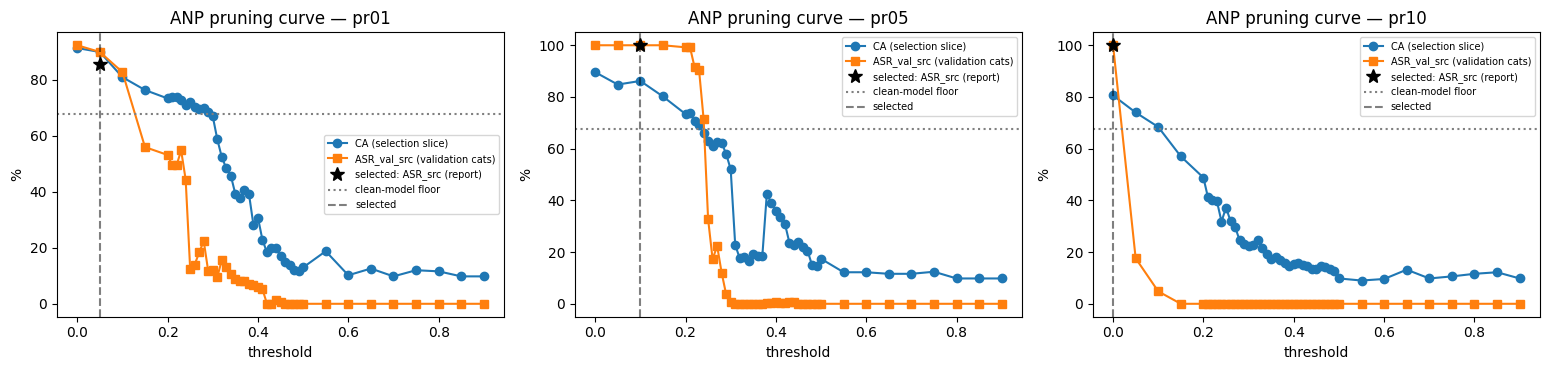

In [17]:
# ════════════════════════════════════════════════════════════════════════
# Cell D2b — ANP run: mask optimisation → threshold sweep → VALIDATION-based operating point → export
# ════════════════════════════════════════════════════════════════════════
def anp_builder(tag):
    def _b():
        model = convert_to_anp_model(load_model(sk_ckpt(tag), device='cpu')).to(DEVICE)
        for n, p in model.named_parameters():
            p.requires_grad = ('neuron_mask' in n) or ('neuron_noise' in n)
        mask_p  = [p for n, p in model.named_parameters() if 'neuron_mask' in n]
        noise_p = [p for n, p in model.named_parameters() if 'neuron_noise' in n]
        mask_opt, noise_opt = torch.optim.SGD(mask_p, lr=ANP_LR, momentum=0.9), torch.optim.SGD(noise_p, lr=ANP_EPS / ANP_STEPS)
        crit = nn.CrossEntropyLoss()
        loader = DefLoader(X_TR, Y_TR, ANP_BATCH, augment=ANP_AUGMENT)
        tl = tc = tn = 0; t_train = time.time()
        print(f'    [ANP] device={DEVICE} iters={ANP_NB_ITER} batch={ANP_BATCH} steps={ANP_STEPS}' + ('  ⚠️ CPU: this will be very slow' if DEVICE == 'cpu' else ''))
        for it, (x, y) in enumerate(loader.sample_batches(ANP_NB_ITER), 1):
            l, c, n = anp_mask_train_iter(model, x, y, crit, mask_opt, noise_opt); tl += l; tc += c; tn += n
            if it == 1 or it % ANP_PRINT_EVERY == 0 or it == ANP_NB_ITER:
                allm = torch.cat([p.data.flatten() for p in mask_p]); el = time.time() - t_train
                print(f'    iter {it}/{ANP_NB_ITER} loss={tl/it:.4f} acc={tc/tn:.4f} mask[min/mean]={allm.min():.3f}/{allm.mean():.3f} <0.5: {(allm<0.5).sum().item()} | {el:.0f}s elapsed, ETA {el/it*(ANP_NB_ITER-it):.0f}s')
        recs = [{'Layer': k.rsplit('.', 1)[0], 'Neuron': i, 'MaskScore': float(v[i])}
                for k, v in model.state_dict().items() if 'neuron_mask' in k for i in range(v.numel())]
        scores = pd.DataFrame(recs).sort_values('MaskScore').reset_index(drop=True)
        scores.to_csv(f"{SUBDIRS['csv']}/sk_anp_scores_{tag}.csv", index=False)
        t_sweep = time.time()
        ths = np.arange(0.0, ANP_PRUNING_MAX + ANP_PRUNING_STEP / 2, ANP_PRUNING_STEP).tolist()
        if ANP_FINE_GRID: ths += np.arange(ANP_FINE_GRID[0], ANP_FINE_GRID[1] + ANP_FINE_GRID[2] / 2, ANP_FINE_GRID[2]).tolist()
        ths = sorted(set(round(float(t), 4) for t in ths))
        curve = []
        for th in ths:
            pm = get_resnet18().to(DEVICE); pm.load_state_dict(extract_clean_state_dict(model, th)); pm.eval()
            vm = val_metrics(pm); npr = int((scores.MaskScore < th).sum())
            row = {'Threshold': th, 'NeuronsPruned': npr, 'NeuronsTotal': len(scores), 'PruneFraction': npr / len(scores),
                   'CA_sel': vm['CA_sel'], 'ASR_val_src': vm['ASR_val_src']}              # SELECTION signals (validation only)
            if ANP_CURVE_REPORT:                                                            # optional: full report-half curve (slow)
                m = evaluate(pm); row.update({'CA': m['CA'], 'ASR_src': m['ASR_src'], 'ASR_all': m['ASR_all']})
            curve.append(row); del pm
        cdf = pd.DataFrame(curve); print(f'    threshold sweep: {len(ths)} thresholds in {time.time()-t_sweep:.0f}s (report-half curve: {ANP_CURVE_REPORT})')
        b = BASELINE[tag]
        gate = MAX_CA_DROP_PP - ANP_SELECT_CA_MARGIN_PP
        def _select(rule):
            ok = cdf[(b['CA_sel'] - cdf.CA_sel) * 100 <= gate]
            if ok.empty: return None
            if rule == 'val_ca': return ok.sort_values('Threshold').iloc[-1]                      # no trigger knowledge
            return ok.assign(_d=b['ASR_val_src'] - ok.ASR_val_src).sort_values(['_d', 'Threshold']).iloc[-1]   # ORACLE-VAL (true trigger)
        best, orc = _select(ANP_SELECT_RULE), _select('val_oracle_asr')
        if best is None:
            print('    ⚠️  no threshold within the selection-slice gate → threshold 0.0 (no pruning)'); best = cdf.iloc[0]
        final = get_resnet18().to(DEVICE); final.load_state_dict(extract_clean_state_dict(model, float(best.Threshold))); final.eval()
        print(f'    rule={ANP_SELECT_RULE}: selected threshold={best.Threshold:.2f} (selection-slice gate {gate:.1f}pp): pruned {int(best.NeuronsPruned)}/{int(best.NeuronsTotal)} neurons')
        def _report_at(th):                                                                  # report-half metrics for ONE threshold
            r_ = cdf[cdf.Threshold == th]
            if ANP_CURVE_REPORT and len(r_) and 'CA' in r_: return {'CA': float(r_.CA.iloc[0]), 'ASR_src': float(r_.ASR_src.iloc[0]), 'ASR_all': float(r_.ASR_all.iloc[0])}
            pm = get_resnet18().to(DEVICE); pm.load_state_dict(extract_clean_state_dict(model, th)); pm.eval(); return evaluate(pm)
        if orc is not None:
            _ro = _report_at(float(orc.Threshold))
        oracle_val = None if orc is None else {'threshold': float(orc.Threshold), 'report_CA': _ro['CA'], 'report_ASR_src': _ro['ASR_src'],
                                               'report_ASR_all': _ro['ASR_all'], 'n_pruned': int(orc.NeuronsPruned)}
        # selected-threshold report metrics are added to the saved curve (one row) so plots can mark it
        _rs = _report_at(float(best.Threshold)); cdf['CA'] = np.nan; cdf['ASR_src'] = np.nan; cdf['ASR_all'] = np.nan
        for k_, v_ in _rs.items():
            if not ANP_CURVE_REPORT: cdf.loc[cdf.Threshold == float(best.Threshold), k_] = v_
        cdf.to_csv(f"{SUBDIRS['csv']}/sk_anp_curve_{tag}.csv", index=False)
        if oracle_val: print(f'    [ORACLE-VAL upper bound, true trigger on validation half] threshold {oracle_val["threshold"]:.2f} → report CA {oracle_val["report_CA"]*100:.2f}% / ASR_src {oracle_val["report_ASR_src"]*100:.2f}%')
        return final, {'threshold': float(best.Threshold), 'n_pruned': int(best.NeuronsPruned), 'n_total': int(best.NeuronsTotal),
                       'iterations': ANP_NB_ITER, 'status': 'OK', 'select_rule': ANP_SELECT_RULE, 'select_gate_pp': gate, 'oracle_val_upper_bound': oracle_val,
                       'selection_rule': f'{ANP_SELECT_RULE}: largest threshold with selection-slice CA drop <= {gate:.1f}pp (no trigger knowledge); report set untouched',
                       'notes': f'thr={best.Threshold:.2f}, pruned {int(best.NeuronsPruned)}/{int(best.NeuronsTotal)}'}
    return _b

print('=' * 70, '\nANP\n', '=' * 70, sep='')
for tag in TAGS:
    print(f'\n── {tag} ──')
    run_or_load(tag, 'ANP', 'anp', anp_builder(tag))

_cs = [(t, f"{SUBDIRS['csv']}/sk_anp_curve_{t}.csv") for t in TAGS if os.path.isfile(f"{SUBDIRS['csv']}/sk_anp_curve_{t}.csv")]
if _cs:
    fig, axs = plt.subplots(1, len(_cs), figsize=(5.2 * len(_cs), 3.8), squeeze=False)
    for ax, (t, p) in zip(axs[0], _cs):
        c = pd.read_csv(p)
        ax.plot(c.Threshold, c.CA_sel * 100, 'o-', label='CA (selection slice)'); ax.plot(c.Threshold, c.ASR_val_src * 100, 's-', label='ASR_val_src (validation cats)')
        if c.ASR_src.notna().sum() > 1: ax.plot(c.Threshold, c.ASR_src * 100, '^--', alpha=.6, label='ASR_src (report)')
        elif c.ASR_src.notna().any(): ax.plot(c.Threshold[c.ASR_src.notna()], c.ASR_src.dropna() * 100, 'k*', ms=10, label='selected: ASR_src (report)')
        if FLOOR_SRC is not None: ax.axhline(FLOOR_SRC * 100, color='gray', ls=':', label='clean-model floor')
        thr = INFOS.get((t, 'anp'), {}).get('threshold')
        if thr is not None: ax.axvline(thr, color='k', ls='--', alpha=.5, label='selected')
        ax.set_title(f'ANP pruning curve — {t}'); ax.set_xlabel('threshold'); ax.set_ylabel('%'); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(f"{SUBDIRS['fig']}/sk_anp_curves.png", dpi=150); plt.show()

### D2b — ANP + FT ("Prune + FT")  *(new in v3.1)*

Starts from the exported ANP-pruned model and fine-tunes on the 2,000 defence-train images (augmented view) with the pruned BN channels **held at zero** (weight *and* bias re-zeroed after every step, otherwise fine-tuning would revive them). Fixed epochs / lr, nothing selected on test data. Cost = ANP mask optimisation + this fine-tune.

In [18]:
# ════════════════════════════════════════════════════════════════════════
# Cell D2b — ANP + FT (pruned channels held at zero)
# ════════════════════════════════════════════════════════════════════════
def anp_ft_builder(tag):
    def _b():
        m = load_model(CKPT_REGISTRY[(tag, 'anp')])
        bns = [x for x in m.modules() if isinstance(x, nn.BatchNorm2d)]
        zero = [((x.weight.data == 0) & (x.bias.data == 0)).clone() for x in bns]
        n_pruned = int(sum(int(z.sum()) for z in zero))
        loader = DefLoader(X_TR, Y_TR, BATCH, shuffle=True, augment=True)
        opt = torch.optim.SGD(m.parameters(), lr=ANP_FT_LR, momentum=FT_MOMENTUM, weight_decay=FT_WD); crit = nn.CrossEntropyLoss()
        t0 = time.time()
        for ep in range(1, ANP_FT_EPOCHS + 1):
            m.train()
            for x, y in loader:
                opt.zero_grad(); crit(m(x), y).backward(); opt.step()
                with torch.no_grad():
                    for bn, z in zip(bns, zero): bn.weight[z] = 0.0; bn.bias[z] = 0.0
        ft_sec = time.time() - t0
        assert all(bool(((x.weight.data == 0) & (x.bias.data == 0))[z].all()) for x, z in zip(bns, zero)), 'pruned channels were revived'
        anp_sec = INFOS.get((tag, 'anp'), {}).get('seconds', 0.0) or 0.0
        return m, {'status': 'OK', 'epochs': ANP_FT_EPOCHS, 'lr': ANP_FT_LR, 'n_pruned_held_zero': n_pruned, 'ft_sec': round(ft_sec, 1),
                   'anp_sec': anp_sec, 'seconds': round(ft_sec + anp_sec, 1), 'threshold': INFOS.get((tag, 'anp'), {}).get('threshold'),
                   'selection_rule': 'none beyond the ANP threshold (fixed epochs / lr; pruned channels held at zero)',
                   'notes': f'{n_pruned} channels held at zero; ANP thr={INFOS.get((tag, "anp"), {}).get("threshold")}'}
    return _b

if RUN_ANP_FT:
    print('=' * 70, '\nANP + FT (Prune + FT)\n', '=' * 70, sep='')
    for tag in TAGS:
        print(f'\n── {tag} ──')
        if (tag, 'anp') not in CKPT_REGISTRY:
            print('  no exported ANP checkpoint — skipped'); continue
        run_or_load(tag, 'ANP', 'anp_ft', anp_ft_builder(tag))
else:
    print('RUN_ANP_FT=False — skipped.')

ANP + FT (Prune + FT)

── pr01 ──
  [anp_ft] pr01: CA 91.88→90.55%  ASR_src 89.33→74.27%  ASR_all 88.95→78.68%  [INEFFECTIVE]

── pr05 ──
  [anp_ft] pr05: CA 90.91→90.20%  ASR_src 100.00→100.00%  ASR_all 100.00→100.00%  [INEFFECTIVE]

── pr10 ──
  [anp_ft] pr10: CA 81.60→88.28%  ASR_src 100.00→99.47%  ASR_all 100.00→98.29%  [INEFFECTIVE]


### D3 — NAD (nad.py v3 + notebook-cached student sweep) + equal-compute matched FT

Pipeline per checkpoint (all selection signals are held-out **CA on the 500-image selection slice**; ASR columns are diagnostics and never select anything):

1. `select_teacher_lr` — largest teacher lr whose fine-tuned teacher stays within 5 pp CA of the poisoned model.
2. `build_nad_teacher` — teacher = fine-tuned copy of the poisoned model; CA gate + **teacher-ASR flag** (a teacher that still carries the backdoor cannot teach a student to forget it → `interpretable=False`).
3. **Cached student sweep (v4.1)** — every (student lr × β-scale) cell is trained **once** with `nad.run_nad`, scored on the selection slice, and its weights are kept. The reported student is the selected cached model; nothing is re-trained after selection. Rule: among cells within the 5 pp gate, the strongest distillation (largest β-scale, then largest lr). The whole grid is saved to `sk_nad_student_sweep_{tag}.csv`.
4. `valid_run` = teacher passes the gate **and** the student's weights differ from the teacher's (**weight-hash proof**). `NAD_REPRO_CHECK` additionally re-trains the chosen cell once (same seed) and logs `repro_hash_match` / `repro_val_ca_delta_pp` — informational only.
5. `run_matched_ft` — the FT baseline with the *identical* recipe/compute (`teacher+student` epochs, teacher lr), reported as variant `ft_matched`.

Runs with `valid_run=False` are recorded as `NAD_INVALID_RUN` and must not be quoted as defence results; `interpretable=False` means "report as *teacher ineffective*". The same recipes are applied to the **clean model** in D3b (rows with `pr_tag='clean'`, labelled CONTROL).
Cost = lr-search + teacher FT + student sweep (all cells). The repro check is not counted.


In [19]:
# ════════════════════════════════════════════════════════════════════════
# Cell D3 — NAD (v4.1: the student sweep is CACHED, never re-trained) + equal-compute matched FT
# ════════════════════════════════════════════════════════════════════════
nad_loader = DefLoader(X_TR, Y_TR, NAD_BATCH, shuffle=True, augment=False)     # nad.py augments (black-pad crop/flip/cutout) itself

def _val_eval(m):            # teacher diagnostic: selection-slice CA + validation-half cat ASR (true trigger)
    vm = val_metrics(m); return {'ca': vm['CA_sel'], 'asr': vm['ASR_val_src']}
def _diag(m):
    vm = val_metrics(m); return {'ca_sel': round(vm['CA_sel'], 4), 'asr_val_src': round(vm['ASR_val_src'], 4)}

def pick_nad_student(cells):
    """Defender-side rule (no ASR, no trigger knowledge): among students whose held-out CA drop passes the gate, take the STRONGEST
    distillation = largest beta_scale, then largest lr. Returns the chosen sweep cell (dict) or None if no cell passes."""
    ok = [c for c in cells if c['passes']]
    return max(ok, key=lambda c: (c['beta_scale'], c['lr'])) if ok else None

def nad_student_sweep_cached(victim, teacher, base_val_ca):
    """v4.1: train every (student lr × beta-scale) cell ONCE with nad.run_nad, score it on the selection slice and KEEP its weights.
    The student that is finally reported is one of these trained models — never a re-training — so the model that passed the held-out
    CA gate is exactly the model that is evaluated. (v4.0 re-ran the chosen setting after the sweep; at pr05 the re-run landed outside
    the gate: val CA 0.896 → 0.822, NAD_INVALID_RUN.)"""
    t0, cells, states = time.time(), [], {}
    for lr in NAD_STUDENT_LRS:
        for bsc in NAD_BETA_SCALES:
            set_seed(SEED)
            sb = {k: v * bsc for k, v in NAD_BETAS.items()}
            stu, sres = nad_mod.run_nad(copy.deepcopy(victim), copy.deepcopy(teacher), nad_loader, device=DEVICE,
                                        epochs=NAD_EPOCHS, lr=lr, betas=sb, verbose=False)
            s_val = nad_mod.clean_acc(stu, select_loader, DEVICE)
            cells.append({'lr': lr, 'beta_scale': bsc, 'val_ca': round(s_val, 4), 'drop_pp': round((base_val_ca - s_val) * 100, 2),
                          'passes': bool((base_val_ca - s_val) <= NAD_MAX_CA_DROP), 'distill_sec': sres['distill_sec'],
                          'weights_hash': nad_mod.state_hash(stu)[:16], **_diag(stu)})
            states[(lr, bsc)] = {k: v.detach().cpu().clone() for k, v in stu.state_dict().items()}
            del stu; torch.cuda.empty_cache()
    return cells, states, round(time.time() - t0, 1)

def nad_builder(tag):
    control = (tag == 'clean')       # D3b: the never-poisoned model has no backdoor that a teacher could "still carry"
    def _b():
        victim = load_model(sk_ckpt(tag))
        t_lr, linfo = nad_mod.select_teacher_lr(victim, nad_loader, select_loader, DEVICE, lrs=NAD_TEACHER_LRS,
                                                max_ca_drop=NAD_MAX_CA_DROP, epochs=NAD_TEACHER_EPOCHS, diag_fn=_diag, seed=SEED)
        pd.DataFrame(linfo['table']).to_csv(f"{SUBDIRS['csv']}/sk_nad_lr_search_{tag}.csv", index=False)
        print(f'    teacher-lr search → lr={t_lr} (fallback={linfo["fallback"]}, {linfo["search_sec"]}s)')
        set_seed(SEED)
        teacher, tinfo = nad_mod.build_nad_teacher(victim, nad_loader, DEVICE, epochs=NAD_TEACHER_EPOCHS, lr=t_lr, eval_fn=_val_eval,
                                                   val_loader=select_loader, max_ca_drop=NAD_MAX_CA_DROP, verbose=False,
                                                   teacher_asr_flag_threshold=(1.01 if control else NAD_TEACHER_ASR_FLAG))
        base = {'teacher_lr': t_lr, 'teacher_lr_search': linfo, 'teacher': tinfo, 'control_model': control,
                'selection_rule': 'held-out CA on selection slice (teacher lr; student = strongest cached (lr×β-scale) cell within the CA gate); ASR diagnostics only',
                'sweep_impl': 'notebook-cached: nad.run_nad once per cell, weights kept (v4.1)'}
        cost = linfo['search_sec'] + tinfo['teacher_ft_sec']
        print(f'    teacher: val CA {tinfo["poisoned_val_ca"]:.3f}→{tinfo["teacher_val_ca"]:.3f} gate={tinfo["teacher_gate_passed"]} '
              f'| teacher ASR(val cats)={tinfo["teacher_asr"]:.3f} flag={tinfo["teacher_asr_flag"]}')
        if not tinfo['teacher_gate_passed']:
            return None, {**base, 'status': 'FAILED_TEACHER_GATE', 'seconds': round(cost, 1), 'valid_run': False,
                          'notes': f'teacher collapsed even at lr={t_lr} (fallback lr)'}
        cells, states, sweep_sec = nad_student_sweep_cached(victim, teacher, tinfo['poisoned_val_ca'])
        pd.DataFrame(cells).to_csv(f"{SUBDIRS['csv']}/sk_nad_student_sweep_{tag}.csv", index=False)
        cost += sweep_sec
        print('    student sweep (selection slice): ' + ' | '.join(f'lr={c["lr"]:g} β×{c["beta_scale"]:g}: drop {c["drop_pp"]:+.1f}pp {"✓" if c["passes"] else "✗"}' for c in cells))
        chosen = pick_nad_student(cells)
        if chosen is None:
            return None, {**base, 'status': 'FAILED_NO_STUDENT_PASSES_GATE', 'student_sweep': cells, 'seconds': round(cost, 1),
                          'valid_run': False, 'notes': 'no (lr, beta-scale) kept held-out CA within the gate'}
        student = get_resnet18().to(DEVICE)
        student.load_state_dict({k: v.to(DEVICE) for k, v in states[(chosen['lr'], chosen['beta_scale'])].items()}); student.eval()
        s_val = nad_mod.clean_acc(student, select_loader, DEVICE)
        assert abs(s_val - chosen['val_ca']) < 1e-3, f'cached student CA {s_val:.4f} != sweep CA {chosen["val_ca"]:.4f}'
        h_t, h_s = nad_mod.state_hash(teacher), nad_mod.state_hash(student); distinct = (h_t != h_s)
        print(f'    teacher/student weights distinct: {distinct} (teacher {h_t[:12]} / student {h_s[:12]})')
        repro = {}
        if NAD_REPRO_CHECK:                      # diagnostic: is "same seed, same recipe" bit-reproducible on this machine?
            t_r = time.time(); set_seed(SEED)
            s2, _ = nad_mod.run_nad(copy.deepcopy(victim), copy.deepcopy(teacher), nad_loader, device=DEVICE, epochs=NAD_EPOCHS,
                                    lr=chosen['lr'], betas={k: v * chosen['beta_scale'] for k, v in NAD_BETAS.items()}, verbose=False)
            repro = {'repro_hash_match': bool(nad_mod.state_hash(s2) == h_s),
                     'repro_val_ca_delta_pp': round((nad_mod.clean_acc(s2, select_loader, DEVICE) - s_val) * 100, 2),
                     'repro_check_sec': round(time.time() - t_r, 1)}
            del s2; torch.cuda.empty_cache()
            print(f'    re-train check (same seed): bit-identical={repro["repro_hash_match"]}, Δ selection-CA={repro["repro_val_ca_delta_pp"]:+.2f}pp')
        valid = bool(tinfo['teacher_gate_passed'] and distinct)          # the student passed the gate by construction (chosen among passing cells)
        interp = bool(valid and (control or not tinfo['teacher_asr_flag']))
        status = 'CONTROL_OK' if (control and valid) else ('OK' if interp else ('NAD_TEACHER_STILL_BACKDOORED' if valid else 'NAD_INVALID_RUN'))
        note = (f'teacher lr={t_lr}, student lr={chosen["lr"]}, beta×{chosen["beta_scale"]}; teacher ASR(val)={tinfo["teacher_asr"]:.3f}'
                + ('' if interp else ' — NOT interpretable as a defence result'))
        print(f'    student: lr={chosen["lr"]} β×{chosen["beta_scale"]} val CA {tinfo["poisoned_val_ca"]:.3f}→{s_val:.3f} valid={valid} interpretable={interp}')
        return student, {**base, **repro, 'status': status, 'valid_run': valid, 'interpretable': interp, 'student_lr': chosen['lr'],
                         'beta_scale': chosen['beta_scale'], 'student_val_ca': round(s_val, 4), 'student_sweep': cells,
                         'teacher_student_distinct': bool(distinct), 'teacher_hash': h_t[:16], 'student_hash': h_s[:16],
                         'search_sec_total': round(linfo['search_sec'] + sweep_sec, 1), 'distill_sec': chosen['distill_sec'],
                         'teacher_ft_sec': tinfo['teacher_ft_sec'], 'seconds': round(cost, 1), 'notes': note}
    return _b

def matched_ft_builder(tag):
    def _b():
        lr = INFOS.get((tag, 'nad'), {}).get('teacher_lr', 0.01)
        m, mi = nad_mod.run_matched_ft(load_model(sk_ckpt(tag)), nad_loader, DEVICE, epochs=NAD_TEACHER_EPOCHS + NAD_EPOCHS, lr=lr)
        return m, {'lr': lr, 'epochs': NAD_TEACHER_EPOCHS + NAD_EPOCHS, 'status': 'OK', 'seconds': mi['ft_sec'],
                   'selection_rule': 'lr = NAD teacher lr (held-out CA gate); equal compute to NAD (teacher+student epochs)',
                   'notes': f'matched to NAD recipe, lr={lr}'}
    return _b

print('=' * 70, '\nNAD (v4.1, cached sweep) + matched FT\n', '=' * 70, sep='')
for tag in TAGS:
    print(f'\n── {tag} ──')
    run_or_load(tag, 'NAD', 'nad', nad_builder(tag), recipe_version=NAD_RECIPE_VERSION)
    if NAD_RUN_MATCHED_FT:
        run_or_load(tag, 'FT', 'ft_matched', matched_ft_builder(tag), recipe_version=NAD_RECIPE_VERSION)


NAD (v4.1, cached sweep) + matched FT

── pr01 ──
    teacher-lr search → lr=0.01 (fallback=False, 79.93s)


/content/adaptive-backdoor-defense/defenses/nad.py:376: UserWarning: NAD teacher still backdoored (ASR 0.600 > 0.50); distillation cannot remove it. Report NAD as 'teacher ineffective', not as a defense result.
  warnings.warn(f"NAD teacher still backdoored (ASR {info['teacher_asr']:.3f} > "


    teacher: val CA 0.914→0.884 gate=True | teacher ASR(val cats)=0.600 flag=True
    student sweep (selection slice): lr=0.01 β×0.5: drop +1.8pp ✓ | lr=0.01 β×1: drop +2.8pp ✓ | lr=0.01 β×2: drop +5.6pp ✗ | lr=0.005 β×0.5: drop +2.2pp ✓ | lr=0.005 β×1: drop +1.6pp ✓ | lr=0.005 β×2: drop +2.2pp ✓
    teacher/student weights distinct: True (teacher 73a5805a81b0 / student 23e3a951d9ff)
    re-train check (same seed): bit-identical=True, Δ selection-CA=+0.00pp
    student: lr=0.005 β×2.0 val CA 0.914→0.892 valid=True interpretable=False
  [nad] pr01: CA 91.88→89.63%  ASR_src 89.33→45.60%  ASR_all 88.95→55.92%  [EFFECTIVE (at/below clean-model floor) · teacher still backdoored]
  [ft_matched] pr01: CA 91.88→89.67%  ASR_src 89.33→45.47%  ASR_all 88.95→51.97%  [EFFECTIVE (at/below clean-model floor)]

── pr05 ──
    teacher-lr search → lr=0.02 (fallback=False, 79.7s)


/content/adaptive-backdoor-defense/defenses/nad.py:376: UserWarning: NAD teacher still backdoored (ASR 0.568 > 0.50); distillation cannot remove it. Report NAD as 'teacher ineffective', not as a defense result.
  warnings.warn(f"NAD teacher still backdoored (ASR {info['teacher_asr']:.3f} > "


    teacher: val CA 0.896→0.870 gate=True | teacher ASR(val cats)=0.568 flag=True
    student sweep (selection slice): lr=0.01 β×0.5: drop +4.2pp ✓ | lr=0.01 β×1: drop +4.6pp ✓ | lr=0.01 β×2: drop +7.4pp ✗ | lr=0.005 β×0.5: drop +1.8pp ✓ | lr=0.005 β×1: drop +3.4pp ✓ | lr=0.005 β×2: drop +3.8pp ✓
    teacher/student weights distinct: True (teacher 293908edc233 / student 7f56735df154)
    re-train check (same seed): bit-identical=True, Δ selection-CA=+0.00pp
    student: lr=0.005 β×2.0 val CA 0.896→0.858 valid=True interpretable=False
  [nad] pr05: CA 90.91→87.87%  ASR_src 100.00→71.07%  ASR_all 100.00→71.32%  [EFFECTIVE (at/below clean-model floor) · teacher still backdoored]
  [ft_matched] pr05: CA 90.91→86.73%  ASR_src 100.00→99.20%  ASR_all 100.00→97.50%  [INEFFECTIVE]

── pr10 ──
    teacher-lr search → lr=0.02 (fallback=False, 79.71s)


/content/adaptive-backdoor-defense/defenses/nad.py:376: UserWarning: NAD teacher still backdoored (ASR 0.904 > 0.50); distillation cannot remove it. Report NAD as 'teacher ineffective', not as a defense result.
  warnings.warn(f"NAD teacher still backdoored (ASR {info['teacher_asr']:.3f} > "


    teacher: val CA 0.806→0.890 gate=True | teacher ASR(val cats)=0.904 flag=True
    student sweep (selection slice): lr=0.01 β×0.5: drop -8.2pp ✓ | lr=0.01 β×1: drop -8.2pp ✓ | lr=0.01 β×2: drop -5.6pp ✓ | lr=0.005 β×0.5: drop -7.2pp ✓ | lr=0.005 β×1: drop -7.8pp ✓ | lr=0.005 β×2: drop -7.8pp ✓
    teacher/student weights distinct: True (teacher 9dd02205589b / student 288f3e27036e)
    re-train check (same seed): bit-identical=True, Δ selection-CA=+0.00pp
    student: lr=0.01 β×2.0 val CA 0.806→0.862 valid=True interpretable=False
  [nad] pr10: CA 81.60→86.17%  ASR_src 100.00→60.93%  ASR_all 100.00→65.26%  [EFFECTIVE (at/below clean-model floor) · teacher still backdoored]
  [ft_matched] pr10: CA 81.60→87.17%  ASR_src 100.00→94.40%  ASR_all 100.00→92.50%  [INEFFECTIVE]


CLEAN-MODEL CONTROL — the same NAD / matched-FT recipes applied to the never-poisoned model
    teacher-lr search → lr=0.01 (fallback=False, 79.82s)
    teacher: val CA 0.922→0.888 gate=True | teacher ASR(val cats)=0.356 flag=False
    student sweep (selection slice): lr=0.01 β×0.5: drop +3.2pp ✓ | lr=0.01 β×1: drop +4.2pp ✓ | lr=0.01 β×2: drop +4.8pp ✓ | lr=0.005 β×0.5: drop +3.0pp ✓ | lr=0.005 β×1: drop +3.4pp ✓ | lr=0.005 β×2: drop +3.8pp ✓
    teacher/student weights distinct: True (teacher f0c74eec30ab / student 2948bdc7b63d)
    re-train check (same seed): bit-identical=True, Δ selection-CA=+0.00pp
    student: lr=0.01 β×2.0 val CA 0.922→0.874 valid=True interpretable=True
  [nad] clean: CA 92.47→87.68%  ASR_src 67.73→24.80%  ASR_all 68.16→34.74%  [CONTROL (no backdoor present) — what this defence does to the transfer ASR by itself]
  [ft_matched] clean: CA 92.47→89.87%  ASR_src 67.73→10.93%  ASR_all 68.16→22.50%  [CONTROL (no backdoor present) — what this defence does to the tra

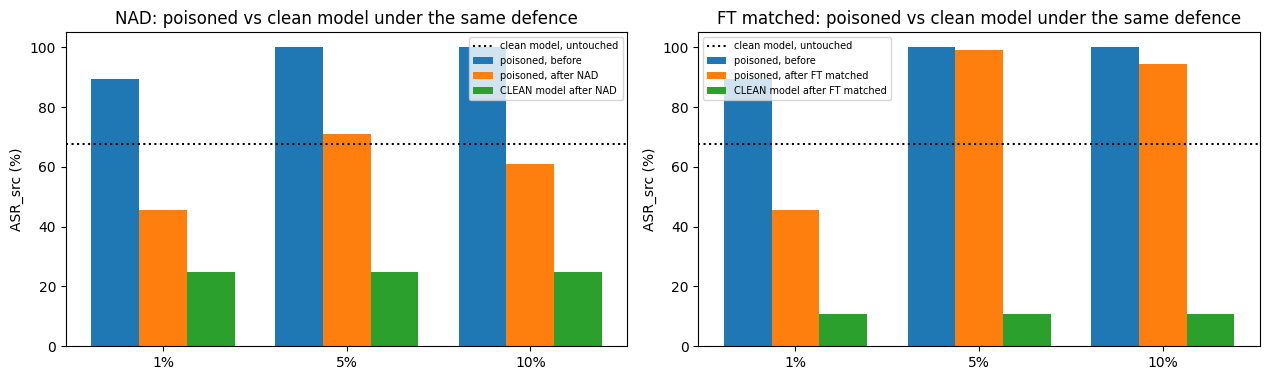

In [20]:
# ════════════════════════════════════════════════════════════════════════
# Cell D3b — Defences on the CLEAN model (v4.1 control): what do NAD / matched FT do to the transfer ASR when NO backdoor exists?
# ════════════════════════════════════════════════════════════════════════
CLEAN_DEF_LABEL = {'nad': 'NAD', 'ft_matched': 'FT matched'}
if RUN_CLEAN_DEFENCES and 'clean' in BASELINE:
    print('=' * 70, '\nCLEAN-MODEL CONTROL — the same NAD / matched-FT recipes applied to the never-poisoned model\n', '=' * 70, sep='')
    run_or_load('clean', 'NAD', 'nad', nad_builder('clean'), recipe_version=NAD_RECIPE_VERSION)
    if NAD_RUN_MATCHED_FT:
        run_or_load('clean', 'FT', 'ft_matched', matched_ft_builder('clean'), recipe_version=NAD_RECIPE_VERSION)
    CLEAN_AFTER.clear()
    for r in RESULTS:
        if r['pr_tag'] == 'clean' and r.get('CA_after') is not None and r['variant'] in CLEAN_DEF_LABEL:
            CLEAN_AFTER[r['variant']] = {'CA': r['CA_after'], 'ASR_src': r['ASR_src_after'], 'ASR_all': r['ASR_all_after']}
    annotate_rows()                                   # clean-reference columns + verdicts for every row

    if CLEAN_AFTER:
        t1 = pd.DataFrame([{'defence': CLEAN_DEF_LABEL[v], 'clean_CA_before': BASELINE['clean']['CA'], 'clean_CA_after': a['CA'],
                            'clean_ASR_src_before(=floor)': FLOOR_SRC, 'clean_ASR_src_after': a['ASR_src'],
                            'generic_transfer_drop_pp': round((FLOOR_SRC - a['ASR_src']) * 100, 1)} for v, a in CLEAN_AFTER.items()])
        t1.to_csv(f"{SUBDIRS['csv']}/sk_clean_defence_control.csv", index=False)
        print('\nWHAT THE DEFENCE DOES TO A CLEAN MODEL (report half) — "generic_transfer_drop_pp" is NOT backdoor removal'); print(t1.round(4).to_string(index=False))
        t2 = pd.DataFrame([{'pr_tag': r['pr_tag'], 'defence': CLEAN_DEF_LABEL[r['variant']], 'poisoned_ASR_src_before': r['ASR_src_before'],
                            'poisoned_ASR_src_after': r.get('ASR_src_after'), 'clean_ASR_src_same_defence': r.get('clean_same_defence_ASR_src'),
                            'residual_vs_clean_pp': r.get('residual_vs_clean_same_defence_pp'), 'poisoned_CA_after': r.get('CA_after'),
                            'valid_run': r.get('valid_run'), 'interpretable': r.get('interpretable'), 'verdict': r.get('verdict')}
                           for r in RESULTS if r['pr_tag'] in TAGS and r['variant'] in CLEAN_AFTER])
        t2.to_csv(f"{SUBDIRS['csv']}/sk_defence_vs_clean_same_defence.csv", index=False)
        print('\nPOISONED vs CLEAN under the SAME defence — "residual_vs_clean_pp" = ASR_src(poisoned, after) − ASR_src(clean, after)')
        print(t2.drop(columns=['verdict']).round(4).to_string(index=False))
        print('\nReading: if the clean model\'s ASR_src falls about as far as the poisoned model\'s, the drop is generic robustness of the recipe '
              '(augmentation + high lr), not backdoor removal. Only the RESIDUAL is attributable to the backdoor.')
        _vs = [v for v in ('nad', 'ft_matched') if v in CLEAN_AFTER]
        fig, axs = plt.subplots(1, len(_vs), figsize=(6.4 * len(_vs), 3.9), squeeze=False)
        for ax, v in zip(axs[0], _vs):
            xs_, w = np.arange(len(TAGS)), 0.26
            bef = [BASELINE[t]['ASR_src'] * 100 for t in TAGS]
            aft = [next((r['ASR_src_after'] for r in RESULTS if r['pr_tag'] == t and r['variant'] == v and r.get('ASR_src_after') is not None), np.nan) * 100 for t in TAGS]
            ax.bar(xs_ - w, bef, w, label='poisoned, before'); ax.bar(xs_, aft, w, label=f'poisoned, after {CLEAN_DEF_LABEL[v]}')
            ax.bar(xs_ + w, [CLEAN_AFTER[v]['ASR_src'] * 100] * len(TAGS), w, label=f'CLEAN model after {CLEAN_DEF_LABEL[v]}')
            ax.axhline(FLOOR_SRC * 100, color='k', ls=':', label='clean model, untouched')
            ax.set_xticks(xs_); ax.set_xticklabels([f'{PR_MAP[t]*100:g}%' for t in TAGS]); ax.set_ylabel('ASR_src (%)'); ax.legend(fontsize=7)
            ax.set_title(f'{CLEAN_DEF_LABEL[v]}: poisoned vs clean model under the same defence')
        plt.tight_layout(); plt.savefig(f"{SUBDIRS['fig']}/sk_defence_vs_clean_control.png", dpi=150); plt.show()
    else:
        print('\nNo clean-model defence produced a usable model → verdicts fall back to the clean-model floor (generous).')
else:
    print('Clean-model defences skipped (RUN_CLEAN_DEFENCES off or no clean baseline) → verdicts use the untouched clean-model floor (generous).')


### D4 — BaEraser-lite (v3 API, SK operator)

`BL.baeraser_lite(...)` with: SK operator (`linf=16/255`, SK normaliser) · fresh random init per ε (no warm start) · target-class images excluded · **non-oracle checkpoint selection** from the selection slice (`fresh_select_k=FRESH_SELECT_K`; 1 = smoke test, raise to 3 for the real matrix) · the returned **`result.model`** (selected weights) · acceptance measured on the held-out selection slice.

**Headline** = real CA/ASR on the *report* half at the selected epoch; the oracle epoch (best real ASR) is stored separately as an upper bound. **Audits** (defender-computable, same config on poisoned / sanitised / **clean** models): `fresh_recovery_audit` (can brand-new triggers still work?) and `universal_adv_vulnerability` (ε = 16/255 universal perturbation). If the clean model accepts triggers just as easily, recovery is finding generic target-class UAPs, and any ASR drop is partly adversarial-training-like.

**Cost** = recovery (+ relaxed pass, if one was needed) + unlearning + selection audits + the sanitised-model audit (the poisoned/clean audits are comparison references, listed separately).
**Failures** (0 triggers, no valid checkpoint) are recorded, never raised. A relaxed-threshold pass (0.50) is used only if the strict pass (0.80) accepts nothing, and is labelled.

In [21]:
# ════════════════════════════════════════════════════════════════════════
# Cell D4a — BaEraser-lite for SK: diagnostics, audits, core pipeline
# ════════════════════════════════════════════════════════════════════════
UNLEARN_MAX_EPOCHS = 2 if QUICK else BL.BAERASER_MAX_UNLEARNING_EPOCHS

@torch.no_grad()
def _hit_rate(model, x_norm, t, bs=500):
    hits = []
    for i in range(0, len(x_norm), bs):
        x = x_norm[i:i + bs].to(DEVICE)
        hits.append((model(operator.apply(x, t.to(DEVICE))).argmax(1) == TARGET_CLASS).cpu())
    return torch.cat(hits).float()

def trigger_report(model, t):
    """Diagnostics for ONE recovered trigger t∈[0,1] (true δ used for similarity only; ASR sets are the REPORT half)."""
    model.eval(); d_hit, ys = [], []
    with torch.no_grad():
        for x, y in defense_eval:
            d_hit.append((model(operator.apply(x, t.to(DEVICE))).argmax(1) == TARGET_CLASS).cpu()); ys.append(y.cpu())
    d_hit, ys = torch.cat(d_hit).float(), torch.cat(ys)
    per_class = [round(d_hit[ys == c].mean().item(), 3) if (ys == c).any() else float('nan') for c in range(NUM_CLASSES)]
    d = operator.to_delta(t.cpu())
    pear = float(pearsonr(d.flatten().numpy(), DELTA.flatten().numpy())[0]) if d.std() > 0 else float('nan')
    return {'defence_asr_by_class': per_class, 'defence_asr_source_class': per_class[SOURCE_CLASS],
            'report_asr_src': round(_hit_rate(model, X_SRC_REPORT_N, t).mean().item(), 4),
            'report_asr_all': round(_hit_rate(model, X_ALL_REPORT_N, t).mean().item(), 4),
            'pearson_vs_true_delta': round(pear, 4),
            'sign_agreement_vs_true': round(float((torch.sign(d) == torch.sign(DELTA)).float().mean()), 4),
            'linf_255': round(float(d.abs().max()) * 255, 2)}

def audit_model(model):
    """Fresh-recovery audit + universal-perturbation check (defender-computable; uses defence-train + selection slice only)."""
    t0 = time.time()
    a = BL.fresh_recovery_audit(model, defense_loader, select_loader, TARGET_CLASS, operator, device=DEVICE,
                                seed=SEED + AUDIT_SEED_OFFSET, config_override=AUDIT_CONFIG)          # new triggers, held-out select slice
    u = BL.universal_adv_vulnerability(model, defense_loader, test_loader, TARGET_CLASS, device=DEVICE,   # v3.1: UAP evaluated on the REPORT half
                                       eps=UAP_EPS, step=UAP_STEP, epochs=UAP_EPOCHS)
    return {'fresh_max_asr': round(a['max_asr'], 4), 'fresh_n_accepted': a['n_accepted'], 'fresh_n_tried': a['n_tried'],
            'fresh_per_epsilon': a['per_epsilon'], 'fresh_audit_seconds': round(a['seconds'], 1),
            'uap_asr': round(u['uap_asr'], 4), 'uap_eps_255': round(u['eps'] * 255, 2), 'audit_total_seconds': round(time.time() - t0, 1)}

def plot_recovered(label, pool):
    if not pool: return
    best = sorted(pool, key=lambda p: -p['asr'])[:3]
    fig, ax = plt.subplots(1, 1 + len(best), figsize=(3 * (1 + len(best)), 3.3))
    amp = lambda d: (d / (2 * SK_LINF) + 0.5).permute(1, 2, 0).numpy().clip(0, 1)
    ax[0].imshow(amp(DELTA)); ax[0].set_title('TRUE δ (eval only)\n±16/255 → [0,1]', fontsize=8); ax[0].axis('off')
    for j, p in enumerate(best):
        ax[j + 1].imshow(amp(operator.to_delta(p['tensor']))); ax[j + 1].axis('off')
        ax[j + 1].set_title(f'recovered (hinge ε={p["epsilon"]:.2f})\nheld-out ASR={p["asr"]*100:.0f}%', fontsize=8)
    plt.suptitle(f'{label}: true vs recovered SK trigger'); plt.tight_layout()
    plt.savefig(f"{SUBDIRS['fig']}/sk_baeraser_trigger_{label}.png", dpi=140, bbox_inches='tight'); plt.show()

def _run_lite(victim, threshold, ca_before, asr_before):
    return BL.baeraser_lite(victim, defense_loader, operator, TARGET_CLASS, device=DEVICE, recovery_asr_threshold=threshold,
                            config_override=SK_RECOVERY_CONFIG, seed=SEED, select_loader=select_loader,
                            fresh_select_k=FRESH_SELECT_K, fresh_audit_kwargs=dict(config_override=AUDIT_CONFIG),
                            calculate_ca=calculate_ca, ca_loader=test_loader, calculate_asr=calculate_asr, asr_loader=asr_src_loader,
                            ca_before=ca_before, asr_before=asr_before, max_epochs=UNLEARN_MAX_EPOCHS,
                            ca_drop_tolerance=BL.CA_DROP_TOLERANCE - CA_SELECT_MARGIN)       # v3.1: tightened select-slice gate

CLEAN_AUDIT = {}      # filled by the clean-model control (D4c)

def baeraser_core(victim_path, ca_before, asr_before, label, with_audits=True):
    victim = load_model(victim_path)
    res, mode, extra_rec = _run_lite(victim, RECOVERY_THRESHOLD, ca_before, asr_before), 'strict', 0.0
    if res.unlearning['status'] == 'FAILED_NO_TRIGGERS' and RELAXED_RECOVERY_THRESHOLD is not None:
        print(f'  strict pass accepted 0 triggers → RELAXED pass at {RELAXED_RECOVERY_THRESHOLD:.2f} (labelled in results)')
        extra_rec = res.unlearning['total_cost_seconds']
        res, mode = _run_lite(victim, RELAXED_RECOVERY_THRESHOLD, ca_before, asr_before), 'relaxed'
    u, summ = res.unlearning, BL.summarize_result(res)
    rm = res.recovery_meta or {}
    if 'fresh_init_verified' in rm:                                    # v3: independent random init per ε, no warm start / chaining
        assert rm.get('init_mode') == 'random' and rm['fresh_init_verified'] is True, 'recovery inits were not independent'
    info = {'recovery_mode': mode, 'summary': summ, 'operator': operator.metadata(), 'operator_source': OPERATOR_SOURCE,
            'recovery_cfg': SK_RECOVERY_CONFIG, 'recovery_candidates': res.recovery_candidates,
            'fresh_init_verified': (res.recovery_meta or {}).get('fresh_init_verified'), 'fresh_select_k': FRESH_SELECT_K,
            'selection_rule': u.get('selection_rule', ''), 'recovery_seconds_failed_strict_pass': round(extra_rec, 1),
            'ca_select_margin': CA_SELECT_MARGIN, 'select_gate_tolerance': round(BL.CA_DROP_TOLERANCE - CA_SELECT_MARGIN, 4)}
    if u['status'] == 'FAILED_NO_TRIGGERS':
        info.update({'status': 'FAILED_NO_TRIGGERS', 'seconds': round(u['total_cost_seconds'] + extra_rec, 1),
                     'notes': f'0 accepted triggers (best held-out candidate ASR {summ["max_candidate_asr"]}) — failure case'})
        print('  ⚠️  recovery FAILED (recorded, not raised).'); return None, info
    diag = [dict(trigger_report(victim, p['tensor']), hinge_eps=p['epsilon'], heldout_asr=p['asr']) for p in res.trigger_pool]
    info['trigger_diagnostics'] = diag
    print(pd.DataFrame(diag).drop(columns=['defence_asr_by_class']).round(3).to_string(index=False))
    for k, p in enumerate(res.trigger_pool):
        np.save(f"{SUBDIRS['trigger']}/sk_recovered_{label}_{k}.npy", p['tensor'].numpy())
    plot_recovered(label, res.trigger_pool)
    L = pd.DataFrame(u['logs']); L.to_csv(f"{SUBDIRS['csv']}/sk_baeraser_unlearning_{label}.csv", index=False)
    info.update({'unlearning_log': u['logs'], 'best_epoch': u['best_epoch'],
                 'oracle_UPPER_BOUND': {'epoch': u.get('oracle_best_epoch'), 'CA': u.get('oracle_CA'), 'ASR': u.get('oracle_ASR')},
                 'headline_at_selected_epoch': {'CA': u.get('CA_after'), 'ASR': u.get('ASR_after')},
                 'selection_signals': {'sel_CA': u.get('sel_CA_after'), 'sel_proxy_ASR': u.get('sel_ASR_after'), 'sel_fresh_ASR': u.get('sel_fresh_ASR_after')},
                 'unlearning_cfg': u.get('config'), 'recovery_seconds': summ['recovery_s'], 'unlearning_seconds': round(u['total_compute_seconds'], 1),
                 'selection_audit_seconds': round(u.get('selection_audit_seconds', 0.0), 1)})
    if u['status'] != 'SUCCESS':
        info.update({'status': 'FAILED_NO_VALID_CHECKPOINT', 'seconds': round(u['total_cost_seconds'] + extra_rec, 1),
                     'notes': 'no epoch kept held-out CA within tolerance — failure case'})
        print('  ⚠️  no valid checkpoint (recorded, not raised).'); return None, info
    print(f'  [gate] select-slice CA tolerance used: {BL.CA_DROP_TOLERANCE - CA_SELECT_MARGIN:.3f} (BL.CA_DROP_TOLERANCE {BL.CA_DROP_TOLERANCE} − margin {CA_SELECT_MARGIN})')
    audit_cost = 0.0
    if with_audits:
        info['audit_poisoned_reference'] = audit_model(victim)
        info['audit_sanitised'] = audit_model(res.model)
        audit_cost = info['audit_sanitised']['audit_total_seconds']
    first_hit = ''
    if FLOOR_SRC is not None:
        hit = L[L.ASR.notna() & (L.ASR <= FLOOR_SRC + 0.02)]
        if len(hit): first_hit = f'; first epoch at floor (monitoring): {int(hit.epoch.iloc[0])}'
    info.update({'status': 'OK', 'seconds': round(u['total_cost_seconds'] + extra_rec + audit_cost, 1),
                 'cost_breakdown': {'recovery': summ['recovery_s'], 'unlearning_incl_selection_audits': u['total_compute_seconds'],
                                    'failed_strict_recovery': extra_rec, 'sanitised_model_audit': audit_cost},
                 'notes': f'{mode} recovery, {summ["n_accepted"]} trigger(s), selected epoch {u["best_epoch"]}{first_hit}'})
    return res.model, info

def baeraser_builder(tag):
    def _b():
        return baeraser_core(sk_ckpt(tag), BASELINE[tag]['CA'], BASELINE[tag]['ASR_src'], tag)
    return _b
print('BaEraser-lite SK pipeline defined. max unlearning epochs =', UNLEARN_MAX_EPOCHS, '| fresh_select_k =', FRESH_SELECT_K)

BaEraser-lite SK pipeline defined. max unlearning epochs = 15 | fresh_select_k = 1


BAERASER-LITE (SK operator, recovered triggers only, non-oracle selection)

── pr01 ──
  [coarse] recovery epsilon=0.20
    exact ASR=99.55% [ACCEPTED]
  [coarse] recovery epsilon=0.50
    exact ASR=99.77% [ACCEPTED]
    -> 2 accepted triggers, stopping recovery early.
 defence_asr_source_class  report_asr_src  report_asr_all  pearson_vs_true_delta  sign_agreement_vs_true  linf_255  hinge_eps  heldout_asr
                      1.0             1.0           1.000                  0.074                   0.529     15.54        0.2        0.995
                      1.0             1.0           0.996                 -0.017                   0.489     15.76        0.5        0.998


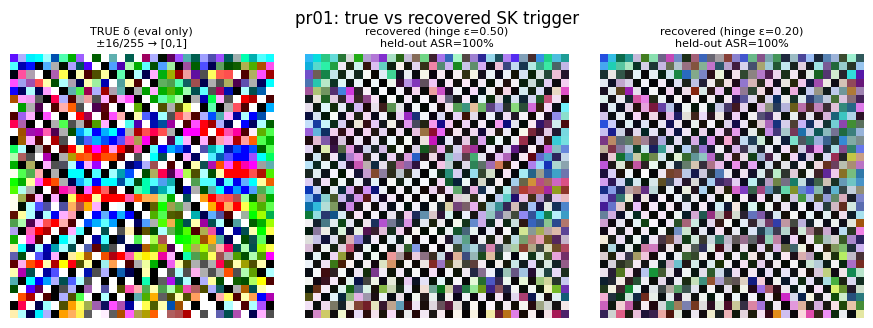

  ⚠️  no valid checkpoint (recorded, not raised).
  [baeraser] pr01: FAILED_NO_VALID_CHECKPOINT — no model produced

── pr05 ──
  [coarse] recovery epsilon=0.20
    exact ASR=100.00% [ACCEPTED]
  [coarse] recovery epsilon=0.50
    exact ASR=100.00% [ACCEPTED]
    -> 2 accepted triggers, stopping recovery early.
 defence_asr_source_class  report_asr_src  report_asr_all  pearson_vs_true_delta  sign_agreement_vs_true  linf_255  hinge_eps  heldout_asr
                      1.0             1.0             1.0                  0.019                   0.502     15.89        0.2          1.0
                      1.0             1.0             1.0                 -0.026                   0.498     13.37        0.5          1.0


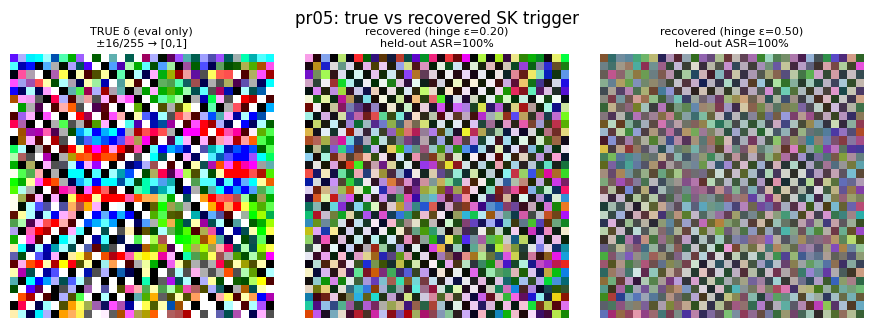

  ⚠️  no valid checkpoint (recorded, not raised).
  [baeraser] pr05: FAILED_NO_VALID_CHECKPOINT — no model produced

── pr10 ──
  [coarse] recovery epsilon=0.20
    exact ASR=100.00% [ACCEPTED]
  [coarse] recovery epsilon=0.50
    exact ASR=100.00% [ACCEPTED]
    -> 2 accepted triggers, stopping recovery early.
 defence_asr_source_class  report_asr_src  report_asr_all  pearson_vs_true_delta  sign_agreement_vs_true  linf_255  hinge_eps  heldout_asr
                      1.0             1.0             1.0                  0.022                   0.517     15.49        0.2          1.0
                      1.0             1.0             1.0                  0.036                   0.512     14.14        0.5          1.0


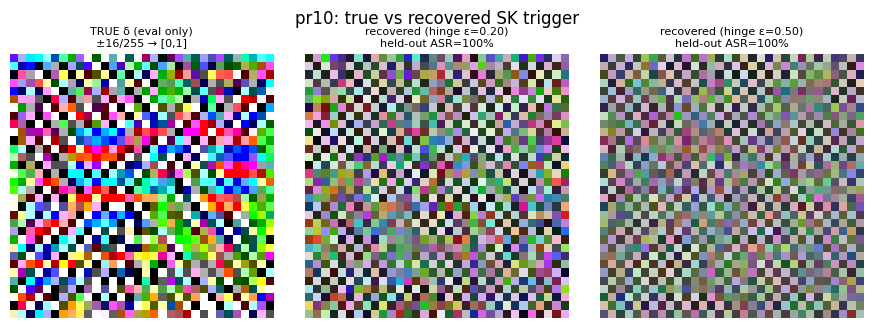

  [gate] select-slice CA tolerance used: 0.040 (BL.CA_DROP_TOLERANCE 0.05 − margin 0.01)
  [baeraser] pr10: CA 81.60→77.89%  ASR_src 100.00→83.60%  ASR_all 100.00→74.61%  [INEFFECTIVE]


In [22]:
# ════════════════════════════════════════════════════════════════════════
# Cell D4b — Run BaEraser-lite on every selected SK checkpoint
# ════════════════════════════════════════════════════════════════════════
print('=' * 70, '\nBAERASER-LITE (SK operator, recovered triggers only, non-oracle selection)\n', '=' * 70, sep='')
for tag in TAGS:
    print(f'\n── {tag} ──')
    run_or_load(tag, 'BAERASER', 'baeraser', baeraser_builder(tag))

  [coarse] recovery epsilon=0.20
    exact ASR=98.65% [ACCEPTED]
  [coarse] recovery epsilon=0.50
    exact ASR=99.10% [ACCEPTED]
    -> 2 accepted triggers, stopping recovery early.
 defence_asr_source_class  report_asr_src  report_asr_all  pearson_vs_true_delta  sign_agreement_vs_true  linf_255  hinge_eps  heldout_asr
                    0.990           0.987           0.970                  0.097                   0.543     15.91        0.2        0.986
                    0.995           0.993           0.986                 -0.028                   0.490     15.99        0.5        0.991


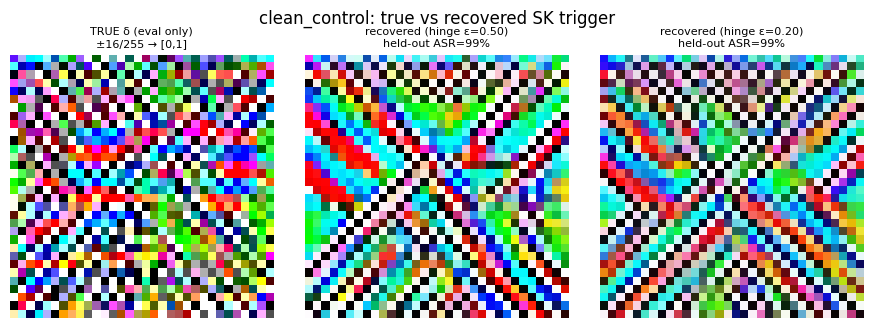

  ⚠️  no valid checkpoint (recorded, not raised).
         model                     status  n_accepted  max_candidate_asr  fresh_audit_asr  uap_asr  ASR_src_before  ASR_src_after_baeraser  CA_after_baeraser  fresh_audit_asr_AFTER_sanitising  uap_asr_AFTER_sanitising
CLEAN baseline FAILED_NO_VALID_CHECKPOINT           2             0.9910           0.9955   0.9889          0.6773                     NaN                NaN                               NaN                       NaN
 poisoned pr01 FAILED_NO_VALID_CHECKPOINT           2             0.9977              NaN      NaN          0.8933                     NaN                NaN                               NaN                       NaN
 poisoned pr05 FAILED_NO_VALID_CHECKPOINT           2             1.0000              NaN      NaN          1.0000                     NaN                NaN                               NaN                       NaN
 poisoned pr10                         OK           2             1.0000      

In [23]:
# ════════════════════════════════════════════════════════════════════════
# Cell D4c — CLEAN-MODEL CONTROL (same recovery config) + comparison with the poisoned checkpoints
# ════════════════════════════════════════════════════════════════════════
CONTROL_ROWS = []
if RUN_CLEAN_CONTROL and os.path.isfile(CLEAN_BASELINE_CKPT) and FLOOR_SRC is not None:
    _cb = [v for k, v in CONTROLS.items() if k.startswith('clean_baseline')][0]
    set_seed(SEED)
    _cm, _ci = baeraser_core(CLEAN_BASELINE_CKPT, _cb['CA'], _cb['ASR_src'], 'clean_control', with_audits=False)
    _cv = load_model(CLEAN_BASELINE_CKPT)
    CLEAN_AUDIT = audit_model(_cv)                       # clean model's OWN fresh-trigger / UAP vulnerability
    json.dump({'summary': _ci.get('summary'), 'audit_clean': CLEAN_AUDIT, 'status': _ci['status']},
              open(f"{SUBDIRS['log']}/sk_baeraser_clean_control.json", 'w'), indent=2, default=to_py)
    _sc = _ci.get('summary', {})
    _e = evaluate(_cm) if _cm is not None else {}
    CONTROL_ROWS.append({'model': 'CLEAN baseline', 'status': _ci['status'], 'n_accepted': _sc.get('n_accepted'),
                         'max_candidate_asr': _sc.get('max_candidate_asr'), 'fresh_audit_asr': CLEAN_AUDIT['fresh_max_asr'],
                         'uap_asr': CLEAN_AUDIT['uap_asr'], 'ASR_src_before': _cb['ASR_src'], 'ASR_src_after_baeraser': _e.get('ASR_src'),
                         'CA_after_baeraser': _e.get('CA')})
    for tag in TAGS:
        inf = INFOS.get((tag, 'baeraser'), {}); sm = inf.get('summary', {}); r = [x for x in RESULTS if x['pr_tag'] == tag and x['variant'] == 'baeraser']
        CONTROL_ROWS.append({'model': f'poisoned {tag}', 'status': inf.get('status'), 'n_accepted': sm.get('n_accepted'),
                             'max_candidate_asr': sm.get('max_candidate_asr'),
                             'fresh_audit_asr': inf.get('audit_poisoned_reference', {}).get('fresh_max_asr'),
                             'uap_asr': inf.get('audit_poisoned_reference', {}).get('uap_asr'),
                             'ASR_src_before': BASELINE[tag]['ASR_src'], 'ASR_src_after_baeraser': r[0]['ASR_src_after'] if r else None,
                             'CA_after_baeraser': r[0]['CA_after'] if r else None,
                             'fresh_audit_asr_AFTER_sanitising': inf.get('audit_sanitised', {}).get('fresh_max_asr'),
                             'uap_asr_AFTER_sanitising': inf.get('audit_sanitised', {}).get('uap_asr')})
    ctrl_df = pd.DataFrame(CONTROL_ROWS); ctrl_df.to_csv(f"{SUBDIRS['csv']}/sk_baeraser_clean_control.csv", index=False)
    print(ctrl_df.round(4).to_string(index=False))
    print('\nReading: if the CLEAN model accepts triggers (n_accepted>0) and has a similar fresh-audit / UAP ASR to the poisoned ones, '
          'recovery is finding generic target-class UAPs, not the backdoor. If sanitising lowers fresh_audit/uap ASR too, part of the '
          'gain is generic adversarial robustness. ASR_src_after on the clean model shows how far BaEraser lowers ASR with no backdoor present.')
else:
    print('Clean-model control skipped (flag off, clean baseline missing, or floor unavailable).')

if RUN_ORACLE_DIAGNOSTIC:
    _t = TAGS[0]; set_seed(SEED); _v = load_model(sk_ckpt(_t))
    _r = BL.baeraser_lite(_v, defense_loader, operator, TARGET_CLASS, device=DEVICE, oracle_trigger=operator.from_delta(DELTA),
                          diagnostic_only=True, select_loader=select_loader, calculate_ca=calculate_ca, ca_loader=test_loader,
                          calculate_asr=calculate_asr, asr_loader=asr_src_loader, ca_before=BASELINE[_t]['CA'],
                          asr_before=BASELINE[_t]['ASR_src'], max_epochs=UNLEARN_MAX_EPOCHS, seed=SEED)
    _e = evaluate(_r.model)
    print('ORACLE DIAGNOSTIC ONLY (not a BaEraser-lite result):', {k: round(v, 4) for k, v in _e.items()}, '| status', _r.unlearning['status'])

## Section E — Master results (report half only)

`ASR_src` = cat+δ → airplane (primary). `ASR_all` = `asr_test_idx ∩ report`+δ → airplane. `verdict` is **floor-relative** (*EFFECTIVE* ⇔ `ASR_src_after ≤ max(10 %, clean-model floor + 5 pp)`), and flags CA-over-budget, invalid NAD runs (collapse gate) and NAD runs whose teacher is still backdoored.

FLOOR (clean-baseline transfer) ASR_src(report) = 0.6773333333333333

PRIMARY VARIANTS
pr_tag    variant  CA_before  CA_after  CA_drop_pp report_ca_budget_violated  ASR_src_before  ASR_src_after  ASR_src_minus_floor_pp  clean_same_defence_ASR_src  residual_vs_clean_same_defence_pp  ASR_all_before  ASR_all_after  seconds                       status valid_run interpretable                                                                                                                         verdict
 clean ft_matched     0.9247    0.8987        2.60                     False          0.6773         0.1093                  -56.80                         NaN                                NaN          0.6816         0.2250    38.44                           OK      None          None                                            CONTROL (no backdoor present) — what this defence does to the transfer ASR by itself
 clean        nad     0.9247    0.8768        4.79                     False     

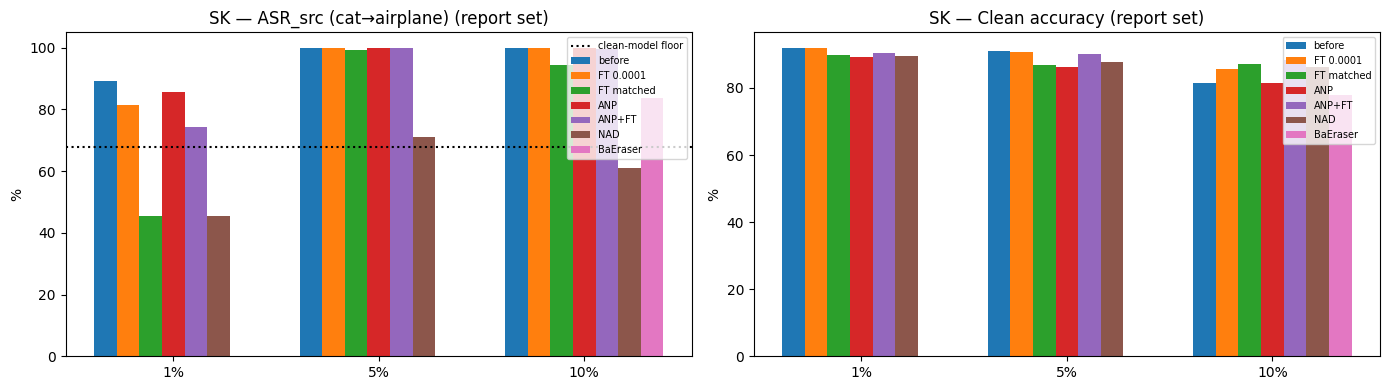

In [24]:
# ════════════════════════════════════════════════════════════════════════
# Cell E1 — Master table, primary-variant summary, plots
# ════════════════════════════════════════════════════════════════════════
annotate_rows()          # v4.1: clean-reference columns + verdicts (CLEAN_AFTER from D3b)
master_df = pd.DataFrame(RESULTS)
master_df.to_csv(f"{SUBDIRS['csv']}/sk_defense_results_all.csv", index=False)
PRIMARY_VARIANTS = [FT_PRIMARY_VARIANT, 'ft_matched', 'anp', 'anp_ft', 'nad', 'baeraser']
VARIANT_LABEL = {FT_PRIMARY_VARIANT: f'FT {FT_PRIMARY_LR:g}', 'ft_matched': 'FT matched', 'anp': 'ANP', 'anp_ft': 'ANP+FT', 'nad': 'NAD', 'baeraser': 'BaEraser'}
prim = master_df[master_df.variant.isin(PRIMARY_VARIANTS)].copy()
prim['variant'] = pd.Categorical(prim.variant, PRIMARY_VARIANTS, ordered=True)
prim = prim.sort_values(['poison_rate', 'variant'])
cols = ['pr_tag', 'variant', 'CA_before', 'CA_after', 'CA_drop_pp', 'report_ca_budget_violated', 'ASR_src_before', 'ASR_src_after', 'ASR_src_minus_floor_pp', 'clean_same_defence_ASR_src', 'residual_vs_clean_same_defence_pp',
        'ASR_all_before', 'ASR_all_after', 'seconds', 'status', 'valid_run', 'interpretable', 'verdict']
print(f'FLOOR (clean-baseline transfer) ASR_src(report) = {FLOOR_SRC}\n')
print('PRIMARY VARIANTS'); print(prim[[c for c in cols if c in prim.columns]].round(4).to_string(index=False))
prim.to_csv(f"{SUBDIRS['csv']}/sk_defense_results_primary.csv", index=False)
print('\nFT learning-rate sensitivity')
print(master_df[master_df.defense == 'FT'][['pr_tag', 'variant', 'CA_after', 'ASR_src_after', 'ASR_all_after']].round(4).to_string(index=False))

_ok = prim[prim.CA_after.notna()]
if len(_ok):
    fig, axs = plt.subplots(1, 2, figsize=(14, 4))
    tags = [t for t in TAGS if t in set(_ok.pr_tag)]; w = 0.11; x = np.arange(len(tags))
    series = [('before', None)] + [(VARIANT_LABEL[v], v) for v in PRIMARY_VARIANTS]
    for ax, (bkey, akey, ttl) in zip(axs, [('ASR_src', 'ASR_src_after', 'ASR_src (cat→airplane)'), ('CA', 'CA_after', 'Clean accuracy')]):
        for k, (name, v) in enumerate(series):
            vals = [BASELINE[t][bkey] if v is None else
                    (_ok[(_ok.pr_tag == t) & (_ok.variant == v)][akey].mean() if len(_ok[(_ok.pr_tag == t) & (_ok.variant == v)]) else np.nan)
                    for t in tags]
            ax.bar(x + (k - 3) * w, np.array(vals) * 100, w, label=name)
        if bkey == 'ASR_src' and FLOOR_SRC is not None:
            ax.axhline(FLOOR_SRC * 100, color='k', ls=':', label='clean-model floor')
        ax.set_xticks(x); ax.set_xticklabels([f'{PR_MAP[t]*100:g}%' for t in tags]); ax.set_ylabel('%'); ax.set_title(f'SK — {ttl} (report set)'); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(f"{SUBDIRS['fig']}/sk_defense_overview.png", dpi=150); plt.show()

## Section F — Verification: STRIP + Grad-CAM attention correlation (before / after)

STRIP runs on the **report half only** (a view of the test set restricted to `report_idx`; triggered pool = `asr_test_idx ∩ report`), with SK's normaliser and the rounded-uint8 trigger. A **clean-model control row** shows what STRIP reports with no backdoor — STRIP is not proof of removal here. The attention correlation (Pearson r between Grad-CAM of an image and its triggered twin, **target = the image's true label for both**, 200 images, bootstrap 95 % CI) replaces TAR for this global trigger. STRIP / Grad-CAM are corroboration only; ASR is ground truth.

In [25]:
# ════════════════════════════════════════════════════════════════════════
# Cell F1 — STRIP (μ, σ, threshold, TPR, FPR, …) + attention correlation for baseline / defended / clean checkpoints
# ════════════════════════════════════════════════════════════════════════
from sklearn.metrics import roc_auc_score
strip_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(tuple(MEAN_T.tolist()), tuple(STD_T.tolist()))])

class IndexView:
    """Dataset view restricted to given indices (keeps STRIP on the REPORT half)."""
    def __init__(self, ds, idx): self.ds, self.idx = ds, list(map(int, idx))
    def __len__(self): return len(self.idx)
    def __getitem__(self, i): return self.ds[self.idx[i]]
report_view = IndexView(test_ds, report_idx)
_pos = {int(i): k for k, i in enumerate(report_idx)}
asr_view_idx = np.array([_pos[int(i)] for i in all_report])

verify_items = []
for t in TAGS:
    verify_items.append((t, 'baseline', sk_ckpt(t)))
    for v in ([k[1] for k in CKPT_REGISTRY if k[0] == t] if VERIFY_ALL_VARIANTS else [x for x in PRIMARY_VARIANTS if (t, x) in CKPT_REGISTRY]):
        verify_items.append((t, v, CKPT_REGISTRY[(t, v)]))
if os.path.isfile(CLEAN_BASELINE_CKPT):
    verify_items.append(('clean', 'clean_baseline', CLEAN_BASELINE_CKPT))
print(f'{len(verify_items)} checkpoints to verify')

class GradCAM:
    def __init__(self, model, layer='layer4'):
        self.model, self.act, self.grad = model, None, None
        mod = dict(model.named_modules())[layer]
        self.h = [mod.register_forward_hook(lambda m, i, o: setattr(self, 'act', o.detach())),
                  mod.register_full_backward_hook(lambda m, gi, go: setattr(self, 'grad', go[0].detach()))]
    def remove(self):
        for h in self.h: h.remove()
    def __call__(self, x, class_idx=None):       # x: normalised (1,3,32,32) -> (cam[32,32] in [0,1], pred, P(target)); class_idx=None -> predicted class
        self.model.zero_grad(); out = self.model(x); pred = int(out.argmax(1).item())
        out[0, pred if class_idx is None else int(class_idx)].backward()
        cam = F.relu((self.grad.mean((2, 3), keepdim=True) * self.act).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=(32, 32), mode='bilinear', align_corners=False).squeeze().cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), pred, float(F.softmax(out.detach(), 1)[0, TARGET_CLASS])

_gc_idx = np.random.RandomState(SEED).choice(all_report, size=min(N_GRADCAM, len(all_report)), replace=False)

def attention_corr(model):
    """v3.1: CAM target = the image's TRUE label for BOTH clean and triggered (removes the predicted-class confound);
    bootstrap 95% CI over the per-image Pearson r."""
    cam = GradCAM(model); rs, hit = [], []
    for i in _gc_idx:
        y = int(test_y[i]); x = X_TEST_RAW[i:i + 1].to(DEVICE); xt = apply_trigger_raw(x)
        c, _, _ = cam(norm(x), y); tc, tp, _ = cam(norm(xt), y)
        if c.std() > 1e-8 and tc.std() > 1e-8: rs.append(pearsonr(c.flatten(), tc.flatten())[0])
        hit.append(tp == TARGET_CLASS)
    cam.remove(); rs = np.array(rs)
    if len(rs) == 0: return float('nan'), float('nan'), float('nan'), float('nan'), 0, float(np.mean(hit))
    bm = np.random.RandomState(SEED).choice(rs, size=(GRADCAM_BOOT, len(rs)), replace=True).mean(1)
    return float(rs.mean()), float(np.percentile(bm, 2.5)), float(np.percentile(bm, 97.5)), float(rs.std()), len(rs), float(np.mean(hit))

verify_rows = []
for (t, v, p) in verify_items:
    set_seed(SEED); m = load_model(p)
    s = run_strip(model=m, test_dataset_raw=report_view, clean_dataset_raw=report_view, device=DEVICE, transform=strip_tf,
                  target_class=TARGET_CLASS, trigger_fn=sk_trigger_fn, asr_test_idx=asr_view_idx,
                  n_samples=STRIP_N_SAMPLES, n_superimpose=STRIP_N_SUPERIMPOSE, frr=STRIP_FRR, alpha=STRIP_ALPHA,
                  seed=SEED, batch_size=STRIP_BATCH)
    np.save(f"{SUBDIRS['strip']}/strip_{t}_{v}_entropies.npy", s['entropies']); np.save(f"{SUBDIRS['strip']}/strip_{t}_{v}_labels.npy", s['labels_gt'])
    ent, lab = s['entropies'], s['labels_gt']
    try:    auc = float(roc_auc_score(lab, -ent))
    except Exception: auc = float('nan')
    r, lo, hi, sd, nv, tt = attention_corr(m)
    verify_rows.append({'pr_tag': t, 'variant': v, 'STRIP_mu': s['mu'], 'STRIP_sigma': s['sigma'], 'STRIP_threshold': s['threshold'],
                        'STRIP_TPR': s['TPR'], 'STRIP_FPR': s['FPR'],
                        'STRIP_median_ent_clean': float(np.median(ent[lab == 0])), 'STRIP_median_ent_triggered': float(np.median(ent[lab == 1])),
                        'STRIP_AUROC': auc, 'attn_corr_r': r, 'attn_ci_lo': lo, 'attn_ci_hi': hi, 'attn_std': sd, 'attn_valid_n': nv, 'trig_to_target_rate': tt})
    del m; torch.cuda.empty_cache()
verify_df = pd.DataFrame(verify_rows)
verify_df['attack_nb_STRIP_TPR'] = verify_df.apply(lambda r: ATTACK_NB_STRIP_TPR.get(r.pr_tag) if r.variant == 'baseline' else None, axis=1)
verify_df.to_csv(f"{SUBDIRS['csv']}/sk_verification.csv", index=False)
print(verify_df.round(3).to_string(index=False))
print('\nclean_baseline row = STRIP / attention-corr with NO backdoor. STRIP TPR dropping alone is NOT evidence of removal.')

20 checkpoints to verify
Running STRIP on 500 triggered samples (from shared asr_test_idx, batched inner loop)...


100%|██████████| 500/500 [00:19<00:00, 25.50it/s]


Running STRIP on 500 clean samples...


100%|██████████| 500/500 [00:19<00:00, 25.64it/s]



STRIP Results:
  Clean entropy — mean: 0.6219, std: 0.1949
  Threshold (FRR=1%): 0.1685
  Min clean entropy:     0.0421
  Max triggered entropy: 1.2239
  TPR (detection rate):  7.00%
  FPR (false alarms):    1.40%
Running STRIP on 500 triggered samples (from shared asr_test_idx, batched inner loop)...


...


STRIP Results:
  Clean entropy — mean: 0.8791, std: 0.2616
  Threshold (FRR=1%): 0.2706
  Min clean entropy:     0.0659
  Max triggered entropy: 1.8441
  TPR (detection rate):  0.60%
  FPR (false alarms):    2.40%
Running STRIP on 500 triggered samples (from shared asr_test_idx, batched inner loop)...


100%|██████████| 500/500 [00:19<00:00, 25.96it/s]


Running STRIP on 500 clean samples...


100%|██████████| 500/500 [00:18<00:00, 26.57it/s]



STRIP Results:
  Clean entropy — mean: 0.5480, std: 0.1793
  Threshold (FRR=1%): 0.1309
  Min clean entropy:     0.0605
  Max triggered entropy: 1.3146
  TPR (detection rate):  0.40%
  FPR (false alarms):    1.20%
pr_tag        variant  STRIP_mu  STRIP_sigma  STRIP_threshold  STRIP_TPR  STRIP_FPR  STRIP_median_ent_clean  STRIP_median_ent_triggered  STRIP_AUROC  attn_corr_r  attn_ci_lo  attn_ci_hi  attn_std  attn_valid_n  trig_to_target_rate  attack_nb_STRIP_TPR
  pr01       baseline     0.622        0.195            0.168        7.0        1.4                   0.611                       0.614        0.525        0.273       0.204       0.338     0.459           174                0.920                  8.4
  pr01     ft_lr1em04     0.674        0.205            0.197        3.4        1.2                   0.667                       0.796        0.386        0.333       0.263       0.403     0.464           179                0.835                  NaN
  pr01     ft_matched     0.7

### F2 — Per-class accuracy + clean-image airplane-prediction rate  *(new in v3.1)*

Does a low `ASR_src` mean the backdoor is gone, or that the model simply **stopped predicting airplane**? Compare ASR with the model's *natural* rate of predicting airplane on clean non-airplane report images, and look at airplane recall and cat accuracy (cat = SK's source class). All numbers on the report half.

PER-CLASS ACCURACY (report half, %) + natural airplane-prediction rate
pr_tag        variant  acc_airplane  acc_automobile  acc_bird  acc_cat  acc_deer  acc_dog  acc_frog  acc_horse  acc_ship  acc_truck  mean_class_acc  clean_nontarget_to_airplane_pct  ASR_src_pct
  pr01       baseline         93.20           96.93     89.07    82.53     92.93    88.27     93.87      94.27     94.27      93.47           91.88                            1.304       89.333
  pr01     ft_lr1em04         91.73           97.33     89.07    85.47     91.20    86.40     94.40      94.53     95.33      94.27           91.97                            0.889       81.600
  pr01     ft_matched         87.07           95.60     86.67    79.33     89.60    84.53     94.13      91.33     95.33      93.07           89.67                            0.889       45.467
  pr01            anp         89.33           95.33     84.80    67.60     90.67    83.47     92.93      94.80     95.20      97.07           89.12      

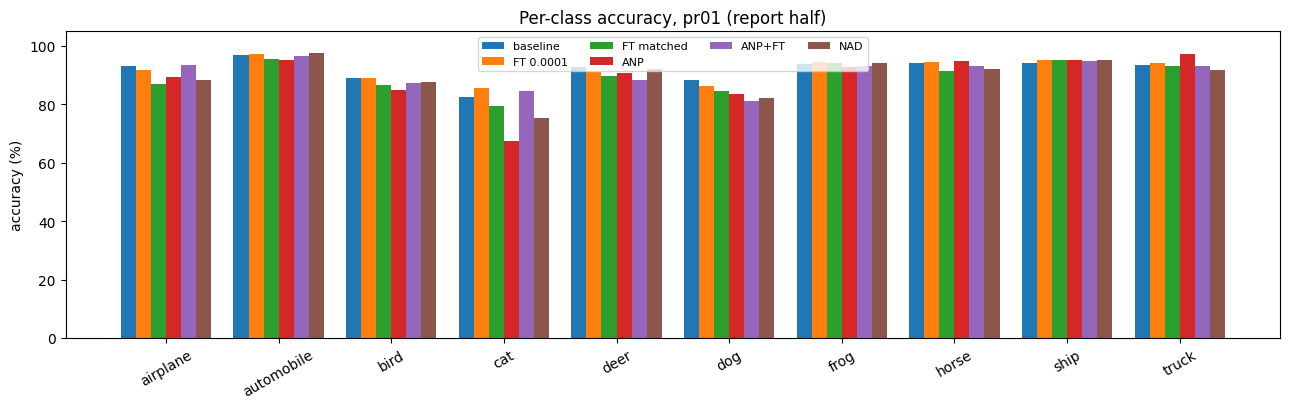

In [26]:
# ════════════════════════════════════════════════════════════════════════
# Cell F2 — Per-class accuracy + natural airplane-prediction rate (baseline / defended / clean control)
# ════════════════════════════════════════════════════════════════════════
@torch.no_grad()
def per_class_report(model):
    model.eval(); P, Y = [], []
    for x, y in test_loader:
        P.append(model(x.to(DEVICE)).argmax(1).cpu()); Y.append(y)
    p, y = torch.cat(P).numpy(), torch.cat(Y).numpy()
    acc = [float((p[y == c] == c).mean()) for c in range(NUM_CLASSES)]
    nt = y != TARGET_CLASS
    return acc, float((p[nt] == TARGET_CLASS).mean())

_pc = []
for (t, v, p_) in verify_items:
    m = load_model(p_); acc, nat = per_class_report(m); asr = calculate_asr(m, asr_src_loader, TARGET_CLASS, DEVICE); del m
    _pc.append({'pr_tag': t, 'variant': v, **{f'acc_{CIFAR10_CLASSES[c]}': round(acc[c] * 100, 2) for c in range(NUM_CLASSES)},
                'mean_class_acc': round(float(np.mean(acc)) * 100, 2), 'clean_nontarget_to_airplane_pct': round(nat * 100, 3),
                'ASR_src_pct': round(asr * 100, 3)})
perclass_df = pd.DataFrame(_pc); perclass_df.to_csv(f"{SUBDIRS['csv']}/sk_per_class_accuracy.csv", index=False)
print('PER-CLASS ACCURACY (report half, %) + natural airplane-prediction rate'); print(perclass_df.to_string(index=False))
for t in TAGS:
    d = perclass_df[perclass_df.pr_tag == t].set_index('variant')
    if 'baseline' not in d.index: continue
    floor = d.loc['baseline', 'clean_nontarget_to_airplane_pct']
    for v in d.index:
        if v == 'baseline': continue
        flag = ('  ← ASR_src is BELOW the baseline model\'s natural airplane rate: the model may simply under-predict airplane'
                if d.loc[v, 'ASR_src_pct'] < floor and d.loc[v, 'clean_nontarget_to_airplane_pct'] < floor else '')
        print(f"  {t} {v:12s}: airplane recall {d.loc['baseline','acc_airplane']:.1f}→{d.loc[v,'acc_airplane']:.1f}% | cat acc {d.loc['baseline','acc_cat']:.1f}→{d.loc[v,'acc_cat']:.1f}% | "
              f"clean→airplane {floor:.2f}→{d.loc[v,'clean_nontarget_to_airplane_pct']:.2f}% | ASR_src {d.loc[v,'ASR_src_pct']:.2f}%{flag}")
_first = perclass_df[perclass_df.pr_tag == TAGS[0]]
fig, ax = plt.subplots(figsize=(13, 4.2)); _w = 0.8 / max(1, len(_first)); _x = np.arange(NUM_CLASSES)
for _i, (_, _r) in enumerate(_first.iterrows()):
    ax.bar(_x + _i * _w, [_r[f'acc_{n}'] for n in CIFAR10_CLASSES], _w, label=VARIANT_LABEL.get(_r['variant'], _r['variant']))
ax.set_xticks(_x + 0.4 - _w / 2); ax.set_xticklabels(CIFAR10_CLASSES, rotation=30); ax.set_ylabel('accuracy (%)'); ax.set_ylim(0, 105)
ax.set_title(f'Per-class accuracy, {TAGS[0]} (report half)'); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(f"{SUBDIRS['fig']}/sk_per_class_accuracy.png", dpi=150); plt.show()

## Section G — Post-defence record for the controller and later project stages

Everything the controller state `s = (d, a, u, c)`, the fingerprint cache and the post-deployment monitor need, **measured after defence on the report half**:

* **d** (severity): Activation-Clustering silhouette / suspicious-fraction / PDR / recall (PCA-2D and ICA-10D) on the poisoned training set — baseline vs. each defended model. Needs `silentkiller_poison_idx_{tag}.npy` + `silentkiller_poisoned_pixels_{tag}.npy` from the attack notebook.
* **a**: `ASR_src`, `ASR_all` (report), `ASR_val_src` (validation).
* **u**: CA and CA drop. **c**: total cost in seconds (method-specific breakdown in the sidecar JSON).
* **STRIP after defence**: μ, σ, threshold (FRR 1 %), TPR, FPR, median entropies, AUROC → the numbers the post-deployment monitor needs as its calibrated reference.
* Attention-correlation r (+ bootstrap CI), per-class / natural airplane-rate summary, report-half CA-budget flag; method extras (BaEraser: accepted triggers, fresh-audit / UAP ASR, oracle upper bound; NAD: teacher/student lr, teacher ASR, validity; ANP: threshold, neurons pruned).

In [27]:
# ════════════════════════════════════════════════════════════════════════
# Cell G1 — Post-defence Activation Clustering (severity signals) for baseline + defended models   [v4.1: files from B5, two groupings]
# ════════════════════════════════════════════════════════════════════════
import io, contextlib

@torch.no_grad()
def ac_signals(model, tag, chunk=1000):
    found = POISON_FILES.get(tag)                                  # located + validated in B5
    if not found:
        return None
    ip, pp, _how = found
    pidx = np.load(ip, allow_pickle=False).astype(int); pix = torch.from_numpy(np.load(pp)).float()
    assert len(pidx) == len(pix), 'poison idx / pixels length mismatch'
    where = {int(i): k for k, i in enumerate(pidx)}
    feats, preds, buf = [], [], []
    h = model.avgpool.register_forward_hook(lambda m, i, o: buf.append(o.detach().flatten(1).cpu()))
    model.eval()
    for s in range(0, len(train_u8), chunk):
        x = u8_to_float(train_u8[s:s + chunk])
        for j in range(len(x)):
            k = where.get(s + j)
            if k is not None: x[j] = pix[k]                      # the ACTUAL poisoned training pixels
        buf.clear(); out = model(norm(x).to(DEVICE)); feats.append(buf[0].numpy()); preds.append(out.argmax(1).cpu().numpy())
    h.remove()
    X, yp = np.concatenate(feats), np.concatenate(preds)
    # v4.1: the SAME penultimate features, clustered per class under two groupings:
    #   'predicted' — class = the model's prediction on the (poisoned) training image   (original G1 behaviour → AC_* columns)
    #   'label'     — class = the training label (clean-label SK: poisoned images carry the TARGET label) (→ AC_LBL_* columns)
    groupings = {'predicted': yp, 'label': train_y}
    out = {'n_pred_target': int((yp == TARGET_CLASS).sum()), 'n_label_target': int((train_y == TARGET_CLASS).sum())}
    for gname in AC_GROUP_BY:
        if gname not in groupings:
            continue
        res = {}
        for label, (use_pca, k) in {'PCA2D': (True, 2), 'ICA10D': (False, 2)}.items():
            try:
                with contextlib.redirect_stdout(io.StringIO()):
                    r = run_ac(X, groupings[gname], np.arange(len(X)), pidx, target_class=TARGET_CLASS, seed=SEED, use_pca=use_pca, pca_components=k)
                res[label] = {kk: r[kk] for kk in ['silhouette', 'suspicious_fraction', 'PDR', 'recall']}
                res[label]['cluster_sizes'] = list(map(int, r['cluster_sizes']))
            except Exception as e:
                res[label] = {'error': str(e)[:120]}
        out[gname] = res
    return out

AC_ROWS, _ac_skipped = [], set()
if RUN_POST_AC:
    ac_items = [(t, 'baseline', sk_ckpt(t)) for t in TAGS] + [(t, v, CKPT_REGISTRY[(t, v)]) for t in TAGS for v in PRIMARY_VARIANTS if (t, v) in CKPT_REGISTRY]
    for (t, v, p) in ac_items:
        if not POISON_FILES.get(t):
            if t not in _ac_skipped:
                print(f'  [{t}] AC skipped for ALL variants — poison idx/pixels files not found (see the B5 pre-flight message)'); _ac_skipped.add(t)
            continue
        r = ac_signals(load_model(p), t)
        row = {'pr_tag': t, 'variant': v, 'n_pred_target': r['n_pred_target'], 'n_label_target': r['n_label_target']}
        for gname, pref in (('predicted', 'AC_'), ('label', 'AC_LBL_')):
            if gname not in r:
                continue
            for lab in ['PCA2D', 'ICA10D']:
                for kk in ['silhouette', 'suspicious_fraction', 'PDR', 'recall']:
                    row[f'{pref}{lab}_{kk}'] = r[gname][lab].get(kk)
                row[f'{pref}{lab}_cluster_sizes'] = r[gname][lab].get('cluster_sizes')
        AC_ROWS.append(row)
ac_df = pd.DataFrame(AC_ROWS)
if len(ac_df):
    ac_df.to_csv(f"{SUBDIRS['csv']}/sk_post_defense_ac.csv", index=False)
    _is_pred = lambda c: c.startswith('AC_') and not c.startswith('AC_LBL_')
    _metr = ('silhouette', 'suspicious_fraction', 'PDR')
    print('AC grouped by PREDICTED class (original columns AC_*)')
    print(ac_df[['pr_tag', 'variant', 'n_pred_target'] + [c for c in ac_df.columns if _is_pred(c) and c.endswith(_metr)]].round(4).to_string(index=False))
    if any(c.startswith('AC_LBL_') for c in ac_df.columns):
        print('\nAC grouped by training LABEL (AC_LBL_*)')
        print(ac_df[['pr_tag', 'variant', 'n_label_target'] + [c for c in ac_df.columns if c.startswith('AC_LBL_') and c.endswith(_metr)]].round(4).to_string(index=False))
    _ref = f'{DRIVE_ROOT}/silentkiller_dr_comparison.csv'
    if os.path.isfile(_ref):
        _r = pd.read_csv(_ref); _cmp = []
        for t in TAGS:
            b = ac_df[(ac_df.pr_tag == t) & (ac_df.variant == 'baseline')]
            if b.empty: continue
            b = b.iloc[0]; row = {'pr_tag': t}
            for lab, m in (('PCA2D', 'PCA-2D'), ('ICA10D', 'ICA-10D')):
                ref = _r[(_r.pr_tag == t) & (_r.dr_method == m)]
                for kk, rk in (('silhouette', 'silhouette_score'), ('PDR', 'PDR')):
                    row[f'{lab}_{kk}: predicted'] = b.get(f'AC_{lab}_{kk}'); row[f'{lab}_{kk}: label'] = b.get(f'AC_LBL_{lab}_{kk}')
                    row[f'{lab}_{kk}: attack nb'] = None if ref.empty else ref[rk].iloc[0]
            _cmp.append(row)
        if _cmp:
            _cd = pd.DataFrame(_cmp); _cd.to_csv(f"{SUBDIRS['csv']}/sk_ac_pipeline_comparison.csv", index=False)
            print('\nBASELINE AC — this notebook (both groupings) vs the attack notebook (silentkiller_dr_comparison.csv):')
            print(_cd.round(3).T.to_string(header=False))
            print('The grouping whose numbers match the attack notebook explains the discrepancy. Choose ONE canonical pipeline for the controller '
                  'and record the choice in docs/05_DETECTION_AND_VERIFICATION.md (per-attack DR/grouping table).')
else:
    print('No AC rows (RUN_POST_AC off, or poison files missing for every tag — see B5).')


  [pr01] AC skipped for ALL variants — poison idx/pixels files not found (see the B5 pre-flight message)
AC grouped by PREDICTED class (original columns AC_*)
pr_tag    variant  n_pred_target  AC_PCA2D_silhouette  AC_PCA2D_suspicious_fraction  AC_PCA2D_PDR  AC_ICA10D_silhouette  AC_ICA10D_suspicious_fraction  AC_ICA10D_PDR
  pr05   baseline           5014               0.5653                        0.4888         99.14                0.1583                         0.4860          99.96
  pr10   baseline           5000               0.4416                        0.2902        100.00                0.2397                         0.2284         100.00
  pr05 ft_lr1em04           5029               0.6894                        0.4939        100.00                0.2746                         0.4955          99.96
  pr05 ft_matched           5265               0.4600                        0.4621         82.59                0.0957                         0.4427          97.73
  pr05     

In [28]:
# ════════════════════════════════════════════════════════════════════════
# Cell G2 — CONTROLLER RECORD: every post-defence value in one table (+ POST-DEFENCE STRIP table + fingerprints)
# ════════════════════════════════════════════════════════════════════════
def _get(df, t, v, col):
    if df is None or not len(df): return None
    r = df[(df.pr_tag == t) & (df.variant == v)]
    return None if r.empty or col not in r.columns else r.iloc[0][col]

rec_rows = []
for t in TAGS:
    b = BASELINE[t]
    base = {'pr_tag': t, 'poison_rate': PR_MAP[t], 'variant': 'baseline', 'defense': 'none', 'status': 'BASELINE',
            'CA': b['CA'], 'CA_drop_pp': 0.0, 'ASR_src': b['ASR_src'], 'ASR_all': b['ASR_all'], 'ASR_val_src': b['ASR_val_src'],
            'ASR_src_minus_floor_pp': None if FLOOR_SRC is None else round((b['ASR_src'] - FLOOR_SRC) * 100, 2), 'cost_seconds': 0.0,
            'CA_full_test': b['CA_full'], 'ASR_src_full_test': b['ASR_src_full']}
    rows = [base]
    for r in [x for x in RESULTS if x['pr_tag'] == t and x['variant'] in PRIMARY_VARIANTS]:
        rows.append({'pr_tag': t, 'poison_rate': PR_MAP[t], 'variant': r['variant'], 'defense': r['defense'], 'status': r['status'],
                     'verdict': r.get('verdict'), 'valid_run': r.get('valid_run'), 'interpretable': r.get('interpretable'),
                     'CA': r['CA_after'], 'CA_drop_pp': r.get('CA_drop_pp'), 'ASR_src': r['ASR_src_after'], 'ASR_all': r['ASR_all_after'],
                     'ASR_val_src': r.get('ASR_val_src_after'), 'ASR_src_drop_pp': r.get('ASR_src_drop_pp'),
                     'ASR_src_minus_floor_pp': r.get('ASR_src_minus_floor_pp'), 'clean_same_defence_ASR_src': r.get('clean_same_defence_ASR_src'),
                     'residual_vs_clean_same_defence_pp': r.get('residual_vs_clean_same_defence_pp'), 'generic_transfer_drop_pp': r.get('generic_transfer_drop_pp'),
                     'cost_seconds': r['seconds'], 'selection_rule': r.get('selection_rule'),
                     'report_ca_budget_violated': r.get('report_ca_budget_violated'),
                     'notes': r.get('notes')})
    for row in rows:
        v = row['variant']
        for col in ['STRIP_mu', 'STRIP_sigma', 'STRIP_threshold', 'STRIP_TPR', 'STRIP_FPR', 'STRIP_median_ent_clean',
                    'STRIP_median_ent_triggered', 'STRIP_AUROC', 'attn_corr_r', 'attn_ci_lo', 'attn_ci_hi', 'trig_to_target_rate']:
            row[col] = _get(verify_df, t, v, col)
        for col in ['mean_class_acc', 'clean_nontarget_to_airplane_pct', 'acc_airplane', 'acc_cat']:
            row['pc_' + col] = _get(perclass_df, t, v, col)
        for col in [c for c in (ac_df.columns if len(ac_df) else []) if c.startswith('AC_') or c == 'n_pred_target']:
            row[col] = _get(ac_df, t, v, col)
        inf = INFOS.get((t, v), {})
        if v == 'baeraser' and inf:
            sm = inf.get('summary', {})
            row.update({'bae_recovery_mode': inf.get('recovery_mode'), 'bae_n_accepted': sm.get('n_accepted'), 'bae_max_candidate_asr': sm.get('max_candidate_asr'),
                        'bae_selected_epoch': sm.get('selected_epoch'), 'bae_oracle_UPPER_BOUND_ASR': sm.get('oracle_ASR'),
                        'bae_sel_proxy_ASR': sm.get('sel_proxy_ASR'), 'bae_sel_fresh_ASR': sm.get('sel_fresh_ASR'),
                        'bae_fresh_audit_asr_poisoned': inf.get('audit_poisoned_reference', {}).get('fresh_max_asr'),
                        'bae_fresh_audit_asr_sanitised': inf.get('audit_sanitised', {}).get('fresh_max_asr'),
                        'bae_fresh_audit_asr_clean': CLEAN_AUDIT.get('fresh_max_asr') if CLEAN_AUDIT else None,
                        'bae_uap_asr_poisoned': inf.get('audit_poisoned_reference', {}).get('uap_asr'),
                        'bae_uap_asr_sanitised': inf.get('audit_sanitised', {}).get('uap_asr'),
                        'bae_uap_asr_clean': CLEAN_AUDIT.get('uap_asr') if CLEAN_AUDIT else None,
                        'bae_recovery_s': sm.get('recovery_s'), 'bae_unlearning_s': sm.get('unlearning_s')})
        if v == 'nad' and inf:
            row.update({'nad_teacher_lr': inf.get('teacher_lr'), 'nad_student_lr': inf.get('student_lr'), 'nad_beta_scale': inf.get('beta_scale'),
                        'nad_teacher_asr_val': (inf.get('teacher') or {}).get('teacher_asr'), 'nad_teacher_asr_flag': (inf.get('teacher') or {}).get('teacher_asr_flag'),
                        'nad_teacher_student_distinct': inf.get('teacher_student_distinct'),
                        'nad_search_sec': inf.get('search_sec_total'), 'nad_teacher_ft_sec': inf.get('teacher_ft_sec'), 'nad_distill_sec': inf.get('distill_sec'),
                        'nad_recipe_version': inf.get('recipe_version'), 'nad_repro_hash_match': inf.get('repro_hash_match'),
                        'nad_repro_val_ca_delta_pp': inf.get('repro_val_ca_delta_pp')})
        if v == 'anp' and inf:
            ov = inf.get('oracle_val_upper_bound') or {}
            row.update({'anp_threshold': inf.get('threshold'), 'anp_n_pruned': inf.get('n_pruned'), 'anp_n_total': inf.get('n_total'),
                        'anp_select_rule': inf.get('select_rule'), 'anp_select_gate_pp': inf.get('select_gate_pp'),
                        'anp_ORACLE_VAL_threshold': ov.get('threshold'), 'anp_ORACLE_VAL_report_ASR_src': ov.get('report_ASR_src'),
                        'anp_ORACLE_VAL_report_CA': ov.get('report_CA')})
        if v == 'anp_ft' and inf:
            row.update({'anp_ft_n_pruned_held_zero': inf.get('n_pruned_held_zero'), 'anp_ft_threshold': inf.get('threshold'), 'anp_ft_sec': inf.get('ft_sec')})
    rec_rows += rows
controller_df = pd.DataFrame(rec_rows)
controller_df.to_csv(f"{SUBDIRS['record']}/sk_controller_record.csv", index=False)
_cl = [x for x in RESULTS if x['pr_tag'] == 'clean']                       # v4.1: clean-model defence control rows (not part of the per-tag record)
if _cl: pd.DataFrame(_cl).to_csv(f"{SUBDIRS['record']}/sk_clean_defence_control_rows.csv", index=False)
json.dump(controller_df.where(controller_df.notna(), None).to_dict('records'), open(f"{SUBDIRS['record']}/sk_controller_record.json", 'w'), indent=2, default=to_py)

print('=' * 78); print('POST-DEFENCE (STRIP) — report half; threshold at FRR = %.0f%%' % (STRIP_FRR * 100)); print('=' * 78)
_sc = ['pr_tag', 'variant', 'STRIP_mu', 'STRIP_sigma', 'STRIP_threshold', 'STRIP_TPR', 'STRIP_FPR', 'STRIP_AUROC', 'attn_corr_r', 'attn_ci_lo', 'attn_ci_hi']
print(controller_df[[c for c in _sc if c in controller_df.columns]].round(4).to_string(index=False))
print('\n' + '=' * 78); print('CONTROLLER STATE  s = (d, a, u, c)  per checkpoint'); print('=' * 78)
_cc = ['pr_tag', 'variant', 'AC_PCA2D_silhouette', 'AC_PCA2D_suspicious_fraction', 'ASR_src', 'ASR_all', 'CA', 'CA_drop_pp', 'cost_seconds', 'status']
print(controller_df[[c for c in _cc if c in controller_df.columns]].round(4).to_string(index=False))

# Fingerprint vectors (severity signature of each BASELINE poisoned model) for the cosine matcher in Phase-2
_fp_cols = ['AC_PCA2D_silhouette', 'AC_PCA2D_suspicious_fraction', 'STRIP_mu', 'STRIP_sigma', 'STRIP_TPR', 'attn_corr_r', 'ASR_src']   # (unchanged definition)
fps = {t: {c: (None if pd.isna(x := _get(controller_df, t, 'baseline', c)) else float(x)) for c in _fp_cols} for t in TAGS}
json.dump(fps, open(f"{SUBDIRS['record']}/sk_fingerprints.json", 'w'), indent=2)
print('\nFingerprints (baseline signatures):'); print(pd.DataFrame(fps).T.round(4).to_string())
print(f"\nSaved → {SUBDIRS['record']}/sk_controller_record.csv|json , sk_fingerprints.json")

POST-DEFENCE (STRIP) — report half; threshold at FRR = 1%
pr_tag    variant  STRIP_mu  STRIP_sigma  STRIP_threshold  STRIP_TPR  STRIP_FPR  STRIP_AUROC  attn_corr_r  attn_ci_lo  attn_ci_hi
  pr01   baseline    0.6219       0.1949           0.1685        7.0        1.4       0.5247       0.2726      0.2041      0.3385
  pr01 ft_lr1em04    0.6743       0.2051           0.1972        3.4        1.2       0.3859       0.3332      0.2634      0.4033
  pr01        anp    1.2986       0.3325           0.5252        2.0        2.8       0.3975       0.3594      0.2973      0.4236
  pr01     anp_ft    0.8155       0.2339           0.2714        1.8        1.4       0.3542       0.3810      0.3113      0.4451
  pr01        nad    0.6820       0.2084           0.1971        0.6        2.0       0.2329       0.4057      0.3391      0.4706
  pr01 ft_matched    0.7308       0.2185           0.2224        0.4        2.6       0.4534       0.3131      0.2459      0.3786
  pr01   baeraser       NaN     

## Section H — Visualising what actually changed

A defence does not change the *images* — it changes how the *model reacts* to them. These cells show (H1) the trigger on real images and every model's prediction, (H2) Grad-CAM before/after, (H3) how the probability of "airplane" shifts and which images were actually rescued, (H4) true vs recovered triggers from BaEraser, (H5) STRIP entropy distributions before/after. All images come from the **report half**.

In [29]:
# ════════════════════════════════════════════════════════════════════════
# Cell H0 — Models + image selection for the visualisations
# ════════════════════════════════════════════════════════════════════════
VIZ_TAG = TAGS[0]
VIZ_MODELS = OrderedDict([('baseline (poisoned)', load_model(sk_ckpt(VIZ_TAG)))])
for v in PRIMARY_VARIANTS:
    if (VIZ_TAG, v) in CKPT_REGISTRY: VIZ_MODELS[VARIANT_LABEL[v]] = load_model(CKPT_REGISTRY[(VIZ_TAG, v)])
if os.path.isfile(CLEAN_BASELINE_CKPT): VIZ_MODELS['clean model'] = load_model(CLEAN_BASELINE_CKPT)

@torch.no_grad()
def predict(model, x_raw):                           # x_raw (B,3,32,32) raw -> (pred, P(airplane))
    p = F.softmax(model(norm(x_raw).to(DEVICE)), 1).cpu()
    return p.argmax(1), p[:, TARGET_CLASS]

# prefer cats on which the attack SUCCEEDS against the baseline (so a rescue is visible), fall back to random cats
_rs = np.random.RandomState(SEED + 1)
_cand = _rs.permutation(src_report)
_pred_b, _ = predict(VIZ_MODELS['baseline (poisoned)'], apply_trigger_raw(X_TEST_RAW[_cand[:300]]))
_hits = [int(i) for i, p in zip(_cand[:300], _pred_b) if int(p) == TARGET_CLASS]
VIZ_IDX = (_hits + [int(i) for i in _cand if int(i) not in set(_hits)])[:N_VIZ]
VIZ_X = X_TEST_RAW[VIZ_IDX]; VIZ_XT = apply_trigger_raw(VIZ_X)
print(f'VIZ tag={VIZ_TAG} | models: {list(VIZ_MODELS)} | {len(VIZ_IDX)} report cats (attack-successful on baseline: {len(_hits)} found)')
_show = lambda t: t.permute(1, 2, 0).clamp(0, 1).numpy()
_amp  = lambda d: (d / (2 * SK_LINF) + 0.5).permute(1, 2, 0).clamp(0, 1).numpy()

VIZ tag=pr01 | models: ['baseline (poisoned)', 'FT 0.0001', 'FT matched', 'ANP', 'ANP+FT', 'NAD', 'clean model'] | 6 report cats (attack-successful on baseline: 271 found)


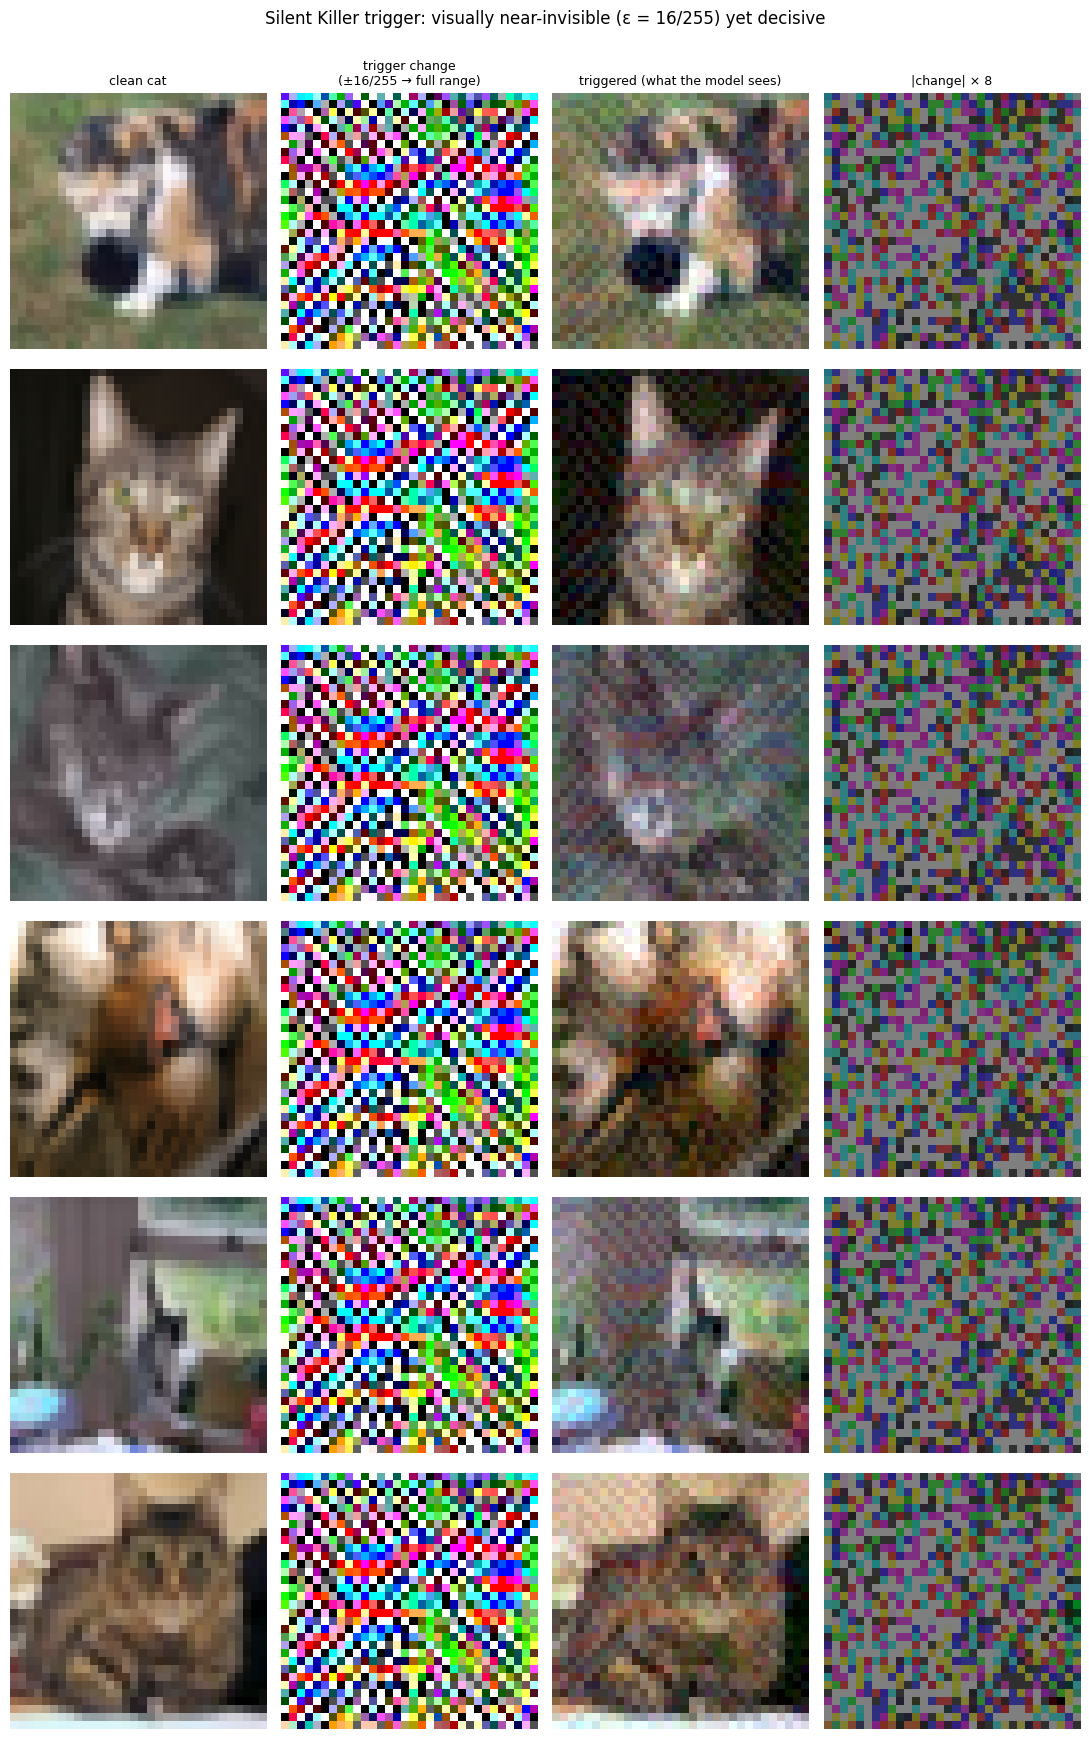

Prediction on the TRIGGERED image, per model (P_air = probability of the target class):
 img true               baseline (poisoned)                         FT 0.0001                        FT matched                               ANP                            ANP+FT                               NAD                  clean model
5881  cat airplane (P_air=1.00) [clean→dog] airplane (P_air=1.00) [clean→dog] airplane (P_air=0.87) [clean→dog] airplane (P_air=0.97) [clean→dog] airplane (P_air=1.00) [clean→dog] airplane (P_air=0.96) [clean→dog] cat (P_air=0.16) [clean→dog]
4886  cat             airplane (P_air=0.99)             airplane (P_air=0.81)                  cat (P_air=0.00)             airplane (P_air=0.42)                  cat (P_air=0.04)                  cat (P_air=0.00)             cat (P_air=0.30)
5773  cat             airplane (P_air=1.00)             airplane (P_air=1.00)                 bird (P_air=0.34)             airplane (P_air=0.94)             airplane (P_air=0.94)    

In [30]:
# ════════════════════════════════════════════════════════════════════════
# Cell H1 — The trigger on real images + every model's prediction
# ════════════════════════════════════════════════════════════════════════
fig, axs = plt.subplots(len(VIZ_IDX), 4, figsize=(11, 2.9 * len(VIZ_IDX)), squeeze=False)
for r in range(len(VIZ_IDX)):
    diff = (VIZ_XT[r] - VIZ_X[r])
    for c, (im, ttl) in enumerate([(_show(VIZ_X[r]), 'clean cat'), (_amp(diff), 'trigger change\n(±16/255 → full range)'),
                                   (_show(VIZ_XT[r]), 'triggered (what the model sees)'), (_show((diff.abs() * 8)), '|change| × 8')]):
        axs[r, c].imshow(im, interpolation='nearest'); axs[r, c].axis('off')
        axs[r, c].set_title(ttl if r == 0 else '', fontsize=9)
    axs[r, 0].set_ylabel(f'#{VIZ_IDX[r]}')
plt.suptitle('Silent Killer trigger: visually near-invisible (ε = 16/255) yet decisive', y=1.0); plt.tight_layout()
plt.savefig(f"{SUBDIRS['fig']}/sk_viz_trigger_gallery.png", dpi=150, bbox_inches='tight'); plt.show()

rows = []
for i in range(len(VIZ_IDX)):
    row = {'img': VIZ_IDX[i], 'true': 'cat'}
    for name, m in VIZ_MODELS.items():
        pc, _ = predict(m, VIZ_X[i:i + 1]); pt, pa = predict(m, VIZ_XT[i:i + 1])
        row[name] = f'{CIFAR10_CLASSES[int(pt)]} (P_air={float(pa):.2f})' + ('' if int(pc) == SOURCE_CLASS else f' [clean→{CIFAR10_CLASSES[int(pc)]}]')
    rows.append(row)
pred_table = pd.DataFrame(rows); pred_table.to_csv(f"{SUBDIRS['csv']}/sk_viz_predictions.csv", index=False)
print('Prediction on the TRIGGERED image, per model (P_air = probability of the target class):')
print(pred_table.to_string(index=False))

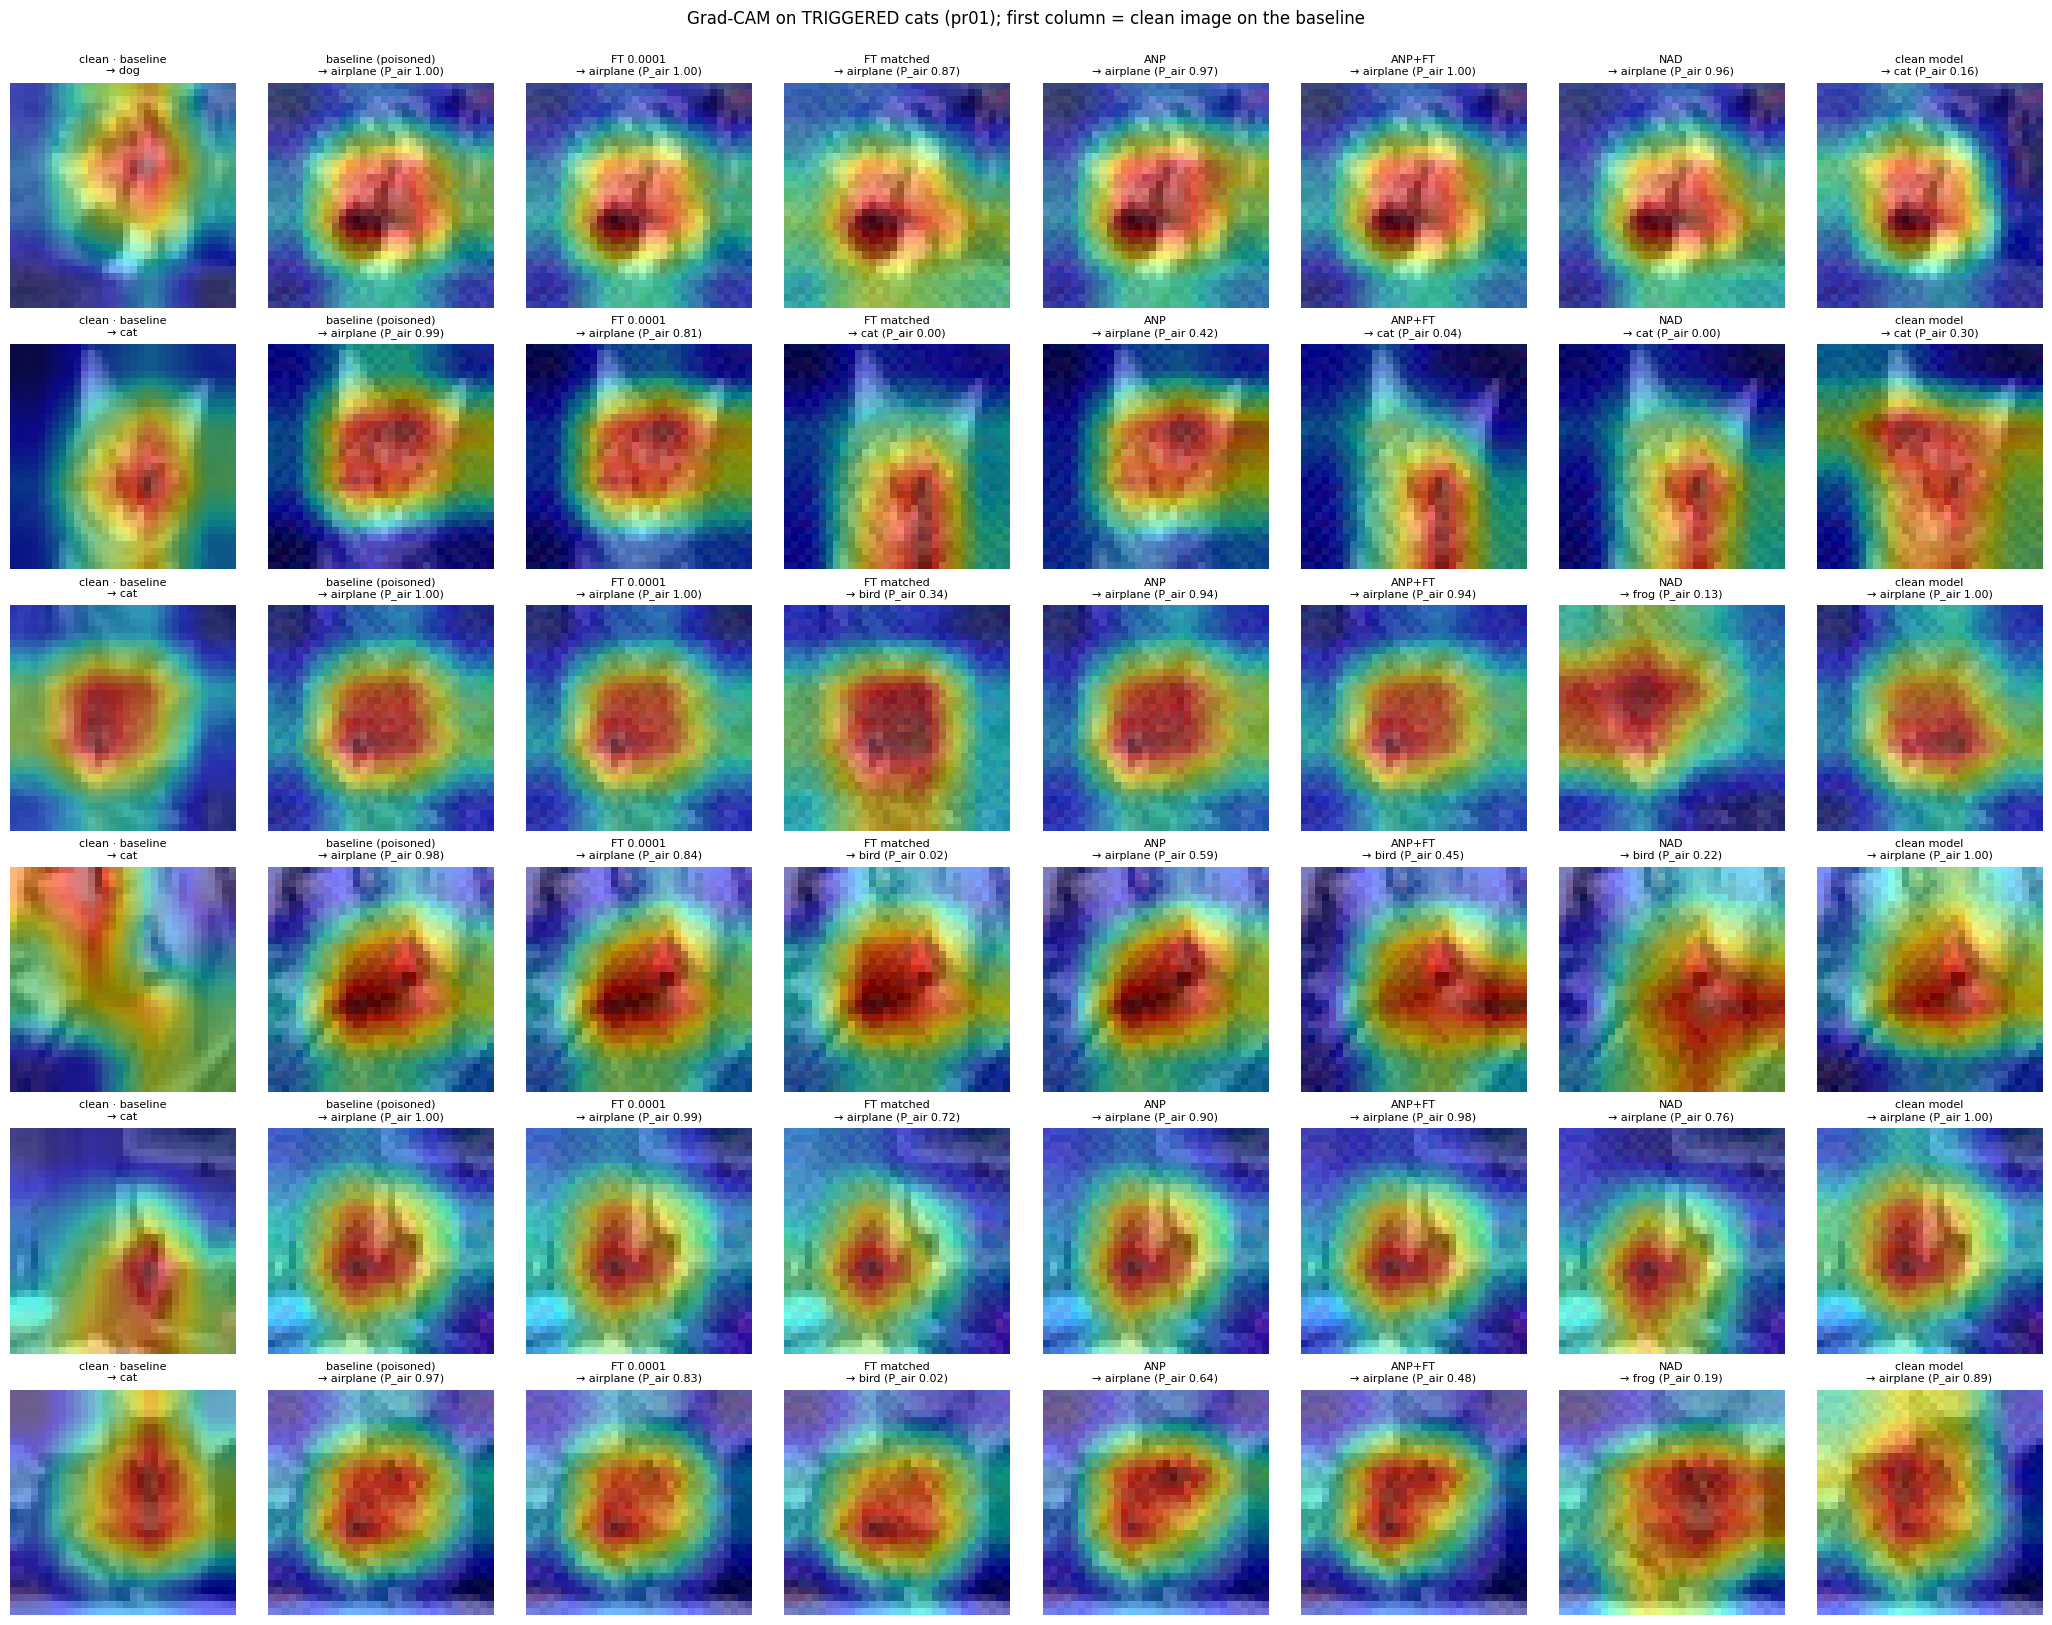

In [31]:
# ════════════════════════════════════════════════════════════════════════
# Cell H2 — Grad-CAM before / after (where does each model look on the triggered image?)
# ════════════════════════════════════════════════════════════════════════
import matplotlib.cm as cm
def _overlay(img, cam, a=0.5):
    return (1 - a) * img + a * cm.jet(cam)[..., :3]

names = list(VIZ_MODELS)
fig, axs = plt.subplots(len(VIZ_IDX), 1 + len(names), figsize=(2.6 * (1 + len(names)), 2.7 * len(VIZ_IDX)), squeeze=False)
for r in range(len(VIZ_IDX)):
    g = GradCAM(VIZ_MODELS['baseline (poisoned)']); cc, pc, _ = g(norm(VIZ_X[r:r + 1]).to(DEVICE)); g.remove()
    axs[r, 0].imshow(_overlay(_show(VIZ_X[r]), cc)); axs[r, 0].set_title(f'clean · baseline\n→ {CIFAR10_CLASSES[pc]}' if True else '', fontsize=8); axs[r, 0].axis('off')
    for c, nm in enumerate(names, start=1):
        g = GradCAM(VIZ_MODELS[nm]); cam_t, pt, pa = g(norm(VIZ_XT[r:r + 1]).to(DEVICE)); g.remove()
        axs[r, c].imshow(_overlay(_show(VIZ_XT[r]), cam_t)); axs[r, c].axis('off')
        axs[r, c].set_title(f'{nm}\n→ {CIFAR10_CLASSES[pt]} (P_air {pa:.2f})', fontsize=8)
plt.suptitle(f'Grad-CAM on TRIGGERED cats ({VIZ_TAG}); first column = clean image on the baseline', y=1.0); plt.tight_layout()
plt.savefig(f"{SUBDIRS['fig']}/sk_viz_gradcam_before_after.png", dpi=140, bbox_inches='tight'); plt.show()

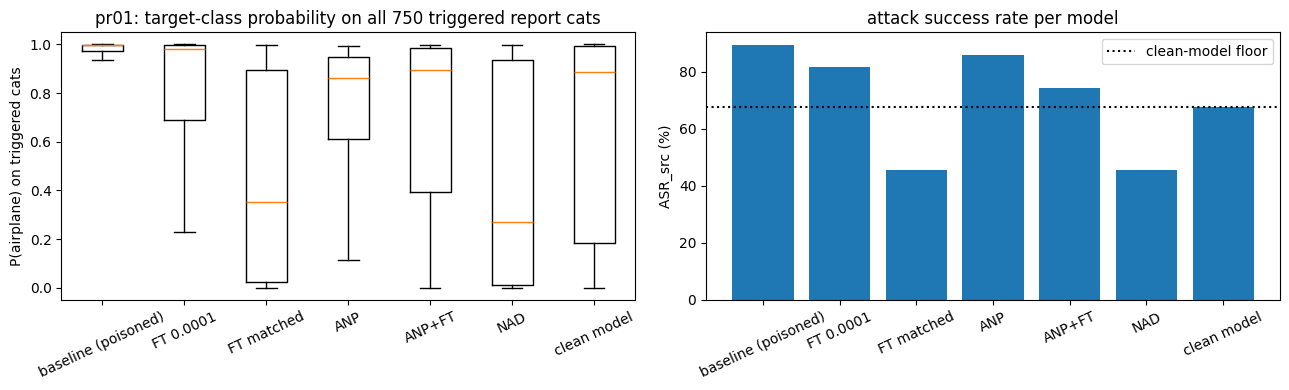

NAD: rescued 54 / 670 baseline-hijacked cats


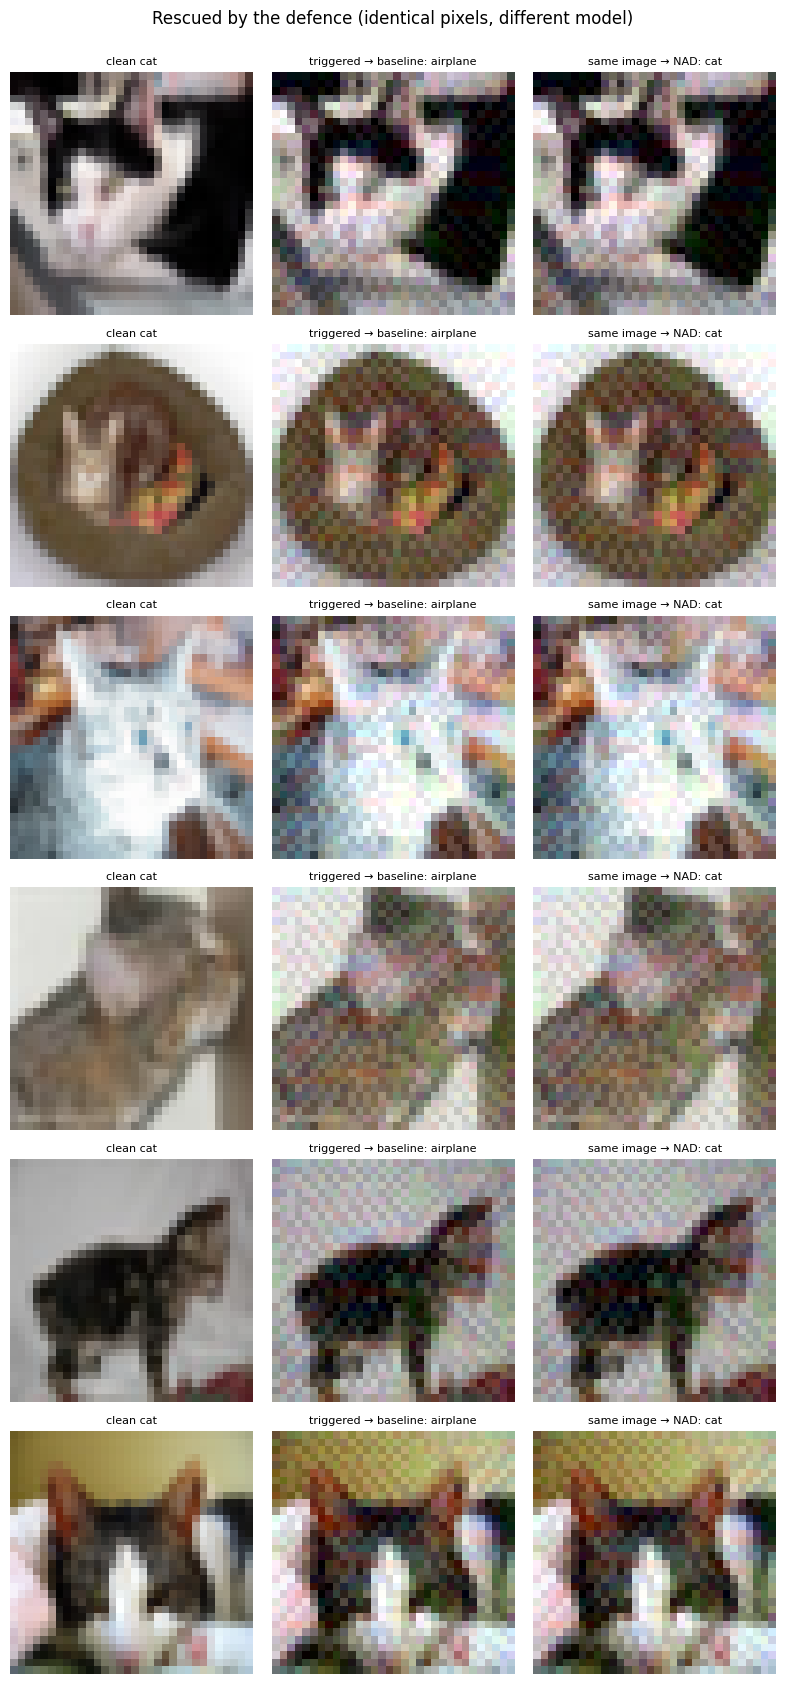

In [32]:
# ════════════════════════════════════════════════════════════════════════
# Cell H3 — P(airplane) shift over ALL report cats + images the defence actually rescued
# ════════════════════════════════════════════════════════════════════════
XS_T = apply_trigger_raw(X_TEST_RAW[src_report])
P_AIR, PRED_T = {}, {}
for nm, m in VIZ_MODELS.items():
    pr, pa = [], []
    for s in range(0, len(XS_T), 500):
        a, b = predict(m, XS_T[s:s + 500]); pr.append(a); pa.append(b)
    PRED_T[nm], P_AIR[nm] = torch.cat(pr), torch.cat(pa)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
try: ax[0].boxplot([P_AIR[n].numpy() for n in names], tick_labels=names, showfliers=False)
except TypeError: ax[0].boxplot([P_AIR[n].numpy() for n in names], labels=names, showfliers=False)
ax[0].set_ylabel('P(airplane) on triggered cats')
ax[0].set_title(f'{VIZ_TAG}: target-class probability on all {len(XS_T)} triggered report cats'); ax[0].tick_params(axis='x', rotation=25)
ax[1].bar(names, [float((PRED_T[n] == TARGET_CLASS).float().mean()) * 100 for n in names]); ax[1].set_ylabel('ASR_src (%)')
if FLOOR_SRC is not None: ax[1].axhline(FLOOR_SRC * 100, color='k', ls=':', label='clean-model floor'); ax[1].legend()
ax[1].set_title('attack success rate per model'); ax[1].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.savefig(f"{SUBDIRS['fig']}/sk_viz_prob_shift.png", dpi=150, bbox_inches='tight'); plt.show()

# rescued examples: baseline says airplane, defended model says the true class (cat)
defended = [n for n in names if n not in ('baseline (poisoned)', 'clean model')]
if defended:
    pick = defended[-1]                                   # last defence = BaEraser when present
    base_hit = PRED_T['baseline (poisoned)'] == TARGET_CLASS
    rescued = torch.where(base_hit & (PRED_T[pick] == SOURCE_CLASS))[0][:N_VIZ].tolist()
    print(f'{pick}: rescued {int((base_hit & (PRED_T[pick] == SOURCE_CLASS)).sum())} / {int(base_hit.sum())} baseline-hijacked cats')
    if rescued:
        fig, axs = plt.subplots(len(rescued), 3, figsize=(8, 2.8 * len(rescued)), squeeze=False)
        for r, k in enumerate(rescued):
            xr = X_TEST_RAW[src_report[k]]
            for c, (im, t) in enumerate([(_show(xr), 'clean cat'), (_show(XS_T[k]), f'triggered → baseline: {CIFAR10_CLASSES[int(PRED_T["baseline (poisoned)"][k])]}'),
                                         (_show(XS_T[k]), f'same image → {pick}: {CIFAR10_CLASSES[int(PRED_T[pick][k])]}')]):
                axs[r, c].imshow(im, interpolation='nearest'); axs[r, c].axis('off'); axs[r, c].set_title(t, fontsize=8)
        plt.suptitle('Rescued by the defence (identical pixels, different model)', y=1.0); plt.tight_layout()
        plt.savefig(f"{SUBDIRS['fig']}/sk_viz_rescued.png", dpi=140, bbox_inches='tight'); plt.show()

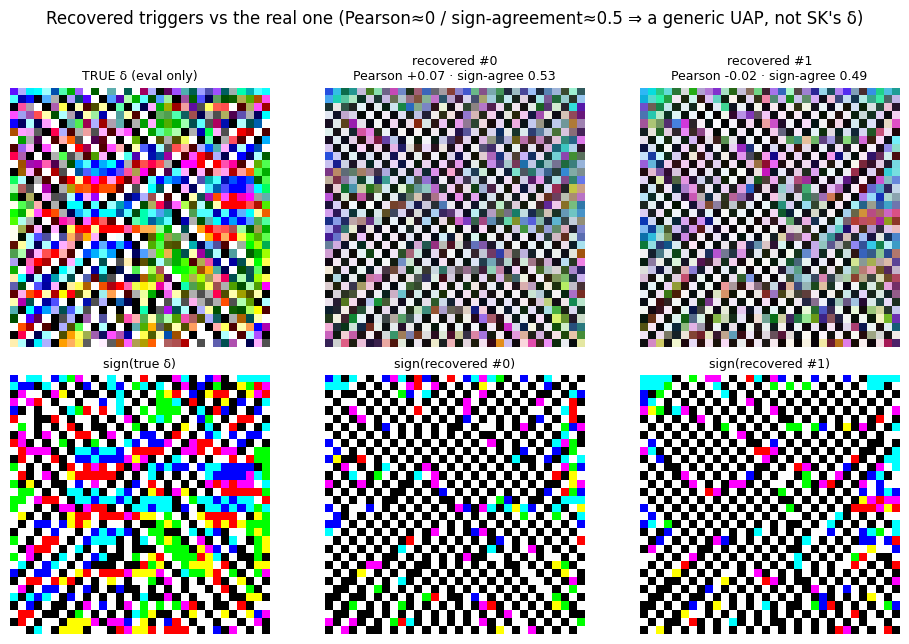

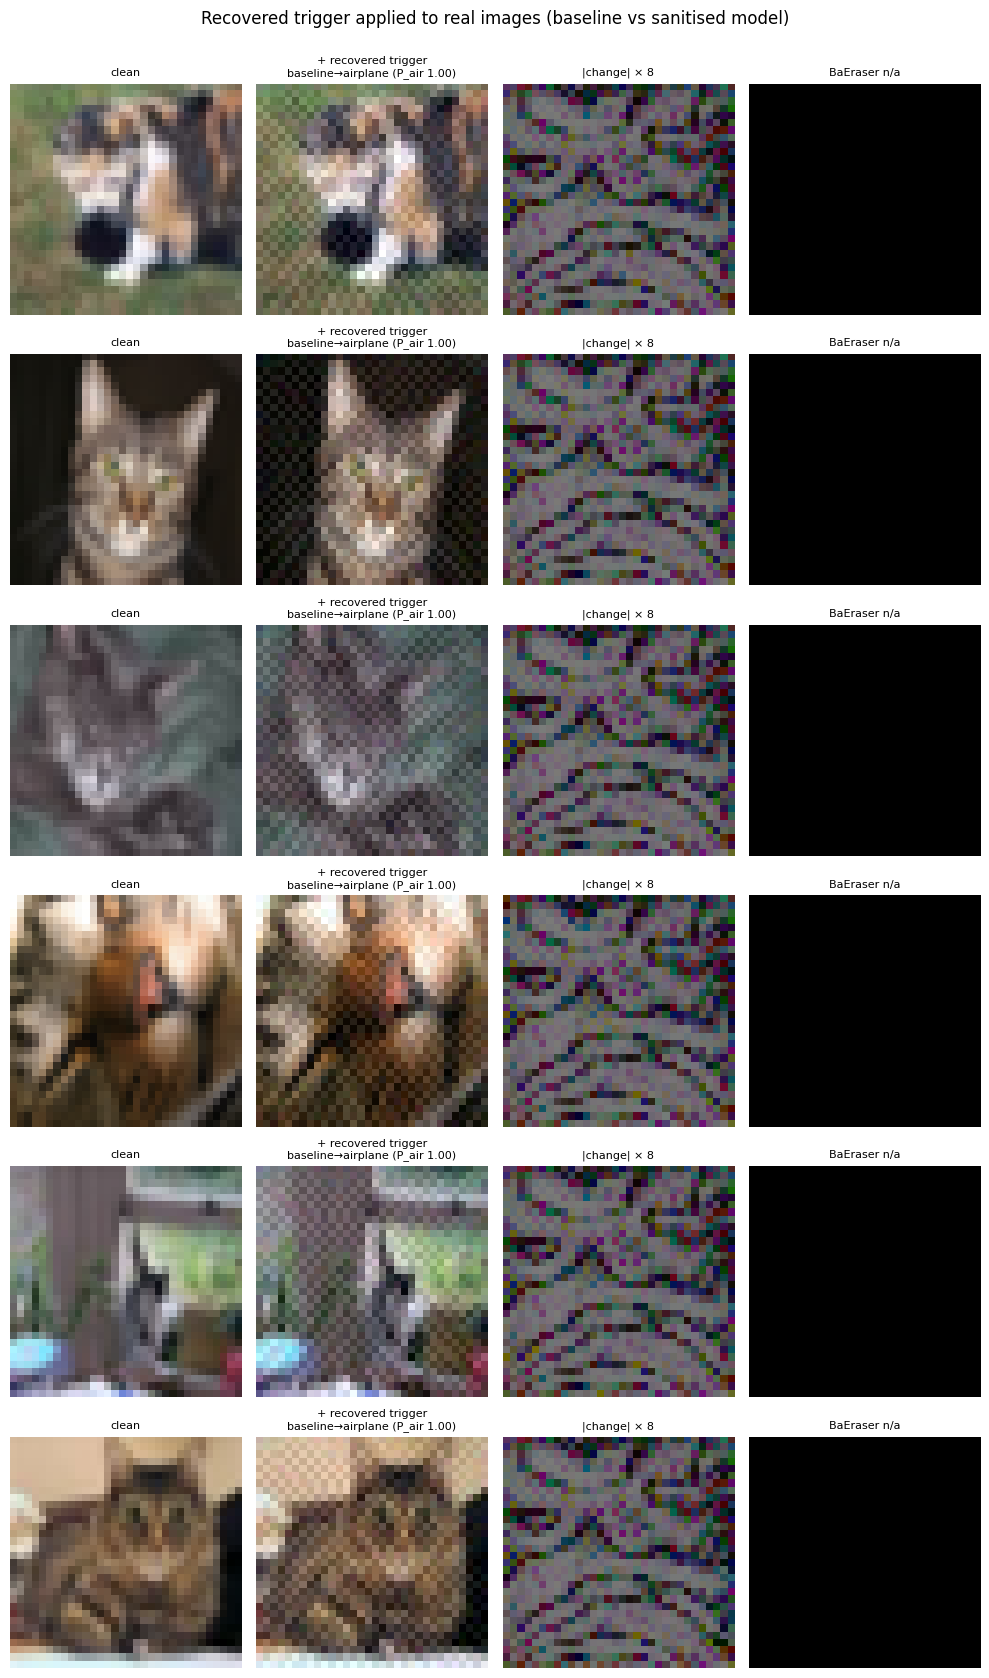

In [33]:
# ════════════════════════════════════════════════════════════════════════
# Cell H4 — BaEraser: TRUE δ vs RECOVERED triggers, and the recovered trigger applied to images
# ════════════════════════════════════════════════════════════════════════
_rec = sorted(Path(SUBDIRS['trigger']).glob(f'sk_recovered_{VIZ_TAG}_*.npy'))
if not _rec:
    print(f'No recovered triggers saved for {VIZ_TAG} (BaEraser failed or not run).')
else:
    recs = [torch.from_numpy(np.load(p)).float() for p in _rec][:3]
    deltas = [operator.to_delta(t) for t in recs]
    fig, axs = plt.subplots(2, 1 + len(recs), figsize=(3.2 * (1 + len(recs)), 6.4), squeeze=False)
    axs[0, 0].imshow(_amp(DELTA)); axs[0, 0].set_title('TRUE δ (eval only)', fontsize=9)
    axs[1, 0].imshow((DELTA > 0).float().numpy().transpose(1, 2, 0)); axs[1, 0].set_title('sign(true δ)', fontsize=9)
    for j, d in enumerate(deltas, start=1):
        pr = float(pearsonr(d.flatten().numpy(), DELTA.flatten().numpy())[0]); sg = float((torch.sign(d) == torch.sign(DELTA)).float().mean())
        axs[0, j].imshow(_amp(d)); axs[0, j].set_title(f'recovered #{j-1}\nPearson {pr:+.2f} · sign-agree {sg:.2f}', fontsize=9)
        axs[1, j].imshow((d > 0).float().numpy().transpose(1, 2, 0)); axs[1, j].set_title(f'sign(recovered #{j-1})', fontsize=9)
    for a in axs.ravel(): a.axis('off')
    plt.suptitle('Recovered triggers vs the real one (Pearson≈0 / sign-agreement≈0.5 ⇒ a generic UAP, not SK\'s δ)', y=1.0); plt.tight_layout()
    plt.savefig(f"{SUBDIRS['fig']}/sk_viz_recovered_vs_true.png", dpi=140, bbox_inches='tight'); plt.show()

    t0_ = recs[0]; xs = norm(VIZ_X)
    xr = (operator.apply(xs, t0_) * STD4 + MEAN4).clamp(0, 1)
    fig, axs = plt.subplots(len(VIZ_IDX), 4, figsize=(10, 2.8 * len(VIZ_IDX)), squeeze=False)
    mb, ms = VIZ_MODELS['baseline (poisoned)'], VIZ_MODELS.get('BaEraser')
    for r in range(len(VIZ_IDX)):
        pb, ab = predict(mb, xr[r:r + 1]); row = [(_show(VIZ_X[r]), 'clean'), (_show(xr[r]), f'+ recovered trigger\nbaseline→{CIFAR10_CLASSES[int(pb)]} (P_air {float(ab):.2f})'),
                                                   (_show((xr[r] - VIZ_X[r]).abs() * 8), '|change| × 8')]
        if ms is not None:
            ps, as_ = predict(ms, xr[r:r + 1]); row.append((_show(xr[r]), f'same image\nBaEraser→{CIFAR10_CLASSES[int(ps)]} (P_air {float(as_):.2f})'))
        else:
            row.append((np.zeros((32, 32, 3)), 'BaEraser n/a'))
        for c, (im, t) in enumerate(row):
            axs[r, c].imshow(im, interpolation='nearest'); axs[r, c].axis('off'); axs[r, c].set_title(t, fontsize=8)
    plt.suptitle('Recovered trigger applied to real images (baseline vs sanitised model)', y=1.0); plt.tight_layout()
    plt.savefig(f"{SUBDIRS['fig']}/sk_viz_recovered_applied.png", dpi=140, bbox_inches='tight'); plt.show()

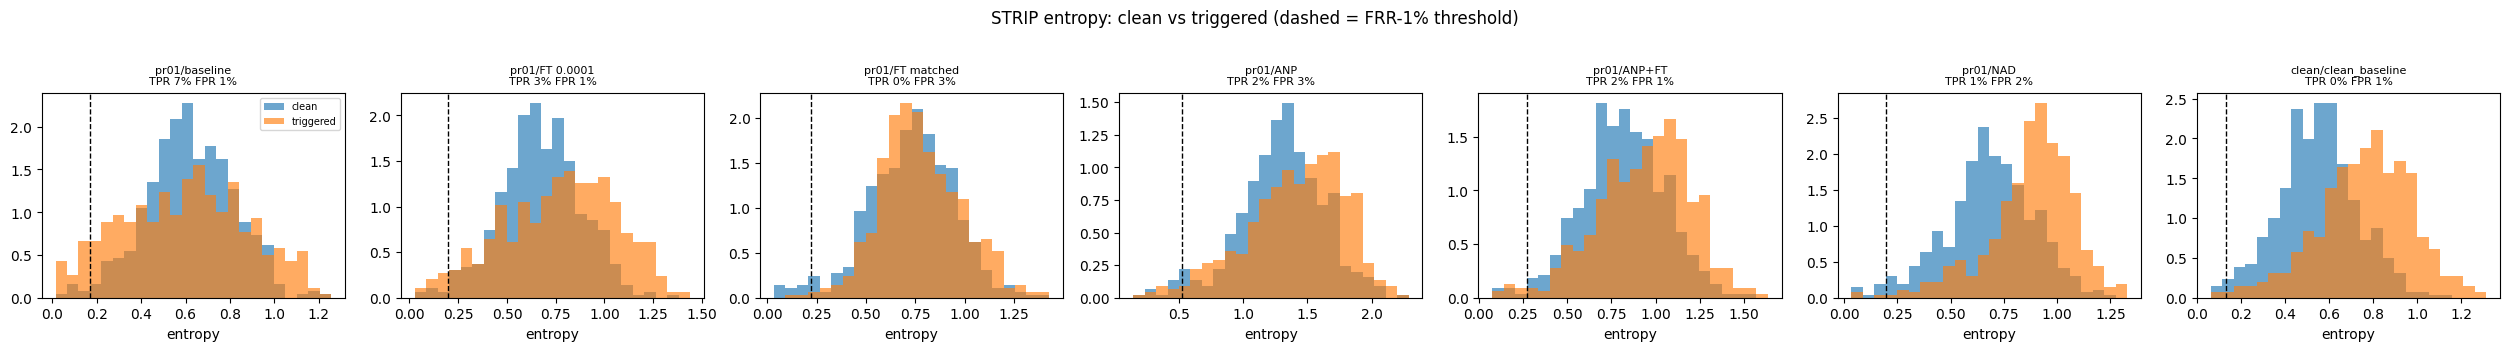

In [34]:
# ════════════════════════════════════════════════════════════════════════
# Cell H5 — STRIP entropy distributions before / after (with thresholds) + clean-model control
# ════════════════════════════════════════════════════════════════════════
_vt = verify_df[(verify_df.pr_tag == VIZ_TAG) | (verify_df.pr_tag == 'clean')]
fig, axs = plt.subplots(1, len(_vt), figsize=(3.6 * len(_vt), 3.4), squeeze=False)
for ax, (_, r) in zip(axs[0], _vt.iterrows()):
    e = np.load(f"{SUBDIRS['strip']}/strip_{r.pr_tag}_{r.variant}_entropies.npy"); l = np.load(f"{SUBDIRS['strip']}/strip_{r.pr_tag}_{r.variant}_labels.npy")
    bins = np.linspace(e.min(), e.max() + 1e-9, 25)
    ax.hist(e[l == 0], bins=bins, alpha=.65, label='clean', density=True); ax.hist(e[l == 1], bins=bins, alpha=.65, label='triggered', density=True)
    ax.axvline(r.STRIP_threshold, color='k', ls='--', lw=1)
    ax.set_title(f'{r.pr_tag}/{VARIANT_LABEL.get(r.variant, r.variant)}\nTPR {r.STRIP_TPR:.0f}% FPR {r.STRIP_FPR:.0f}%', fontsize=8); ax.set_xlabel('entropy');
axs[0, 0].legend(fontsize=7)
plt.suptitle('STRIP entropy: clean vs triggered (dashed = FRR-1% threshold)', y=1.02); plt.tight_layout()
plt.savefig(f"{SUBDIRS['fig']}/sk_viz_strip_hist.png", dpi=150, bbox_inches='tight'); plt.show()

## Section I — Metadata, cost, conclusions

In [35]:
# ════════════════════════════════════════════════════════════════════════
# Cell I1 — Metadata + compute-cost table
# ════════════════════════════════════════════════════════════════════════
metadata = {
    'attack': ATTACK_NAME, 'seed': SEED, 'target_class': TARGET_CLASS, 'source_class': SOURCE_CLASS, 'tags_run': TAGS,
    'protocol': {'n_val': N_VAL, 'n_select': N_SELECT, 'n_report': int(len(report_idx)), 'val_idx_hash': BL.state_hash({'v': torch.tensor(val_idx)}),
                 'defence_budget': 'validation half of the TEST set: train/select split; defense_indices.npy (train) NOT used',
                 'report_sets': {'CA': int(len(report_idx)), 'ASR_src': int(len(src_report)), 'ASR_all': int(len(all_report))}},
    'defender_knowledge': {'trigger_family': 'additive full-image', 'linf_budget': SK_LINF, 'true_trigger_used_by_defences': False,
                           'true_trigger_used_for_selection': 'none (ANP rule val_ca); ORACLE-VAL numbers are reported separately as upper bounds only'},
    'operator_source': OPERATOR_SOURCE,
    'files': {'nad_py_sha256': NAD_SHA, 'baeraser_lite_py_sha256': BL_SHA, 'split_sha': SPLIT_SHA},
    'v3_1': {'anp_select_rule': ANP_SELECT_RULE, 'anp_select_ca_margin_pp': ANP_SELECT_CA_MARGIN_PP, 'anp_fine_grid': ANP_FINE_GRID, 'ca_select_margin': CA_SELECT_MARGIN,
             'ft_early_stop': FT_EARLY_STOP, 'ft_patience': FT_PATIENCE, 'anp_ft': dict(run=RUN_ANP_FT, epochs=ANP_FT_EPOCHS, lr=ANP_FT_LR),
             'gradcam': dict(n=N_GRADCAM, target='true_label', bootstrap=GRADCAM_BOOT), 'strip_n_samples': STRIP_N_SAMPLES, 'audit_seed_offset': AUDIT_SEED_OFFSET},
    'normaliser': {'mean': MEAN_T.tolist(), 'std': STD_T.tolist(), 'source': 'first 256 train images (SK get_normalizer)', 'injected_into': ['BL.CIFAR_MEAN/STD', 'nad.NORM_MEAN/STD']},
    'floor': {'ASR_src': FLOOR_SRC, 'ASR_all': FLOOR_ALL, 'controls': CONTROLS},
    'ft': dict(lrs=FT_LRS, primary=FT_PRIMARY_LR, epochs=FT_EPOCHS, wd=FT_WD, augment=FT_AUGMENT),
    'anp': dict(rule=ANP_SELECT_RULE, eps=ANP_EPS, steps=ANP_STEPS, alpha=ANP_ALPHA, lr=ANP_LR, iters=ANP_NB_ITER, augment=ANP_AUGMENT, max_ca_drop_pp=MAX_CA_DROP_PP),
    'nad': dict(teacher_lrs=NAD_TEACHER_LRS, student_lrs=NAD_STUDENT_LRS, beta_scales=NAD_BETA_SCALES, betas=NAD_BETAS, teacher_epochs=NAD_TEACHER_EPOCHS,
                epochs=NAD_EPOCHS, batch=NAD_BATCH, max_ca_drop=NAD_MAX_CA_DROP, teacher_asr_flag=NAD_TEACHER_ASR_FLAG),
    'baeraser': dict(recovery_cfg=SK_RECOVERY_CONFIG, strict_thr=RECOVERY_THRESHOLD, relaxed_thr=RELAXED_RECOVERY_THRESHOLD, fresh_select_k=FRESH_SELECT_K,
                     audit_cfg=AUDIT_CONFIG, uap_eps=UAP_EPS, max_epochs=UNLEARN_MAX_EPOCHS, warm_start=False, exclude_target=True),
    'strip': dict(n_samples=STRIP_N_SAMPLES, n_superimpose=STRIP_N_SUPERIMPOSE, frr=STRIP_FRR, split='report'),
    'v4_1': {'nad_recipe_version': NAD_RECIPE_VERSION, 'nad_sweep': 'notebook-cached (nad.run_nad once per cell, weights kept)',
             'nad_student_rule': 'among cells within the CA gate: largest beta_scale, then largest lr', 'nad_repro_check': NAD_REPRO_CHECK,
             'clean_defences': {'run': RUN_CLEAN_DEFENCES, 'clean_after': CLEAN_AFTER}, 'ac_group_by': list(AC_GROUP_BY),
             'poison_files': {t: (None if not POISON_FILES.get(t) else POISON_FILES[t][2]) for t in TAGS}},
    'quick_mode': QUICK, 'torch': torch.__version__, 'device': DEVICE,
}
json.dump(metadata, open(f"{SUBDIRS['log']}/sk_defense_metadata.json", 'w'), indent=2, default=to_py)
cost = master_df[master_df.variant.isin(PRIMARY_VARIANTS)][['pr_tag', 'variant', 'seconds', 'status']]
print(cost.pivot_table(index='pr_tag', columns='variant', values='seconds', aggfunc='first').round(0).to_string())
cost.to_csv(f"{SUBDIRS['csv']}/sk_defense_cost.csv", index=False)

variant    anp  anp_ft  baeraser  ft_lr1em04  ft_matched    nad
pr_tag                                                         
clean      NaN     NaN       NaN         NaN        38.0  256.0
pr01     750.0   772.0     216.0        18.0        38.0  256.0
pr05     749.0   771.0     216.0        15.0        38.0  256.0
pr10     749.0   772.0     312.0        53.0        39.0  256.0


In [36]:
# ════════════════════════════════════════════════════════════════════════
# Cell I2 — Auto-generated conclusions (numbers only; interpret before quoting)
# ════════════════════════════════════════════════════════════════════════
print('=' * 76); print('SILENT KILLER — DEFENCE CONCLUSIONS (report half; auto-generated)'); print('=' * 76)
print(f'Untouched clean-model floor ASR_src={FLOOR_SRC}. "Effective" = ≤ max(10%, reference+5pp), reference = the CLEAN model after the SAME defence '
      f'(available for: {sorted(CLEAN_AFTER) or "none → falls back to the floor"}); CA-drop budget {MAX_CA_DROP_PP}pp\n')
for _, r in prim.iterrows():
    if pd.isna(r.CA_after):
        print(f'  {r.pr_tag:6s} {VARIANT_LABEL.get(str(r.variant), r.variant):10s}: {r.status} — {r.notes}'); continue
    print(f'  {r.pr_tag:6s} {VARIANT_LABEL.get(str(r.variant), r.variant):10s}: ASR_src {r.ASR_src_before*100:5.1f}→{r.ASR_src_after*100:5.1f}%  CA {r.CA_before*100:.1f}→{r.CA_after*100:.1f}%  '
          f'[{r.verdict}]' + ('' if not r.notes else f' — {r.notes}'))
print('\nBefore quoting any number:')
print('  1. Reproduction gate passed (B3)?                    ', 'yes' if not len(baseline_df[baseline_df.reproduces == False]) else 'NO')
print('  2. NAD rows: valid_run and interpretable both True?   (else report as invalid / teacher ineffective)')
print('  3. BaEraser: strict vs relaxed recovery; clean-model control + fresh-audit/UAP columns (D4c, G2)')
print('  4. ASR_src (lead) vs ASR_all; distance to the clean-model floor, not to 0')
print('  5. Any row with report_ca_budget_violated=True must be reported as a budget violation (noisy 500-image selection slice)')
print('  6. Verdicts use the clean model under the same defence where D3b ran; read `residual_vs_clean_same_defence_pp`, not the drop from the poisoned baseline')
print('  7. FRESH_SELECT_K was', FRESH_SELECT_K, '(1 = smoke test). Re-run with 3 and the full RUN_TAGS list for the paper matrix')

SILENT KILLER — DEFENCE CONCLUSIONS (report half; auto-generated)
Untouched clean-model floor ASR_src=0.6773333333333333. "Effective" = ≤ max(10%, reference+5pp), reference = the CLEAN model after the SAME defence (available for: ['ft_matched', 'nad']); CA-drop budget 5.0pp

  clean  FT matched: ASR_src  67.7→ 10.9%  CA 92.5→89.9%  [CONTROL (no backdoor present) — what this defence does to the transfer ASR by itself] — matched to NAD recipe, lr=0.01
  clean  NAD       : ASR_src  67.7→ 24.8%  CA 92.5→87.7%  [CONTROL (no backdoor present) — what this defence does to the transfer ASR by itself] — teacher lr=0.01, student lr=0.01, beta×2.0; teacher ASR(val)=0.356
  pr01   FT 0.0001 : ASR_src  89.3→ 81.6%  CA 91.9→92.0%  [INEFFECTIVE]
  pr01   FT matched: ASR_src  89.3→ 45.5%  CA 91.9→89.7%  [INEFFECTIVE · defence ALSO cuts a clean model's transfer ASR by 57pp (generic, not backdoor removal)] — matched to NAD recipe, lr=0.01
  pr01   ANP       : ASR_src  89.3→ 85.7%  CA 91.9→89.1%  [INEFFEC